# M26 · Chaînes de Markov et équation de Bellman — solutions (notebook exécuté)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cemah2/workbookMaths/blob/main/chapitres/m26_markov_bellman/05_solutions.ipynb)

Les réponses des exercices, exécutées. Les démarches détaillées (le *pourquoi*, les erreurs fréquentes, les variantes) sont dans `05_solutions.md`. Les cellules marquées `answer` enregistrent les réponses vérifiées par `wbm.check` (`tools/build_answers.py`).

| Partie | ID | Titre | Type | ★ | ⏱️ |
|---|---|---|---|---|---|
| 0 | M26.1 à M26.9, M26.14 | Les exercices papier (vérification) | ✏️ 🔗 | | |
| A | M26.16 | La loi d'une chaîne après n pas, en convention ligne · `n_step_distribution` | 🔨 | ★ | 20 |
|  | M26.17 | La loi stationnaire par un système linéaire, et le refus d'une chaîne qui en a plusieurs · `stationary_distribution` | 🔨 | ★★ | 25 |
|  | M26.18 | Le système de Bellman d'une politique fixée, avec une fin possible (matrice sous-stochastique) et γ = 1 quand la fin est sûre · `bellman_linear_solve` | 🔨 | ★★ | 25 |
|  | M26.19 | Les itérés de l'opérateur de Bellman d'une politique fixée (Richardson de pas 1) · `bellman_fixed_point_iterates` | 🔨 | ★ | 20 |
|  | M26.20 | La loi stationnaire de trois façons, `np.linalg.eig` sur Pᵀ, `scipy.linalg.null_space` et la méthode de la puissance, sur le surfeur aléatoire d'un web de six pages | 📦 | ★ | 20 |
| B | M26.21 | Prédire la somme des lignes de (1 − γ)(I − γP)⁻¹, puis leur limite quand γ tend vers 1, et vérifier | 🔮 | ★ | 15 |
|  | M26.22 | Le biais du maximum par simulation : k fournisseurs de même qualité, n mesures chacun, le meilleur mesuré contre l'estimateur double | 🔬 | ★★ | 20 |
|  | M26.23 | La loi d'une chaîne au fil des pas depuis trois départs, et ‖μ_n − π‖₁ en échelle logarithmique contre \|λ₂\|ⁿ | 🎨 | ★ | 15 |
| C | M26.24 | Chasse à l'erreur : une matrice lue dans la mauvaise convention, une loi stationnaire non normalisée, un état final qui rapporte encore, γ = 1 sans fin | 🐛 | ★ | 25 |
|  | M26.25 | Un test de propriété : πP = π, et pour `bellman_fixed_point_iterates`, V_k − V tenu par γᵏ‖V₀ − V‖∞ et V = r + γPV pour la limite, sur des chaînes tirées au hasard | 🛠️ | ★ | 20 |
| D | M26.26 | Défi : estimer la valeur d'un état à 0,01 près en simulant l'arrêt géométrique (continuer avec la probabilité γ) et en sommant les récompenses sans actualisation, sous un budget de pas simulés | 🏆 | ★★★ | 30 |

In [1]:
# ⚙️ SETUP: run this cell first (on Colab or on your computer)
FAST_MODE = True  # True = quick version (a few seconds per cell); False = bigger experiments
SEED = 42

import os
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/cemah2/workbookMaths.git"
DRIVE_DIR = Path("/content/drive/MyDrive/workbookMaths")

try:
    import google.colab  # noqa: F401  (this module only exists on Colab)
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive

    drive.mount("/content/drive")
    subprocess.run(["git", "config", "--global", "--add", "safe.directory", str(DRIVE_DIR)])
    if not (DRIVE_DIR / ".git").exists():
        subprocess.run(["git", "clone", REPO_URL, str(DRIVE_DIR)], check=True)
    else:
        # Get the new chapters. Your own work only lives in mon_travail/, which Claude never
        # touches, so "rebase + autostash" keeps it safe (even with local commits).
        identity = subprocess.run(["git", "-C", str(DRIVE_DIR), "config", "user.email"],
                                  capture_output=True).returncode == 0
        who = [] if identity else ["-c", "user.name=Workbook", "-c", "user.email=workbook@localhost"]
        pull = subprocess.run(["git", *who, "-C", str(DRIVE_DIR), "pull", "--rebase", "--autostash"],
                              capture_output=True, text=True)
        conflicts = subprocess.run(["git", "-C", str(DRIVE_DIR), "diff", "--name-only", "--diff-filter=U"],
                                   capture_output=True, text=True).stdout.split()
        if conflicts:  # a file changed outside mon_travail/ AND by Claude: git leaves conflict markers in it
            print("⚠️ Tes modifications de " + ", ".join(conflicts) + " (hors de mon_travail/) entrent en conflit "
                  "avec la nouvelle version ; elles sont gardées dans `git stash`. Pour reprendre la version du "
                  "dépôt : git restore --source=HEAD --staged --worktree <fichier> (00_setup/COLAB.md, « Problèmes "
                  "fréquents »).")
        elif pull.returncode != 0:
            print("⚠️ git pull a échoué (voir 00_setup/COLAB.md, « Problèmes fréquents ») :\n" + pull.stderr)
    ROOT = DRIVE_DIR
else:
    ROOT = Path(os.environ.get("WBM_ROOT", Path.cwd())).resolve()
    while not (ROOT / "src" / "wbm").exists() and ROOT != ROOT.parent:
        ROOT = ROOT.parent
    if not (ROOT / "src" / "wbm").exists():
        raise FileNotFoundError("Dépôt introuvable : ouvre ce notebook depuis le dossier de workbookMaths.")

os.environ["WBM_ROOT"] = str(ROOT)
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

import wbm  # noqa: E402

cfg = wbm.setup(seed=SEED, fast=FAST_MODE)
FAST_MODE = cfg.fast
mymath = wbm.load_mymath("ref")  # reference implementation

🧪 workbookMaths : environnement
   Plateforme : Local (Linux x86_64, 2 CPU)
   Python 3.13.18 | numpy 2.1.3 | scipy 1.16.3 | sympy 1.14.0 | matplotlib 3.10.0 | pandas 2.2.3 | scikit-learn 1.6.1
   Graine : 42 | FAST_MODE : True


## Objectifs et rappel express

- Vérifier tes calculs papier (partie 0) : une loi à n pas et un coût moyen, une loi stationnaire et trois chaînes qui posent problème, l'analyse au premier pas, une durée géométrique, deux systèmes de Bellman et la valeur d'une action, leurs itérés, un arrêt optimal, le biais du maximum, et un pont vers les tableaux à trois axes.
- Écrire les quatre fonctions de `mymath/markov.py` (`n_step_distribution`, `stationary_distribution`, `bellman_linear_solve`, `bellman_fixed_point_iterates`) et les tester.
- Calculer un PageRank de trois façons, prédire la loi d'occupation actualisée, simuler le biais du maximum, dessiner l'oubli du départ, corriger quatre erreurs classiques, écrire un test de propriété, et relever un défi.

**Rappel express.** Une loi est une ligne : $\boldsymbol{\mu}_{n+1} = \boldsymbol{\mu}_n\mathbf{P}$, $\boldsymbol{\mu}_n = \boldsymbol{\mu}_0\mathbf{P}^n$ ; une fonction est une colonne : $\mathbb{E}[f(S_1) \mid S_0 = i] = (\mathbf{P}\mathbf{f})_i$. Loi stationnaire : $\boldsymbol{\pi}\mathbf{P} = \boldsymbol{\pi}$, $\sum_j\pi_j = 1$ (le système $(\mathbf{P}^\top - \mathbf{I})\boldsymbol{\pi}^\top = \mathbf{0}$, sa dernière équation remplacée par la somme) ; écart en $\lvert\lambda_2\rvert^n$. Premier pas : $\mathbf{h} = \mathbf{Q}\mathbf{h} + \mathbf{b}$, $\mathbf{t} = \mathbf{1} + \mathbf{Q}\mathbf{t}$. Bellman : $(\mathbf{I} - \gamma\mathbf{P})\mathbf{V} = \mathbf{r}$, inversible pour $\gamma < 1$, et pour $\gamma = 1$ si la fin est sûre ; $(1 - \gamma)(\mathbf{I} - \gamma\mathbf{P})^{-1}$ est stochastique. Itérés : $\mathbf{V}_{k+1} = \mathbf{r} + \gamma\mathbf{P}\mathbf{V}_k$, $\lVert\mathbf{V}_k - \mathbf{V}\rVert_\infty \le \gamma^k\lVert\mathbf{V}_0 - \mathbf{V}\rVert_\infty$ et $\le \frac{\gamma}{1 - \gamma}\lVert\mathbf{V}_k - \mathbf{V}_{k-1}\rVert_\infty$. Arrêt géométrique : continuer avec la probabilité $\gamma$ et sommer sans actualiser donne $V$ en moyenne. Biais du maximum : $\mathbb{E}[\max_i\hat{X}_i] \ge \max_i\mathbb{E}[\hat{X}_i]$ ; l'estimateur double choisit sur un échantillon et mesure sur l'autre.

## Partie 0 · Vérifier tes exercices papier (✏️ M26.1 à M26.9 ; 🔗 M26.14)

Fais d'abord les exercices de `02_exercices.md` **sur papier**, dans ta copie de `06_mes_reponses.md`. Reporte ensuite chaque réponse ici : **la valeur** que tu as trouvée, sous la forme indiquée en commentaire, jamais le calcul qui y mène :
- un entier, ou un nombre avec un point décimal, `-1.25`, arrondi comme le demande la question (« exact values » : tous les chiffres, ces calculs tombent juste) ;
- une liste `[0.2, -1]` ; une matrice comme la liste de ses **lignes**, `[[1, 0], [-2, 3]]` ;
- une fraction irréductible entre guillemets, `"3/7"`, quand la question le dit ;
- une **forme** comme un tuple, `(7, 2)`, ou comme un texte, `"(7, 2)"` ;
- `True` ou `False` pour un vrai ou faux.

Les réponses pas encore remplies affichent ⏳.

In [2]:
# Part 0: the answers are computed from the statements (exact fractions for the linear algebra, math for M26.9)
import math
from fractions import Fraction as F

import numpy as np


def exact(values):
    """Decimal numbers written in the statement (0.35), as exact fractions (7/20), in a vector or a matrix."""
    if isinstance(values, (list, tuple)):
        return [exact(v) for v in values]
    return F(str(values))


def floats(values):
    """A number, a vector or a matrix of exact values (fractions) as a float or nested lists of floats."""
    return np.asarray(values, dtype=float).tolist()


def shape_of(shape):
    """A shape (a tuple, or that of an array) written as NumPy prints it: "(3, 4)"."""
    shape = np.shape(shape) if hasattr(shape, "shape") else shape
    return str(tuple(int(n) for n in shape))


def dot(u, v):
    return sum(a * b for a, b in zip(u, v))


def minus(u, v):
    return [a - b for a, b in zip(u, v)]


def sup_norm(x):
    return max(abs(v) for v in x)


def transpose(A):
    return [list(row) for row in zip(*A)]


def matmul(A, B):
    """The product of two matrices of fractions (lists of rows)."""
    return [[sum(A[i][k] * B[k][j] for k in range(len(B))) for j in range(len(B[0]))] for i in range(len(A))]


def vecmat(mu, A):
    """A row times a matrix: the law convention, μP."""
    return [sum(mu[i] * A[i][j] for i in range(len(mu))) for j in range(len(A[0]))]


def matvec(A, f):
    """A matrix times a column: the function convention, Pf."""
    return [sum(A[i][j] * f[j] for j in range(len(f))) for i in range(len(A))]


def solve(A, b):
    """The solution of A x = b in fractions (Gauss-Jordan elimination; A square and invertible)."""
    n = len(A)
    M = [list(A[i]) + [b[i]] for i in range(n)]
    for col in range(n):
        pivot = next(r for r in range(col, n) if M[r][col] != 0)
        M[col], M[pivot] = M[pivot], M[col]
        M[col] = [x / M[col][col] for x in M[col]]
        for r in range(n):
            if r != col and M[r][col] != 0:
                M[r] = [x - M[r][col] * y for x, y in zip(M[r], M[col])]
    return [M[i][n] for i in range(n)]


def stationary(P):
    """π P = π and Σ π = 1, in fractions: the system (Pᵀ − I) πᵀ = 0, its last equation replaced by Σ π_j = 1."""
    n = len(P)
    A = [[P[j][i] - (i == j) for j in range(n)] for i in range(n)]
    A[-1] = [F(1)] * n
    return solve(A, [F(0)] * (n - 1) + [F(1)])


def bellman(P, r, gamma):
    """The solution of (I − γP) V = r, in fractions."""
    n = len(P)
    return solve([[(i == j) - gamma * P[i][j] for j in range(n)] for i in range(n)], list(r))


ONES_3 = [F(1)] * 3
P_1 = exact([[0.6, 0.3, 0.1], [0.3, 0.4, 0.3], [0.4, 0.2, 0.4]])        # M26.1: the stations A, B, C
MU0_1 = [F(80, 200), F(80, 200), F(40, 200)]                             # 80, 80 and 40 bikes out of 200
F_1 = exact([0.4, 0.8, 2])                                               # the recharge (€)
P2_1 = matmul(P_1, P_1)
MU_1, COLUMN_1 = [MU0_1], [MU0_1]                                        # μ0, μ1, ..., μ4; and Pⁿ μ0 (wrong)
for _ in range(4):
    MU_1.append(vecmat(MU_1[-1], P_1))
    COLUMN_1.append(matvec(P_1, COLUMN_1[-1]))
PF_1 = matvec(P_1, F_1)
P_2 = exact([[0.9, 0.05, 0.05], [0.05, 0.85, 0.1], [0.2, 0.15, 0.65]])  # M26.2: Azur, Boréal, Cobalt
SHARES_2 = exact([0.45, 0.4, 0.15])
PI_2 = stationary(P_2)
P_FERRY_3 = exact([[0, 0, 0.7, 0.3], [0, 0, 0.35, 0.65], [0.9, 0.1, 0, 0], [0.3, 0.7, 0, 0]])   # M26.3: A, B, C, D
PI_FERRY_3 = stationary(P_FERRY_3)
TWO_CROSSINGS_3 = matmul(P_FERRY_3, P_FERRY_3)
EVEN_LIMIT_3 = stationary([row[:2] for row in TWO_CROSSINGS_3[:2]]) + [F(0), F(0)]   # the even steps, from A
ODD_LIMIT_3 = vecmat(EVEN_LIMIT_3, P_FERRY_3)                                       # one more crossing
P_SITE_3 = exact([[0.8, 0.2, 0, 0], [0.35, 0.65, 0, 0], [0, 0, 0.55, 0.45], [0, 0, 0.3, 0.7]])
PI_FR_3 = stationary([row[:2] for row in P_SITE_3[:2]])
PI_EN_3 = stationary([row[2:] for row in P_SITE_3[2:]])


def mix_3(w_fr, w_en):
    """w_fr π_FR + w_en π_EN, each completed by zeros."""
    return [w_fr * x for x in PI_FR_3] + [w_en * x for x in PI_EN_3]


P_TRIAL_3 = exact([[0.4, 0.45, 0.15], [0, 0.9, 0.1], [0, 0.4, 0.6]])
CLOSED_3 = stationary([row[1:] for row in P_TRIAL_3[1:]])                # the closed class {regular, occasional}
Q_4 = exact([[0.15, 0.7, 0], [0.05, 0.15, 0.75], [0, 0, 0.15]])          # M26.4: L1, L2, L3
B_4, DROP_4, FEES_4 = exact([0, 0, 0.75]), exact([0.15, 0.05, 0.1]), [F(170), F(170), F(240)]
IQ_4 = [[(i == j) - Q_4[i][j] for j in range(3)] for i in range(3)]      # I − Q
NO_RETURN_4 = [list(row) for row in Q_4]
NO_RETURN_4[1][0] = F(0)                                                 # (wrong) the reorientations forgotten
IQ_NO_RETURN_4 = [[(i == j) - NO_RETURN_4[i][j] for j in range(3)] for i in range(3)]
H_4, T_4 = solve(IQ_4, B_4), solve(IQ_4, ONES_3)
N_ROW_4 = solve(transpose(IQ_4), [F(1), F(0), F(0)])                     # n (I − Q) = (1, 0, 0)
G_5, FEE_5 = F(7, 10), F(9)                                              # M26.5


def below_5(strict=True):
    """P(9 (N + 1) < the mean 9 / (1 − γ)) (strict=False: one more month counted, the first at or above the mean)."""
    months = [m for m in range(1, 200) if FEE_5 * m < FEE_5 / (1 - G_5)]
    months += [] if strict else [max(months) + 1]
    return sum((1 - G_5) * G_5 ** (m - 1) for m in months)


G_6 = F(3, 5)                                                            # M26.6: new (0), worn (1), broken (2)
ROW_NEW_6, ROW_CONT_6 = exact([0.7, 0.3, 0]), exact([0, 0.65, 0.35])
ROW_MAINT_6, ROW_BROKEN_6 = exact([0.95, 0, 0.05]), exact([0.8, 0, 0.2])
R_CONT_6 = ROW_CONT_6[1] * 6 + ROW_CONT_6[2] * 3                         # r(1, continuer) = Σ_s′ P r(1, continuer, s′)
PA_6, RA_6 = [ROW_NEW_6, ROW_CONT_6, ROW_BROKEN_6], [F(10), R_CONT_6, F(-8)]
PB_6, RB_6 = [ROW_NEW_6, ROW_MAINT_6, ROW_BROKEN_6], [F(10), F(2), F(-8)]
VA_6, VB_6 = bellman(PA_6, RA_6, G_6), bellman(PB_6, RB_6, G_6)


def q_6(row, reward, V):
    """r(s, a) + γ Σ_s′ P_a(s, s′) V(s′)."""
    return reward + G_6 * dot(row, V)


def sweeps_7(in_place, gamma=G_6, n=4):
    """V_0 = 0, then n synchronous steps (in_place=False) or n in-place sweeps of the machine under π_A."""
    V, out = [F(0)] * 3, [[F(0)] * 3]
    for _ in range(n):
        new = list(V)
        for i in range(3):
            new[i] = RA_6[i] + gamma * dot(PA_6[i], new if in_place else V)
        V = new
        out.append(V)
    return out


SYNC_7, IN_PLACE_7, NO_GAMMA_7 = sweeps_7(False), sweeps_7(True), sweeps_7(False, gamma=F(1))
EPS_7 = F(1, 1000)
K_REAL_7 = math.log(1e-3 / float(sup_norm(VA_6))) / math.log(0.6)       # 0.6ᵏ ‖V^{π_A}‖∞ ≤ 10⁻³
OFFERS_8, PROBS_8, C_8, G_8 = [3000, 4000, 5000, 7000], exact([0.3, 0.3, 0.2, 0.2]), F(-50), F(17, 20)   # M26.8


def rule_8(accepted, c=C_8, gamma=G_8):
    """The value of continuation of the rule that accepts the offers of `accepted`: C = c + γ E[gain of the rule]."""
    gain = sum(p * x for p, x in zip(PROBS_8, OFFERS_8) if x in accepted)
    refused = sum(p for p, x in zip(PROBS_8, OFFERS_8) if x not in accepted)
    return (c + gamma * gain) / (1 - gamma * refused)


def optimal_8(c=C_8, gamma=G_8):
    """C = c + γ E[max(X, C)], solved interval by interval: (C*, the offers accepted)."""
    for k in range(len(OFFERS_8)):
        C = rule_8(OFFERS_8[k:], c, gamma)
        if all(x >= C for x in OFFERS_8[k:]) and all(x < C for x in OFFERS_8[:k]):
            return C, OFFERS_8[k:]


CSTAR_8, ACCEPT_8 = optimal_8()
S0_9, NA_9, NB_9, MEAN_A_9, MEAN_B_9 = 30.0, 16, 9, 1010.0, 1000.0      # M26.9
SA_9, SB_9 = S0_9 / math.sqrt(NA_9), S0_9 / math.sqrt(NB_9)
SD_9, DELTA_9 = math.sqrt(SA_9 ** 2 + SB_9 ** 2), MEAN_A_9 - MEAN_B_9


def phi_9(x):
    """The distribution function Φ of N(0, 1)."""
    return 0.5 * (1 + math.erf(x / math.sqrt(2)))


def abs_mean_9(delta, s, shift=True):
    """E|D| for D ~ N(delta, s²), by the formula of the statement (shift=False: its second term forgotten)."""
    return (s * math.sqrt(2 / math.pi) * math.exp(-delta ** 2 / (2 * s ** 2))
            + (delta * (1 - 2 * phi_9(-delta / s)) if shift else 0.0))


def chosen_9(p_b):
    """The true mean life of the supplier chosen, when B is chosen with the probability p_b."""
    return (1 - p_b) * MEAN_A_9 + p_b * MEAN_B_9


P_14 = [exact([[0.9, 0.1, 0], [0.3, 0.4, 0.3], [0, 0, 1]]),               # M26.14: P[a][s][s2], a = nothing, discount
        exact([[0.95, 0.05, 0], [0.55, 0.35, 0.1], [0, 0, 1]])]
R_14 = [[[F((30, 21)[a]) if s < 2 and t < 2 else F(0) for t in range(3)] for s in range(3)] for a in range(2)]
PI_14, SWAPPED_14 = exact([[1, 0], [0.6, 0.4], [1, 0]]), exact([[1, 0], [0.4, 0.6], [1, 0]])
G_14 = F(17, 20)
RSA_14 = [[sum(P_14[a][s][t] * R_14[a][s][t] for t in range(3)) for s in range(3)] for a in range(2)]


def induced_14(policy):
    """(P_π, r_π) of the policy policy[s][a]."""
    P = [[sum(policy[s][a] * P_14[a][s][t] for a in range(2)) for t in range(3)] for s in range(3)]
    return P, [sum(policy[s][a] * RSA_14[a][s] for a in range(2)) for s in range(3)]


PPI_14, RPI_14 = induced_14(PI_14)
V_14 = bellman(PPI_14, RPI_14, G_14)

**Ex M26.1 — Des vélos en libre-service entre trois stations : loi après deux et trois jours, et coût moyen du lendemain**

In [3]:
wbm.record("M26.1a", floats(P2_1[1][2]), decimals=2,
           mistakes={"la puissance d'une matrice n'est pas la puissance de chaque coefficient : (P²)_BC est une somme "
                     "sur les chemins de B à C": floats(P_1[1][2] ** 2),
                     "la ligne est la station de départ, la colonne celle d'arrivée": floats(P2_1[2][1])})
wbm.record("M26.1b", floats(MU_1[2]), decimals=3,
           mistakes={"deux jours font deux pas : μ₂ = μ₀P²": floats(MU_1[1]),
                     "une loi est une ligne : elle avance par μP, pas par Pμ": floats(COLUMN_1[2])})
wbm.record("M26.1c", floats(MU_1[3]), decimals=4,
           mistakes={"une loi est une ligne : elle avance par μP, pas par Pμ (et la somme doit rester 1)":
                         floats(COLUMN_1[3]),
                     "trois jours font trois pas à partir de μ₀, pas quatre": floats(MU_1[4])})
wbm.record("M26.1d", floats(200 * MU_1[3][2]), decimals=2,
           mistakes={"le nombre moyen est 200 fois la probabilité d'être en C au troisième jour, pas au deuxième":
                         floats(200 * MU_1[2][2])})
wbm.record("M26.1e", floats(PF_1), decimals=2,
           mistakes={"une fonction des états est une colonne : (Pf)_i = Σ_j p_ij f(j), une moyenne sur la ligne de "
                     "départ": floats(matvec(transpose(P_1), F_1))})
wbm.record("M26.1f", floats(200 * dot(MU0_1, PF_1)), decimals=2,
           mistakes={"le coût de ce soir dépend de la station de ce soir : il y a un pas de la chaîne entre ce matin et "
                     "ce soir": floats(200 * dot(MU0_1, F_1)),
                     "pondère les coûts moyens Pf par la répartition des vélos ce matin": floats(200 * sum(PF_1) / 3)})

WBM_ANSWER {"decimals": 2, "hash": "3a590873324e8fdca199c80efb3b738a1f50744bcc697cd73b50f088cf590617", "hash_coarse": "f9fd6af3121c09f5f5855f391fcd50196c1cc6154c7722ad9269421a2853374d", "id": "M26.1a", "kind": "float", "magnitude": -1, "mistakes": {"393a2cce2c6d2ee5481dcceba646cc13f63c470a45ef216db505536b385e0e9b": "la puissance d'une matrice n'est pas la puissance de chaque coefficient : (P²)_BC est une somme sur les chemins de B à C", "e9eccbf58e6a00beaaa07566b8bfae767e01fcc2af074bf6ca54ad77c9f0ec4b": "la ligne est la station de départ, la colonne celle d'arrivée"}, "sign": 1}
📝 Ex M26.1a : réponse enregistrée (float, 2 décimales).
WBM_ANSWER {"decimals": 3, "element_coarse": [["3f3462023daff60b45f6b3b475497be0325a219987d12527bb80e459a7fd355a"], ["597eeb938a2939345833c9b12f6b97f0f9d88b202c19162489db4538cbe97b30"], ["7082528491a1191eaed727d38325579efbf5182b4127364b1c171dca21c6d1c2"]], "element_coarse_any": [["1ee1691050bc0413fe87a00c51161113560341438f5db38dbdafe989a0443568"], ["5ebcad

**Ex M26.2 — Trois opérateurs et leurs parts de marché : la loi stationnaire par un système linéaire**

In [4]:
wbm.record("M26.2a", floats(PI_2), decimals=4,
           mistakes={"π est un vecteur propre à gauche : πP = π, c'est-à-dire Pᵀπᵀ = πᵀ ; à droite, P a le vecteur 1, qui "
                     "ne dit rien": floats(stationary(transpose(P_2))),
                     "une loi stationnaire est une loi : ses coordonnées ont pour somme 1":
                         floats([x / PI_2[0] for x in PI_2])})
wbm.record("M26.2b", str(PI_2[2]), kind="fraction", simplified=True,
           mistakes={"π est un vecteur propre à gauche (πP = π), normalisé : ce n'est pas la loi uniforme":
                         str(stationary(transpose(P_2))[2])})
wbm.record("M26.2c", floats(vecmat(SHARES_2, P_2)), decimals=4,
           mistakes={"une loi avance par μP (la ligne à gauche), pas par Pμ": floats(matvec(P_2, SHARES_2))})
wbm.record("M26.2d", str(PI_2[2] * P_2[2][0] / PI_2[0]), kind="fraction", simplified=True,
           mistakes={"la question porte sur les clients d'Azur : c'est une proportion parmi eux, pas parmi tous les "
                     "clients": str(PI_2[2] * P_2[2][0]),
                     "p_CA est la probabilité de passer de Cobalt à Azur, pas celle d'avoir été chez Cobalt sachant qu'on "
                     "est chez Azur (règle de Bayes)": str(P_2[2][0])})
wbm.record("M26.2e", bool(PI_2[0] * P_2[0][1] == PI_2[1] * P_2[1][0]), mistakes={"compare les deux flux π_Azur p_AB et π_Boréal p_BA": True})

WBM_ANSWER {"decimals": 4, "element_coarse": [["93df281560dcac9f70a07bc5717bf8f00705f9eab0d7307990be19ed76e33dfe"], ["1aad8e2398648c3aba7c6959b74b68e954e8fba9da7b768ab25a2820d18d5235"], ["27083819157b61f68c246882b83e876b096edea80db6a1e0c114a28b2f5a6a0d"]], "element_coarse_any": [["75e47fa831712f53034a9f4df1974d79ecbe90c9dde4328bcf3fa5e91772429a", "3b29006350108917ebc5fcab78a90654ed4116086ff41a00b070449068ae6136"], ["6f30bc3a1a2768c02c1fa5f31f6627af9029a244118c4d2f5778401ad0e361e8", "0a9442b7a035016e327633b1711abd7daf9f0933846fb7b2812210bb9af1c4b8"], ["10bebbfe6b02c09baa943fc279e40bc7e47813bae9e5ab016e91851510005fbf", "95acdbcad8f5d7edb9045aaa3dd03cb67996f884c5377001e354469642ffd4df"]], "element_hashes": ["87539067c6f0d69c4787b3a02428ec218d48ed4088ec64ec6b8763602c221f00", "5d1656c4f971cf363aba16dd6ea76a38ade9ab25c0132504c298cbb82a83e26b", "90e394a5db915cc54f8fcbdd8e67708a57ff8ca7e6873ef1c2d0dfc2a13de093"], "hash": "7ad4db7d997efabb5de7b170f837848f90e1986987f75df573253495de68f62f", "id":

WBM_ANSWER {"hash": "7fd1b65fff01478c7ea40317031ecf7c615bd5ff0a752cfdcba56f82dc7383be", "id": "M26.2b", "kind": "fraction", "mistakes": {"6fc91b488c913422f5912b8d4e75866c45761b7ae83599c272bc67fcf0ce27e3": "π est un vecteur propre à gauche (πP = π), normalisé : ce n'est pas la loi uniforme"}, "sign": 1, "simplified": true}
📝 Ex M26.2b : réponse enregistrée (fraction).
WBM_ANSWER {"decimals": 4, "element_coarse": [["670c29b635c4bb05c275b6e901dd1cd5e8d68c079f1efc3d612b56427dc8bf54"], ["2f586d49a1fd53aa93e720f753ad6f2d04ac25bac2c444fec8fb1578f2324753"], ["3b4c05160b87731fb6849d526ed061894b6e696d1c3888b9d35ec918070d2c04"]], "element_coarse_any": [["8c96d51047734a8bdde9e9baaa0666823b9a0bb3b6ae3fd623939bc4669ea780", "b512d814018c5dc75dfdb491f7ee999c6879eaaa1c4a1a6cf919888d55987064"], ["23f3f0a31c26c6f353a228b3025dd89125bf530a57f4e9bd8f253cf54e795915", "7ff0dfeb95fa56e06e4b32e6fe55531c6d5b738f1c520ab9c60997a99b7ec392"], ["31c8b3b15eb2630b3e8b5c9a7c708249d83dc1482740a73fb13483feda045705", "1392

**Ex M26.3 — Trois chaînes qui posent problème : un bac, un site bilingue, une période d'essai**

In [5]:
wbm.record("M26.3a", floats(PI_FERRY_3), decimals=4,
           mistakes={"la loi stationnaire charge aussi les ports du sud : la moitié de la masse au nord, l'autre au sud":
                         floats(EVEN_LIMIT_3),
                     "la loi stationnaire n'est uniforme que si les colonnes de P ont aussi pour somme 1":
                         floats(stationary(transpose(P_FERRY_3)))})
wbm.record("M26.3b", floats(EVEN_LIMIT_3), decimals=4,
           mistakes={"la question porte sur les pas pairs seulement, depuis A : regarde où peut être le bac après 2, 4, 6 "
                     "traversées": floats(PI_FERRY_3),
                     "après un nombre pair de traversées, le bac est revenu sur sa rive de départ ; aux pas impairs, il "
                     "est sur l'autre": floats(ODD_LIMIT_3)})
wbm.record("M26.3c", False, mistakes={"regarde sur quelle rive peut être le bac aux pas pairs, puis aux pas impairs": True})
wbm.record("M26.3d", floats(mix_3(F(3, 5), F(2, 5))), decimals=4,
           mistakes={"chaque classe garde la masse qui y arrive : pondère chaque loi stationnaire par la probabilité "
                     "d'arriver dans sa classe": floats(mix_3(F(2, 5), F(3, 5))),
                     "la limite dépend du départ : elle ne met pas la moitié de la masse dans chaque classe":
                         floats(mix_3(F(1, 2), F(1, 2)))})
wbm.record("M26.3e", bool(vecmat(mix_3(F(1, 2), F(1, 2)), P_SITE_3) == mix_3(F(1, 2), F(1, 2))), mistakes={"calcule ½(π_FR + π_EN)P en utilisant la linéarité de π ↦ πP": False})
wbm.record("M26.3f", floats([F(0)] + CLOSED_3), decimals=4,
           mistakes={"dans le bloc fermé, la masse va surtout à l'état qu'on quitte le moins : compare 0,1 et 0,4":
                         floats([F(0)] + CLOSED_3[::-1])})

WBM_ANSWER {"decimals": 4, "element_coarse": [["8bd9588c74b74fa6c10ece32f2ab98ffedfa82512914cc6a133b55afc5d051f5"], ["9f385a72e9cce4fb18cdcdea79fd18312cd08dee5de2ea3244fc88ef4b692c7a"], ["876d19a2a978d0eb53466ce1172b1b21837497b464509592ba0673a047313241"], ["cc747fa6b97631b0780ab2a147e382c2ceed63c395c07a99ec7293a9e64e5d5d"]], "element_coarse_any": [["43886d39752cb0b54ca46dcc9a7dde3ca988a6ca1095e7ffbd043110312dbc0c", "274c5db84a3baeb0a257f2a71a6f47e4558d4aa65974d3410f9e2761a4b58766"], ["845837852ce550c95fb9186ef333ee0851d44958a8d5e895af9c9589916eabba", "678ffe5b1a9e530cc87f381895b527941122e6e3c70f9eeaa8e4c7942d5c2e88"], ["b758c18bb7936af63ace298758eedb4a12f1e932955edd04f3550525a6e4cdcd", "10930335c01d2a6fa7716da1aa64943a3609fc027b50ce7a8e4f45d411a4b3ca"], ["cb2d156f19e34622fc5fad8ac545147b59ef845cc86a72a4cb39d2cd0beb8557", "c21b91bf080d092cb4e3f14590ce35b1af7591d2d95681bc582a06a7191d2353"]], "element_hashes": ["979070afe006df7651387c994413c5a6a3c8a43134d81f07d6b759fe4b2eb74d", "77e65ff4c

**Ex M26.4 — Un cursus en trois années : la probabilité d'être diplômé et la durée moyenne des études**

In [6]:
wbm.record("M26.4a", floats(H_4), decimals=3,
           mistakes={"les réorientations de L2 vers L1 font partie de Q : un étudiant réorienté peut encore être diplômé":
                         floats(solve(IQ_NO_RETURN_4, B_4)),
                     "h est la probabilité d'atteindre « diplômé » : b est la colonne de cet état, pas celle de "
                     "l'abandon": floats(solve(IQ_4, DROP_4))})
wbm.record("M26.4b", str(H_4[0]), kind="fraction", simplified=True,
           mistakes={"les réorientations de L2 vers L1 font partie de Q": str(solve(IQ_NO_RETURN_4, B_4)[0])})
wbm.record("M26.4c", floats(T_4), decimals=2,
           mistakes={"t = 1 + Qt : l'année en cours compte, et la sortie (diplôme ou abandon) n'ajoute pas d'année":
                         floats([t + 1 for t in T_4]),
                     "les réorientations de L2 vers L1 font partie de Q, et des durées":
                         floats(solve(IQ_NO_RETURN_4, ONES_3))})
wbm.record("M26.4d", floats(N_ROW_4[0]), decimals=2,
           mistakes={"un étudiant réorienté revient en L1 : N compte aussi ces retours":
                         floats(solve(transpose(IQ_NO_RETURN_4), [F(1), F(0), F(0)])[0])})
wbm.record("M26.4e", floats(dot(N_ROW_4, FEES_4)), decimals=2,
           mistakes={"les frais dépendent du niveau : pondère par le nombre moyen d'années dans chaque niveau (la ligne "
                     "L1 de N)": floats(FEES_4[0] * T_4[0]),
                     "chaque année d'études se paie, redoublements et retours compris : utilise N, pas une seule année "
                     "par niveau": floats(sum(FEES_4))})

WBM_ANSWER {"decimals": 3, "element_coarse": [["e1ff40444b7619806d8f4fd1accb89bf69440ab1bd8359c37689b8c98f935baa"], ["ff1de0360e210c08f20d61a2fcccb66667ca8e5923cf6f6bb938ca26204199f8"], ["46fcadde40793bec87c8d2eabcadbae1603ae77f43a4b48d67a03ca9fb28a568"]], "element_coarse_any": [["4ba5b224a5b819d636de5391320751cf5a91a688887606984fbf8b18eee5568a", "5f50233d62b83a23fb8936c3685f898ca6aa34d039a596720315c852f44e3d07"], ["f8d8513e63d97077d4f8adfdf436f84a4d2856ebf117dcd049762b3a61c45e7c", "afc2a6f4292f7747f10cba09ff2855c2ee75203a48d7986e6591fe68fb263868"], ["9449b85deb9a5603be5bc80e87122b0000e979c4aa7a8b881683775627aaa0d5", "16ad29e2cc621239bec229368275aefd9c0c9d6052a1f4d66987929d43ce6774"]], "element_hashes": ["e96fdbdad2c7ccb569ba8ac1ca7ff63942d87e9620d5ca58c0c164d81edca1a7", "857b7504c013a9d0b837e529c1e2c3fe9beafce188c22a6ebc375edd3e3acaa3", "e719120ccef00c8501854d8096260bab1f18d19afa29c883bd80b2cf395c54e8"], "hash": "52a7e98e09e6d4346de5ec9c7936b57160a96b971a7a68b1cf15f71a0d4633c4", "id":

**Ex M26.5 — Un abonné qui peut résilier chaque mois : durée géométrique, revenu total moyen et revenu actualisé**

In [7]:
wbm.record("M26.5a", floats(G_5 ** 5), decimals=4,
           mistakes={"le premier mois est toujours payé : payer le 6ᵉ demande 5 renouvellements": floats(G_5 ** 6),
                     "la question demande s'il paie le 6ᵉ mois, pas si le 6ᵉ est son dernier":
                         floats(G_5 ** 5 * (1 - G_5))})
wbm.record("M26.5b", str(1 / (1 - G_5)), kind="fraction", simplified=True,
           mistakes={"le premier mois compte : l'abonné paie N + 1 mois, pas N": str(G_5 / (1 - G_5)),
                     "le paramètre d'une loi géométrique est la probabilité de s'arrêter à chaque mois, pas celle de "
                     "continuer": str(1 / G_5)})
wbm.record("M26.5c", floats(FEE_5 / (1 - G_5)), decimals=2,
           mistakes={"chaque mois commencé est payé, le premier compris": floats(FEE_5 * G_5 / (1 - G_5))})
wbm.record("M26.5d", floats(FEE_5 / (1 - G_5)), decimals=2,
           mistakes={"le premier versement a lieu aujourd'hui (t = 0) : il n'est pas actualisé":
                         floats(FEE_5 * G_5 / (1 - G_5))})
wbm.record("M26.5e", floats(below_5(strict=True)), decimals=3,
           mistakes={"la loi géométrique n'est pas symétrique : compte les mois payés": 0.5,
                     "compte les nombres de mois dont le revenu reste strictement sous la moyenne":
                         floats(below_5(strict=False))})
wbm.record("M26.5f", floats(FEE_5 / (1 - G_5) - FEE_5), decimals=2,
           mistakes={"le mois offert est le premier, qui était payé avec certitude : son retrait enlève toute sa valeur":
                         floats(FEE_5 / (1 - G_5) - FEE_5 * G_5)})

WBM_ANSWER {"coarse_any": {"1": ["76227a282b39763273128d820fa4f1ae47438e8e0d2ff7782861a9e551bcdf99"]}, "coarser": {"2": ["30210285c2662c176e6c94e626a4ce27f291b5b4487878714c4117dfd3fa8ea5"]}, "decimals": 4, "hash": "97e3c242c88f92642331cbbf6722e35884081d45c170442f7150f59206f1f621", "hash_coarse": "874875d0b0f77d1c09288f76a3e0fc84d965c24176f0d3097bc053ec09ac9c5e", "id": "M26.5a", "kind": "float", "magnitude": -1, "mistakes": {"194aca578a8ff11ff4b2044ce4d006c83221bb88acb24908aaf725b8a2bf48d4": "la question demande s'il paie le 6ᵉ mois, pas si le 6ᵉ est son dernier", "4a0d703f1c68e05dfa5c24d6bef5aabe7163a4e88df5f4f61dced2d928fd0ba0": "le premier mois est toujours payé : payer le 6ᵉ demande 5 renouvellements", "b4520798a71588f666eb3513365e495ddb5a00c209ab884275ee0da40b26ffe1": "le premier mois est toujours payé : payer le 6ᵉ demande 5 renouvellements"}, "sign": 1}
📝 Ex M26.5a : réponse enregistrée (float, 4 décimales).
WBM_ANSWER {"hash": "4cbbf6e6b258b9ef7594e6891d917bcc037aea5507fb6a93a38

**Ex M26.6 — Une machine qui s'use, deux politiques d'entretien : deux systèmes de Bellman et la valeur d'une action**

In [8]:
wbm.record("M26.6a", floats(R_CONT_6), decimals=2,
           mistakes={"r(s, a) = Σ_s′ P_a(s, s′) r(s, a, s′) : pondère par les probabilités de transition, pas à parts "
                     "égales": floats(F(6 + 3, 2))})
wbm.record("M26.6b", floats(PB_6), decimals=2,
           mistakes={"sous π_B, la ligne de la machine usée vient de l'action « entretenir »": floats(PA_6)})
wbm.record("M26.6c", floats(VA_6), decimals=2,
           mistakes={"γ multiplie PV, pas r : V = r + γPV": floats(bellman(PA_6, [G_6 * r for r in RA_6], G_6)),
                     "la récompense moyenne de la machine usée sous π_A est r(usée, continuer), pas 6":
                         floats(bellman(PA_6, [F(10), F(6), F(-8)], G_6))})
wbm.record("M26.6d", floats(VB_6), decimals=2,
           mistakes={"γ multiplie PV, pas r : V = r + γPV, pour π_B aussi": floats(bellman(PB_6, [G_6 * r for r in RB_6], G_6)),
                     "sous π_B, entretenir coûte 4 k€ le mois de l'entretien : la machine usée rapporte 2, pas 6":
                         floats(bellman(PB_6, [F(10), F(6), F(-8)], G_6))})
wbm.record("M26.6e", floats(q_6(ROW_CONT_6, R_CONT_6, VB_6)), decimals=2,
           mistakes={"Q^π(s, a) suit l'action a une fois, puis π : on prend les valeurs V^{π_B}, pas V^{π_A}":
                         floats(q_6(ROW_CONT_6, R_CONT_6, VA_6)),
                     "Q^π(s, a) = r(s, a) + γ Σ P_a(s, s′) V^π(s′) : la transition est celle de l'action a (continuer)":
                         floats(q_6(ROW_MAINT_6, R_CONT_6, VB_6))})
wbm.record("M26.6f", bool(q_6(ROW_MAINT_6, F(2), VB_6) == VB_6[1]), mistakes={"calcule Q^{π_B}(1, entretenir) avec la ligne de l'entretien, et compare-la à ta réponse d)": False})

WBM_ANSWER {"coarse_any": {"0": ["b4c5179ebcaa6fcf545065388e93ad4d5c348c9032b5430ddf77a761812a1b7e"]}, "decimals": 2, "hash": "5fc59c2c6ca6d9b55558d448f5ed3d49597c2402dbba354da1f8ae646fc84b58", "hash_coarse": "5f687f0784d28b391863b3b4ef8d257d906792e518a673c6c4f1905cbd258258", "id": "M26.6a", "kind": "float", "magnitude": 0, "mistakes": {"b5b4f4c9fbf638c4519b28c292ac4f5bfcae186443958c0e01ae2bb19e28735a": "r(s, a) = Σ_s′ P_a(s, s′) r(s, a, s′) : pondère par les probabilités de transition, pas à parts égales"}, "sign": 1}
📝 Ex M26.6a : réponse enregistrée (float, 2 décimales).
WBM_ANSWER {"decimals": 2, "element_coarse": [["a3ec6e101a8e0c5da1d5ed6081fa0b2d790b1cb92f444b0987b91db5f12026b0"], ["ec79930980cf13a602c5b40b7dedf1b33583e2e23988107b7bc388ab18c1faf1"], ["f7396d40f7f8e7cdd69e435e2560610d5a3b6da04b956cc8ec731bfe89b39785"], ["a00d32eaa13ebd3505c11657cfe676fc9b13ef7e851afa547bb8881dc48ba64b", "9f36248f179392770f529b5bf36e4c830b191698f2afd076aa5b79c697e685a0"], ["97372e35f1570720321710c

**Ex M26.7 — Les itérés de Bellman de la machine : synchrones, en place, et le nombre d'itérations**

In [9]:
wbm.record("M26.7a", floats(SYNC_7[3]), decimals=6,
           mistakes={"un pas synchrone calcule les trois nouvelles valeurs à partir des anciennes, toutes à la fois":
                         floats(IN_PLACE_7[3]),
                     "le pas est V ↦ r + γPV : γ multiplie PV": floats(NO_GAMMA_7[3])})
wbm.record("M26.7b", floats(sup_norm(minus(SYNC_7[3], VA_6))), decimals=4,
           mistakes={"‖·‖∞ est le plus grand écart en valeur absolue, sur les trois états":
                         floats(sum(abs(x) for x in minus(SYNC_7[3], VA_6)))})
wbm.record("M26.7c", floats(IN_PLACE_7[3]), decimals=7,
           mistakes={"en place, chaque nouvelle valeur sert aussitôt au calcul des suivantes, dans l'ordre neuve, usée, "
                     "en panne": floats(SYNC_7[3])})
wbm.record("M26.7d", floats(sup_norm(minus(IN_PLACE_7[3], VA_6))), decimals=4,
           mistakes={"‖·‖∞ est le plus grand écart en valeur absolue, sur les trois états, pour W₃ aussi":
                         floats(sum(abs(x) for x in minus(IN_PLACE_7[3], VA_6)))})
wbm.record("M26.7e", math.ceil(K_REAL_7), mistakes={"le nombre d'itérations doit garantir la borne : arrondis à l'entier supérieur": math.floor(K_REAL_7),
                     "la borne a priori part de ‖V₀ − V‖∞ = ‖V^{π_A}‖∞ depuis V₀ = 0, pas de 1":
                         math.ceil(math.log(1e-3) / math.log(0.6))})
wbm.record("M26.7f", str(EPS_7 * (1 - G_6) / G_6), kind="fraction", simplified=True,
           mistakes={"la borne a posteriori multiplie le dernier changement par γ/(1 − γ) : le seuil en tient compte, dans "
                     "le bon sens": str(EPS_7 * G_6 / (1 - G_6)),
                     "le critère n'est pas ‖V_k − V_{k−1}‖∞ ≤ ε : le dernier changement sous-estime l'erreur": str(EPS_7)})
wbm.record("M26.7g", floats(G_6 / (1 - G_6) * sup_norm(minus(SYNC_7[3], SYNC_7[2]))), decimals=2,
           mistakes={"la borne a posteriori est γ/(1 − γ) fois le dernier changement, pas γᵏ fois l'écart initial":
                         floats(G_6 ** 3 * sup_norm(VA_6)),
                     "le facteur de la borne a posteriori est γ/(1 − γ), pas 1/(1 − γ)":
                         floats(1 / (1 - G_6) * sup_norm(minus(SYNC_7[3], SYNC_7[2])))})

WBM_ANSWER {"array_rounded": {"1": "ba7ccdc620e43fee3ca4d4ec62318cc64cec0f8e595dc5b19b1c054407db77a7", "2": "0b3ffb0f7598292fca8e6338b4c95ddbde3e8f0155e416987fff1fe1940bb9ef", "3": "3858baff8ecf8487f577c71057538a3279f240542d93622e2cf306b8a302615c", "4": "daf1067caada97dca6511efcd1ade741068bcd86b8bce6d47b84d6f89d0de225", "5": "68d297d72d7ae84573ea5d9b5a5e395f9f33405f0652eb589423764ff35dcba1"}, "decimals": 6, "element_coarse": [["a69c59743fc166bb27a09314ba3ecf65dcab346a4905171c52d8b98dfe3e674b"], ["b721a8593c5fdd1f56854fc7f063b8c337ad61b5a0d9f795c67feddbb60bf4a4", "18e1d5afbeec1aff13b0d9a0f565f6cb126cdc9b51fb0289689fcae39d915245"], ["e6fc20b69a58d670c8cd74b343474827f5801c56a1eb181eb8f8ef7ff55f1d02"]], "element_coarse_any": [["1e827d728b8693baefec90141c5354d5f8836b17d0a7e117adeb913ffc5e596d", "e83924c1bf759b9eb030c9ec8ab0e2b66e7c58b432d3063dc40d2f03fd4270e6", "a7ef688797d0b86a56a8a9ddb9970b831a42a27fee996a4c3e96b84410585043", "0729b8fa6c0c1e74c9096c7fe7248acce1f976cabef2d28417074c624d57fa

**Ex M26.8 — Vendre une voiture d'occasion : valeur de continuation et règle à seuil**

In [10]:
wbm.record("M26.8a", floats(dot(PROBS_8, OFFERS_8)), decimals=0,
           mistakes={"pondère chaque offre par sa probabilité": floats(F(sum(OFFERS_8), len(OFFERS_8)))})
wbm.record("M26.8b", floats(CSTAR_8), decimals=0,
           mistakes={"la valeur de continuation est actualisée : C = c + γ E[max(X, C)]": floats(optimal_8(gamma=F(1))[0]),
                     "attendre coûte 50 € par semaine : c = −50 entre dans C": floats(optimal_8(c=F(0))[0]),
                     "vérifie que la solution trouvée tombe dans l'intervalle supposé pour C":
                         floats(rule_8([4000, 5000, 7000]))})
wbm.record("M26.8c", ACCEPT_8, mistakes={"on accepte une offre si et seulement si elle est au moins C* : compare 4 000 € à C*":
                         [4000, 5000, 7000]})
wbm.record("M26.8d", floats(dot(PROBS_8, [max(x, CSTAR_8) for x in OFFERS_8])), decimals=0,
           mistakes={"avant de voir l'offre, on garde l'option de la refuser : la valeur n'est pas l'offre moyenne":
                         floats(dot(PROBS_8, OFFERS_8)),
                     "C* est la valeur après un refus, pas avant de voir la première offre": floats(CSTAR_8)})
wbm.record("M26.8e", floats(rule_8([4000, 5000, 7000])), decimals=0,
           mistakes={"la règle « dès 4 000 € » refuse les offres de 3 000 € : après un refus, elle attend l'offre suivante":
                         floats(rule_8(OFFERS_8)),
                     "une règle fixée s'évalue par une équation linéaire : C = c + γ E[gain de la règle], sans maximum":
                         floats(CSTAR_8)})
wbm.record("M26.8f", floats(CSTAR_8 - rule_8([4000, 5000, 7000])), decimals=0,
           mistakes={"C* est la meilleure valeur de continuation : la différence est positive":
                         floats(rule_8([4000, 5000, 7000]) - CSTAR_8)})

WBM_ANSWER {"decimals": 0, "hash": "4e93b834eea8524dee66328316194716c1418817cbb9463094c360f62da26daf", "id": "M26.8a", "kind": "float", "magnitude": 3, "mistakes": {"4c75a75cb05331e24c3318edda0a8866c33bd3cc7649aa9416bb8f5526eddadc": "pondère chaque offre par sa probabilité"}, "sign": 1}
📝 Ex M26.8a : réponse enregistrée (float, 0 décimale).
WBM_ANSWER {"decimals": 0, "hash": "1c471f0298a5d3f2b7bfff231524846f05ec950cae4e6a2b92c0233e8a69c669", "id": "M26.8b", "kind": "float", "magnitude": 3, "mistakes": {"0754af9d7bc50b07c75774467a54b60ed0c81b85f0a352ac110c75ee001603ae": "attendre coûte 50 € par semaine : c = −50 entre dans C", "0c498171933c13bc5fbdd817825cc2a8eb712b16b05dd074a9730c67bc16de17": "la valeur de continuation est actualisée : C = c + γ E[max(X, C)]", "15f6a5618bb1178245744248b8061aa9014feba07f3a519a4a96356776ad8a99": "vérifie que la solution trouvée tombe dans l'intervalle supposé pour C"}, "sign": 1}
📝 Ex M26.8b : réponse enregistrée (float, 0 décimale).
WBM_ANSWER {"decimal

**Ex M26.9 — Le meilleur de deux fournisseurs sur des mesures bruitées : le biais du maximum**

In [11]:
wbm.record("M26.9a", [SA_9, SB_9], decimals=2,
           mistakes={"l'écart-type d'une moyenne de n mesures indépendantes est σ₀/√n, pas σ₀/n": [S0_9 / NA_9, S0_9 / NB_9]})
wbm.record("M26.9b", abs_mean_9(0, SD_9) / 2, decimals=2,
           mistakes={"σ/√π est le cas de deux écarts-types égaux : avec σ_A ≠ σ_B, refais la démonstration avec la loi de "
                     "Â − B̂": SD_9 / math.sqrt(math.pi),
                     "les variances s'ajoutent, pas les écarts-types : σ_D = √(σ_A² + σ_B²)": abs_mean_9(0, SA_9 + SB_9) / 2})
wbm.record("M26.9c", phi_9(-DELTA_9 / SD_9), decimals=3,
           mistakes={"la question demande la probabilité de choisir le moins bon, B": 1 - phi_9(-DELTA_9 / SD_9),
                     "les deux erreurs sont indépendantes : leurs variances s'ajoutent, pas leurs écarts-types":
                         phi_9(-DELTA_9 / (SA_9 + SB_9))})
wbm.record("M26.9d", chosen_9(phi_9(-DELTA_9 / SD_9)), decimals=2,
           mistakes={"l'option choisie n'est pas toujours la meilleure": MEAN_A_9,
                     "B est choisi avec la probabilité c), A avec le reste": chosen_9(1 - phi_9(-DELTA_9 / SD_9))})
wbm.record("M26.9e", bool(chosen_9(phi_9(-DELTA_9 / SD_9)) < MEAN_A_9), mistakes={"sachant le fournisseur choisi, quelle est l'espérance de la remesure ? Moyenne-la ensuite sur le "
                     "choix": False})
wbm.record("M26.9f", (MEAN_A_9 + MEAN_B_9) / 2 + abs_mean_9(DELTA_9, SD_9) / 2, decimals=2,
           mistakes={"max(u, v) = (u + v)/2 + |u − v|/2 : chaque terme est divisé par 2":
                         (MEAN_A_9 + MEAN_B_9) / 2 + abs_mean_9(DELTA_9, SD_9),
                     "E|D| contient aussi le terme δ(1 − 2Φ(−δ/σ_D))":
                         (MEAN_A_9 + MEAN_B_9) / 2 + abs_mean_9(DELTA_9, SD_9, shift=False) / 2})

WBM_ANSWER {"decimals": 2, "element_coarse": [["0e0b8e38d2be93f3fc41e6d3cb4c183235986d9f0199dc63f41c5ce57d746dd9"], ["7cbc03813304c02c0d9ed64b59b8c245d7c1822435df453fe280d87f4912863c"]], "element_coarse_any": [["8711b7a2938f55f822d1237e70a70ea4c96eaeda32610896972d77859bbf3634"], ["65b3d00bea5dbd0b14215212275cf7d2bea5df14384d56f090422f7503988d00"]], "element_hashes": ["cf1843d3da91ced4aafdb215b059562578a81d5e7b4699879a85c9ba05ba99d1", "42d56e25b994715814802cc6fe431284329e0dd6416c150b2916a59cc35350b2"], "hash": "61b7674a0591bcd4e3c5704dbde0817143ad5630874550db18ff84455377747c", "id": "M26.9a", "kind": "array", "mistakes": {"6cad150c44f1d7b1d52f36cdd4fa5d0705a7966bc7a711a9d452d275dbc28225": "l'écart-type d'une moyenne de n mesures indépendantes est σ₀/√n, pas σ₀/n"}, "shape": [2]}
📝 Ex M26.9a : réponse enregistrée (array, 2 décimales).
WBM_ANSWER {"coarse_any": {"0": ["829a23dca47a0c54ac6194f37a577eb3a8a85e2419035e791aecd25cb13fd973"]}, "decimals": 2, "hash": "eb581b64c692ebbe7e035bee5532

**Ex M26.14 — Pont : d'une politique stochastique à la chaîne qu'elle induit, avec des tableaux à trois axes**

In [12]:
wbm.record("M26.14a", shape_of(np.zeros((2, 3, 3)).sum(axis=2)), mistakes={"(P * R).sum(axis=2) somme sur le dernier axe, s′ : il reste les axes (actions, états)":
                         shape_of(np.zeros((2, 3, 3)).sum(axis=0))})
wbm.record("M26.14b", floats(RSA_14), decimals=2,
           mistakes={"r(s, a) = Σ_s′ P_a(s, s′) r(s, a, s′) : la cotisation n'est perçue que si l'adhérent reste":
                         floats([[R_14[a][s][0] for s in range(3)] for a in range(2)])})
wbm.record("M26.14c", floats(RPI_14), decimals=2,
           mistakes={"r_π(s) = Σ_a π(a | s) r(s, a) : pour un hésitant, 0,6 pour « rien » et 0,4 pour « remise »":
                         floats(induced_14(SWAPPED_14)[1])})
wbm.record("M26.14d", floats(PPI_14[1]), decimals=2,
           mistakes={"P_π(s, ·) = Σ_a π(a | s) P_a(s, ·) : 0,6 pour « rien » et 0,4 pour « remise »":
                         floats(induced_14(SWAPPED_14)[0][1])})
wbm.record("M26.14e", floats(V_14), decimals=2,
           mistakes={"γ multiplie PV, pas r : V = r + γPV": floats(bellman(PPI_14, [G_14 * r for r in RPI_14], G_14)),
                     "la récompense de la chaîne induite est r_π, la moyenne sur les transitions et sur la politique":
                         floats(bellman(PPI_14, [F(30), F(30), F(0)], G_14))})
wbm.record("M26.14f", floats(RSA_14[1][0] + G_14 * dot(P_14[1][0], V_14)), decimals=2,
           mistakes={"Q^π(s, a) = r(s, a) + γ Σ P_a(s, s′) V^π(s′) : la récompense et la transition sont celles de la "
                     "remise": floats(V_14[0]),
                     "la récompense moyenne d'une remise à un fidèle est r(fidèle, remise), pas la cotisation pleine":
                         floats(30 + G_14 * dot(P_14[1][0], V_14))})
wbm.record("M26.14g", bool(all(sum(row[:2]) <= 1 for row in PPI_14[:2]) and any(sum(row[:2]) < 1 for row in PPI_14[:2]) and bellman([row[:2] for row in PPI_14[:2]], RPI_14[:2], G_14) == V_14[:2]), mistakes={"calcule la somme de chaque ligne restreinte, et compare les équations des deux systèmes": False})

WBM_ANSWER {"hash": "df822607597afea6cc2932a634d14b044828f9b724feea36fca4c621037ad4f7", "id": "M26.14a", "kind": "str", "mistakes": {"35509bf2e838e5806c75de24315e32168f2e4dd42844d8ef809056decd1e8860": "(P * R).sum(axis=2) somme sur le dernier axe, s′ : il reste les axes (actions, états)"}}
📝 Ex M26.14a : réponse enregistrée (str).
WBM_ANSWER {"decimals": 2, "element_coarse": [["573a0d7e35153d480687b899f82d15d446b66f5c833775246a4af18e045479e5"], ["ebcb1c97a4225f6f7baa6402b2b27f428b5b2864a54bd617b53d2bea8ca3b02f"], ["a83b7aed3efc3891c514ad79589c82d0416f543fcb158f683d026beadcd31fb2"], ["8834c1fb595dd0380a3af2d52a1b576bbd3424a6e6e32adbf0f26a501bfb6bdd"], ["d99175cfde529988e7e3a5c35fa8c91fa862c321f2940a446469e45117707969"], ["9fdd5b5513c7d515b55f1c364b6f61b0a6d410960307e3c1a49f1c2ce7463af1"]], "element_coarse_any": [["6d6790d7e1bfc8cf46eee4d61810a0d9c0d8aff50adfb3f04c77ef6cdbe02c91"], ["6627380739b5c3221ed5021d5e00f43e77eb93b9709e68d07b162bd40c937ec7"], [], ["f03220f107c09b3d45049e1f2579ed9

## Partie A · Ta librairie : la loi à n pas, la loi stationnaire, le système de Bellman et ses itérés ; puis NumPy et SciPy

Fiche §1, §2, §5 et §6. Les quatre fonctions de `mymath/markov.py`, leurs tests, et un usage de chacune sur les chaînes des exercices papier ; puis trois façons de calculer un PageRank. La cellule de données ci-dessous recopie les données des exercices papier (la machine par ses lignes et ses récompenses : c'est à toi de construire $\mathbf{P}_\pi$ et $\mathbf{r}_\pi$).

In [13]:
# Tools of the notebook (parts A to D)
import math
import warnings

import matplotlib.pyplot as plt
import numpy as np
import sympy as sp
from scipy import linalg

from wbm.errors import MymathMissingError
from wbm.nbtools import StopCheck, checked, drawn, filled, fr, own_code, pair, run_pytest_group, same, verdict

TEST_M26 = "tests/test_m26_markov.py"              # the tests of mymath/markov.py
REF = wbm.load_mymath("ref", alias="mymath_ref")   # the reference: the data cells and the checks never use your code
ref_markov = REF.markov
REF_MARKOV = {f"ref_markov.{name}": getattr(ref_markov, name)    # a check stops if your code calls one of them
              for name in ("n_step_distribution", "stationary_distribution", "bellman_linear_solve",
                           "bellman_fixed_point_iterates")}


def shown(value, digits=4):
    """A short text for a result of the learner's code (the check messages): numbers rounded, as lists."""
    if value is None:
        return "None"
    try:
        if isinstance(value, tuple):
            return "(" + ", ".join(str(np.round(np.asarray(v, dtype=float), digits).tolist()) for v in value) + ")"
        return str(np.round(np.asarray(value, dtype=float), digits).tolist())
    except (TypeError, ValueError):
        return repr(value)[:120]


def check_answer(ex_id, value, hint=None):
    """wbm.check(ex_id, value, computed=True). For a list that holds True or False, the message gives only how many
    elements are right, not the place of the first wrong one (it would let you guess the booleans one by one).
    hint(value), when given, may return a targeted « Piste » for a wrong answer (None otherwise)."""
    holds_bool = isinstance(value, (list, tuple)) and any(isinstance(v, (bool, np.bool_)) for v in value)
    if not holds_bool and hint is None:
        return wbm.check(ex_id, value, computed=True)
    result = wbm.check(ex_id, value, computed=True, quiet=True)
    message = result.message
    if holds_bool:
        for cut in (" Le premier faux est le ", " Premier élément faux à l'indice "):
            message = message.split(cut)[0]
    if hint is not None and result.status not in ("correct", "pending", "unknown"):
        try:
            extra = hint(value)
        except Exception:  # noqa: BLE001 - an odd answer: no targeted hint
            extra = None
        if extra:
            message = f"{message} Piste : {extra}"
    icon = {"correct": "✅", "pending": "⏳", "unknown": "❓"}.get(result.status, "❌")
    print(f"{icon} Ex {ex_id} : {message}")
    return result


def reporter(results, stop=True):
    """A function report(ok, success, failure) that prints one ✅ or ❌ line, keeps the verdict in results, and (stop)
    ends the check at the first ❌ (StopCheck, caught by checked)."""
    def report(ok, success, failure):
        results.append(bool(ok))
        print(("✅ " + success) if ok else ("❌ " + failure))
        if not ok and stop:
            raise StopCheck
    return report


def matches(got, want, rtol=1e-9, atol=1e-12):
    """True when got is an array of numbers of the shape of want and equal to it up to rounding (no error for an odd
    got): to recognize a classic wrong result before the comparison by same."""
    try:
        arr = np.asarray(got, dtype=float)
    except (TypeError, ValueError):
        return False
    want = np.asarray(want, dtype=float)
    return arr.shape == want.shape and bool(np.allclose(arr, want, rtol=rtol, atol=atol))


def line_points(line):
    """The (x, y) points of a line of matplotlib, as two float arrays."""
    return np.asarray(line.get_xdata(), dtype=float), np.asarray(line.get_ydata(), dtype=float)


def through(ax, xs, ys, rtol=1e-7, atol=1e-12, dashed=None):
    """True when one line of ax passes by all the points (xs, ys), in this order (dashed=True: a dashed or dotted line
    only; False: a solid one only)."""
    xs, ys = np.asarray(xs, dtype=float), np.asarray(ys, dtype=float)
    for line in ax.lines:
        if dashed is not None and (line.get_linestyle() not in ("-", "solid")) != dashed:
            continue
        x, y = line_points(line)
        if (x.shape == xs.shape and y.shape == ys.shape and np.allclose(x, xs, rtol=rtol, atol=atol)
                and np.allclose(y, ys, rtol=rtol, atol=atol)):
            return True
    return False


def horizontal_at(ax, level, rtol=1e-7):
    """True when a line of ax is horizontal at the height level (ax.axhline, or a line of constant y)."""
    return any(len(line_points(line)[1]) >= 2 and np.allclose(line_points(line)[1], level, rtol=rtol, atol=1e-12)
               for line in ax.lines)


# The data of the paper exercises (02_exercices.md), the states numbered in the order of each statement
P_BIKES = np.array([[0.6, 0.3, 0.1], [0.3, 0.4, 0.3], [0.4, 0.2, 0.4]])   # M26.1: the stations A, B, C
MU0_BIKES = np.array([0.4, 0.4, 0.2])                      # 80, 80 and 40 bikes out of 200
COST_BIKES = np.array([0.4, 0.8, 2.0])                     # the recharge of a bike in A, B, C (€): f
P_OPERATORS = np.array([[0.9, 0.05, 0.05], [0.05, 0.85, 0.1], [0.2, 0.15, 0.65]])   # M26.2: Azur, Boréal, Cobalt
SHARES_OPERATORS = np.array([0.45, 0.4, 0.15])             # today's market shares
P_FERRY = np.array([[0, 0, 0.7, 0.3], [0, 0, 0.35, 0.65], [0.9, 0.1, 0, 0], [0.3, 0.7, 0, 0]])   # M26.3: A, B, C, D
P_SITE = np.array([[0.8, 0.2, 0, 0], [0.35, 0.65, 0, 0], [0, 0, 0.55, 0.45], [0, 0, 0.3, 0.7]])  # FR 0, 1; EN 2, 3
MU0_SITE = np.array([0.6, 0, 0.4, 0])                      # where the visitors arrive
P_TRIAL = np.array([[0.4, 0.45, 0.15], [0, 0.9, 0.1], [0, 0.4, 0.6]])     # trial, regular, occasional
Q_CURSUS = np.array([[0.15, 0.7, 0], [0.05, 0.15, 0.75], [0, 0, 0.15]])   # M26.4: L1, L2, L3 among themselves
GRADUATE_CURSUS = np.array([0, 0, 0.75])                   # b, the column « diplômé »
DROPOUT_CURSUS = np.array([0.15, 0.05, 0.1])               # the column « abandon »
FEES_CURSUS = np.array([170.0, 170.0, 240.0])              # € per year in L1, L2, L3
GAMMA_MACHINE = 0.6                                        # M26.6: the machine, new (0), worn (1), broken (2), in k€
ROW_NEW = np.array([0.7, 0.3, 0])                          # new, « continuer »: it brings 10
ROW_WORN_CONTINUE = np.array([0, 0.65, 0.35])              # worn, « continuer »: 6 if it stays worn, 3 if it breaks
ROW_WORN_MAINTAIN = np.array([0.95, 0, 0.05])              # worn, « entretenir »: it brings 6 - 4 = 2
ROW_BROKEN = np.array([0.8, 0, 0.2])                       # broken, « réparer »: it brings -8

### Ex M26.16 — La loi d'une chaîne après n pas, en convention ligne · `n_step_distribution` 🔨 ★ ⏱️ 20 min
**Objectif :** programmer la loi après n pas μ₀Pⁿ en convention ligne, puis voir une loi se fixer en quelques pas et une autre alterner sans fin.  
**Prérequis :** fiche §1 ; M03, M12c ; Ex M26.1 et M26.3 · **mymath :** `markov.py` · **Parcours :** C, E

> **Mode d'emploi `mymath`** (comme en M25b). Ouvre ta copie `mon_travail/mymath/markov.py`, lis la docstring du module (ses conventions, et ce qui est permis) puis celle de la fonction, remplace chaque `raise NotImplementedError(...)` par ton code, **enregistre** le fichier, puis exécute les cellules ci-dessous : la première recharge ta librairie. Dans le notebook, appelle tes fonctions par `mymath.markov.<nom>` (par exemple `mymath.markov.n_step_distribution(P, mu0, n)`), ou donne-leur un nom court (`n_step_distribution = mymath.markov.n_step_distribution`) dans une cellule exécutée après le rechargement. ⚠️ Le squelette n'importe rien : ajoute en tête du fichier `import numpy as np` (et `import numbers`, `import math` si tu t'en sers). NumPy est permis, mais de `np.linalg` seulement `solve` et `matrix_rank`, et seulement dans `stationary_distribution` et `bellman_linear_solve` ; ni `np.linalg.matrix_power`, `eig`, `eigvals`, `inv`, ni SciPy : les tests comparent tes résultats aux leurs, et un test lit ton module. Une loi est une **ligne** (`mu @ P`), une valeur une **colonne** (`P @ V`). Rends des tableaux NumPy de flottants, et ne modifie jamais les tableaux reçus. Hors de `mymath`, le notebook peut se servir de tout NumPy et de SciPy.

Écris `n_step_distribution(P, mu0, n)` (fiche §1), en suivant sa docstring : contrôle `P` (carrée, finie, coefficients $\ge 0$, lignes de somme 1 à $10^{-9}$ près), `mu0` (une loi à $m$ coordonnées, de somme 1 à $10^{-9}$ près) et `n` (un entier $\ge 0$ : un entier NumPy convient, mais ni un booléen ni un flottant comme `2.0`), puis fais $n$ produits `mu @ P` (ou l'élévation au carré que suggère le TODO) ; pour $n = 0$, rends une copie flottante de `mu0`. `ValueError` pour ce que refuse la docstring.

**L'usage.** La cellule de données de la partie A donne les vélos de M26.1 (`P_BIKES`, `MU0_BIKES`) et le bac de M26.3 (`P_FERRY`). Avec ta fonction :
- a) les lois des vélos dans deux et trois jours (une liste de 2 listes de 3 nombres), à comparer à tes réponses b) et c) de M26.1 ;
- b) pour le bac, depuis A : $\boldsymbol{\mu}_{100}$ et $\boldsymbol{\mu}_{101}$, et vrai ou faux, $\boldsymbol{\mu}_{100}$ égale à $10^{-12}$ près ta réponse b) de M26.3, recalculée exactement (en fractions, pas arrondie à 4 décimales) (une liste de 9 : les 4 nombres de $\boldsymbol{\mu}_{100}$, les 4 de $\boldsymbol{\mu}_{101}$, puis le booléen) ;
- c) vrai ou faux : pour les vélos, `n_step_distribution(P, n_step_distribution(P, mu0, 4), 6)` et `n_step_distribution(P, mu0, 10)` coïncident à $10^{-12}$ près (Chapman-Kolmogorov).

Ce qu'il faut observer : la loi des vélos se fixe en quelques jours ; celle du bac alterne sans fin entre les deux rives.

In [14]:
mymath = wbm.load_mymath("ref")

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [15]:
run_pytest_group(TEST_M26, "test_n_step_distribution_ or test_module_uses_", impl="ref")

pytest: 51 réussi(s), 138 non sélectionné(s) en 0,21 s


**L'usage** : les vélos, le bac, et Chapman-Kolmogorov.

In [16]:
n_step_distribution = mymath.markov.n_step_distribution
answer_M26_16a = [n_step_distribution(P_BIKES, MU0_BIKES, n).tolist() for n in (2, 3)]
start_A_16 = np.array([1.0, 0, 0, 0])
mu100_16, mu101_16 = n_step_distribution(P_FERRY, start_A_16, 100), n_step_distribution(P_FERRY, start_A_16, 101)
exact_16 = np.array([51 / 79, 28 / 79, 0, 0])                 # the limit of the even steps (M26.3 b), in fractions
answer_M26_16b = mu100_16.tolist() + mu101_16.tolist() + [bool(np.allclose(mu100_16, exact_16, rtol=0, atol=1e-12))]
ten_16 = n_step_distribution(P_BIKES, MU0_BIKES, 10)
answer_M26_16c = bool(np.allclose(n_step_distribution(P_BIKES, n_step_distribution(P_BIKES, MU0_BIKES, 4), 6), ten_16,
                                  rtol=0, atol=1e-12))
print("a)", np.round(answer_M26_16a, 6).tolist())
print("b) μ_100 =", np.round(mu100_16, 6).tolist(), "; μ_101 =", np.round(mu101_16, 6).tolist(), answer_M26_16b[-1])
print("c)", answer_M26_16c, "; la loi des vélos au 10ᵉ jour :", np.round(ten_16, 6).tolist())

a) [[0.456, 0.308, 0.236], [0.4604, 0.3072, 0.2324]]
b) μ_100 = [0.64557, 0.35443, 0.0, 0.0] ; μ_101 = [0.0, 0.0, 0.575949, 0.424051] True
c) True ; la loi des vélos au 10ᵉ jour : [0.461538, 0.307692, 0.230769]


In [17]:
P_bikes_16r, mu0_16r = np.array([[0.6, 0.3, 0.1], [0.3, 0.4, 0.3], [0.4, 0.2, 0.4]]), np.array([0.4, 0.4, 0.2])
law_16r = lambda P, mu, n: mu @ np.linalg.matrix_power(P, n)       # the oracle: matrix_power
column_16r = lambda P, mu, n: np.linalg.matrix_power(P, n) @ mu    # (wrong) the column convention
wbm.record("M26.16a", [law_16r(P_bikes_16r, mu0_16r, n).tolist() for n in (2, 3)], decimals=6,
           mistakes={"une loi est une ligne : elle avance par mu @ P, pas par P @ mu":
                         [column_16r(P_bikes_16r, mu0_16r, n).tolist() for n in (2, 3)],
                     "n jours font n produits mu @ P à partir de μ₀ : un pas de moins ici":
                         [law_16r(P_bikes_16r, mu0_16r, n).tolist() for n in (1, 2)],
                     "n jours font n produits mu @ P à partir de μ₀ : un pas de trop ici":
                         [law_16r(P_bikes_16r, mu0_16r, n).tolist() for n in (3, 4)]})
P_ferry_16r = np.array([[0, 0, 0.7, 0.3], [0, 0, 0.35, 0.65], [0.9, 0.1, 0, 0], [0.3, 0.7, 0, 0]])
A_16r = np.array([1.0, 0, 0, 0])
even_16r, odd_16r = law_16r(P_ferry_16r, A_16r, 100), law_16r(P_ferry_16r, A_16r, 101)
wbm.record("M26.16b", even_16r.tolist() + odd_16r.tolist() + [True], decimals=6,
           mistakes={"μ_100 d'abord, puis μ_101": odd_16r.tolist() + even_16r.tolist() + [True],
                     "une loi est une ligne : elle avance par mu @ P, pas par P @ mu":
                         column_16r(P_ferry_16r, A_16r, 100).tolist() + column_16r(P_ferry_16r, A_16r, 101).tolist() + [False],
                     "compare μ_100 à ta réponse recalculée exactement, pas arrondie : à 1e-12 près, un arrondi à 4 "
                     "décimales suffit à rendre la comparaison fausse": even_16r.tolist() + odd_16r.tolist() + [False]})
wbm.record("M26.16c", True,
           mistakes={"Chapman-Kolmogorov : 4 pas, puis 6 pas depuis la loi obtenue, font 10 pas": False})

WBM_ANSWER {"array_rounded": {"1": "e4add2af2a4203c686dcb82a6e5937a649357a36e816c99c06f821f359c44eae", "2": "c7cf7a22ef4971e11f197ab01498d5a8d0d209fb9f58a9d62c07c9ff0d8c3e03", "3": "6d8d9eadf227f50302c1747709ffa60dbbbe24ee17f770e1086faadb0a976a6a"}, "decimals": 6, "element_coarse": [["ea84c6c671d61f4d6dae9217cc859d8f80ac80df6e5a978b98515de21a8055a0"], ["aaed1a2222a81bd9499e8a28489b1494e6b3365cbc78a0d074ed1035c203bc6b"], ["55d8f9876ea218735c6b7e31364a8c3a3cafbee647c14cb6fefe1a1577c40bbe"], ["d824b8fd7a78010ffedf5ac3b3972c18137a52ab09ec80bde1660f4d056035d2"], ["0bfa9e8b40f579132ebd747a61720504527d232b8f01fed1d4ec0de9920fe363"], ["513a8002cfde15cf353f8811a2e204e81c60e56f8f89d7df00d4728a97583b73"]], "element_coarse_any": [["aa8b8ecae7be1b85a3b0e2b003e9ed1fec07931e662c554bebe4b977b47edf34", "4e907bad48e2d27acdda4210f62c81cc6f0f6c7c2ebc16691d6a48404aafdcf9", "0eb1e466d8e9d85502ad113f80a7792361716b5ad67417330d040043a54f3dba", "14f6f6684127922fea5c24320d8a21a24695cbeb59549ce754f7562ae119fa53"]

💡 `mu = np.array(mu0, dtype=float)`, puis `n` fois `mu = mu @ P` (après les contrôles). a) $(0{,}456 ;\ 0{,}308 ;\ 0{,}236)$ et $(0{,}4604 ;\ 0{,}3072 ;\ 0{,}2324)$, comme M26.1 b) et c). b) $\boldsymbol{\mu}_{100} \approx (0{,}6456 ;\ 0{,}3544 ;\ 0 ;\ 0)$ et $\boldsymbol{\mu}_{101} \approx (0 ;\ 0 ;\ 0{,}5759 ;\ 0{,}4241)$ ; vrai. c) Vrai.

### Ex M26.17 — La loi stationnaire par un système linéaire, et le refus d'une chaîne qui en a plusieurs · `stationary_distribution` 🔨 ★★ ⏱️ 25 min
**Objectif :** programmer la loi stationnaire par le système carré de la fiche, et voir qu'il détecte l'unicité, pas la période.  
**Prérequis :** fiche §2 ; M09a ; Ex M26.2 et M26.3 · **mymath :** `markov.py` · **Parcours :** C, E

> Même mode d'emploi qu'en M26.16 : écris la fonction dans ta copie `mon_travail/mymath/markov.py`, **enregistre**, puis exécute les cellules ci-dessous ; la première recharge ta librairie.

Écris `stationary_distribution(P)` (fiche §2), en suivant sa docstring : `A = P.T - I`, dont la dernière ligne est remplacée par des 1, et `b = (0, …, 0, 1)` ; lève une `ValueError` si `np.linalg.matrix_rank(A) < m` ; sinon `np.linalg.solve(A, b)`, les coordonnées négatives dues aux arrondis mises à 0, puis la division par la somme.

**L'usage.** Avec ta fonction et la cellule de données de la partie A :
- a) la loi stationnaire des trois opérateurs de M26.2 (`P_OPERATORS`) (une liste de 3 nombres), à comparer à ta réponse a) ;
- b) celle du bac de M26.3 (`P_FERRY`) (une liste de 4 nombres), à comparer à ta réponse a) : la chaîne est périodique, mais sa loi stationnaire est unique, et ta fonction l'accepte ;
- c) vrai ou faux : ta fonction refuse le site bilingue de M26.3 (`P_SITE`) par une `ValueError` (attrape l'erreur par `try` / `except ValueError`) ;
- d) la loi de la période d'essai de M26.3 (`P_TRIAL`), et vrai ou faux, sa coordonnée 0 est inférieure à $10^{-12}$ (une liste : les 3 nombres, puis le booléen).

Ce qu'il faut observer : le système voit l'unicité, pas la période ; un état transitoire reçoit 0.

In [18]:
mymath = wbm.load_mymath("ref")

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [19]:
run_pytest_group(TEST_M26, "test_stationary_distribution_", impl="ref")

pytest: 32 réussi(s), 157 non sélectionné(s) en 0,21 s


**L'usage** : les opérateurs, le bac, le site bilingue et la période d'essai.

In [20]:
stationary_distribution = mymath.markov.stationary_distribution
answer_M26_17a = stationary_distribution(P_OPERATORS).tolist()
answer_M26_17b = stationary_distribution(P_FERRY).tolist()
try:
    stationary_distribution(P_SITE)
    answer_M26_17c = False
except ValueError as exc:
    answer_M26_17c = True
    print("le site est refusé :", exc)
trial_17 = stationary_distribution(P_TRIAL)
answer_M26_17d = trial_17.tolist() + [bool(trial_17[0] < 1e-12)]
print("a)", np.round(answer_M26_17a, 6).tolist(), " b)", np.round(answer_M26_17b, 6).tolist())
print("c)", answer_M26_17c, " d)", np.round(trial_17, 6).tolist(), answer_M26_17d[-1], f"(π_0 = {trial_17[0]!r})")

le site est refusé : the stationary law is not unique
a) [0.5, 0.333333, 0.166667]  b) [0.322785, 0.177215, 0.287975, 0.212025]
c) True  d) [0.0, 0.8, 0.2] True (π_0 = np.float64(0.0))


In [21]:
def stationary_17r(P):
    """The stationary law by scipy.linalg.null_space(Pᵀ - I) (one column), divided by its sum."""
    v = linalg.null_space(np.asarray(P, dtype=float).T - np.eye(len(P)))[:, 0]
    return v / v.sum()


P_operators_17r = np.array([[0.9, 0.05, 0.05], [0.05, 0.85, 0.1], [0.2, 0.15, 0.65]])
P_ferry_17r = np.array([[0, 0, 0.7, 0.3], [0, 0, 0.35, 0.65], [0.9, 0.1, 0, 0], [0.3, 0.7, 0, 0]])
right_17r = "le système porte sur Pᵀ − I : (P − I) x = 0 a pour solution le vecteur 1, qui ne dit rien"
wbm.record("M26.17a", stationary_17r(P_operators_17r).tolist(), decimals=6,
           mistakes={right_17r: stationary_17r(P_operators_17r.T).tolist()})
wbm.record("M26.17b", stationary_17r(P_ferry_17r).tolist(), decimals=6,
           mistakes={right_17r: stationary_17r(P_ferry_17r.T).tolist()})
wbm.record("M26.17c", True,
           mistakes={"le site bilingue a deux classes fermées : le système carré est singulier (matrix_rank < m), et ta "
                     "fonction doit le refuser par une ValueError": False})
trial_17r = stationary_17r(np.array([[0.4, 0.45, 0.15], [0, 0.9, 0.1], [0, 0.4, 0.6]]))
trial_17r[0] = 0.0                                              # a transient state: exactly 0 (null_space gives ~1e-17)
wbm.record("M26.17d", trial_17r.tolist() + [True], decimals=6,
           mistakes={"un état transitoire reçoit 0 : compare la coordonnée 0 à 1e-12": trial_17r.tolist() + [False]})

WBM_ANSWER {"array_rounded": {"1": "1ce34fb67a405a681fe4f1766dee3591bf3c53caaf5179a0341de09256fca6c1", "2": "6f45bd162d0b44601e1897990597f2c2ee55909a0b8c1d22491e55edd95f7add", "3": "e19d8e7f05fdf17d0500919acab8a80496aa3d505768332ceac0c5002e9c5fb3", "4": "59d02e3ff1c9803c920981cab8451f1753e8d7b5f860cc24e75eaa4b7b88c02f", "5": "1de9e396e7e1b7ef2ead24a082ee238ea788f4cd797252fd40a57df5c43470e1"}, "decimals": 6, "element_coarse": [["c2d96644b088119d517b4026353810c3495071b19ea9fe17aacb59a50a7d2e56"], ["f8eb01fec4f450c4e240cb1525bded30ddfcb98ac5028cb385076b6e615b7d77"], ["b5aeff04b218d1aa2ef563fbbf77ef5b37da6751c0527238f346e8410cf34843"]], "element_coarse_any": [["0eacc54a5773394bf69fb7658c3115e0e639142f35072f15797ab874f6ea3058", "05d4775a1f520e535578c6009362dbcfbc5f3b79056aaa69b8b619377ca18feb", "2b36f7e123990d5e6df5ec0ca8fba968bd672b15ae755b3f4fdadde8e433eec7", "dac03d0b4ddbda89574acf67edd45b7cbbc113a9772cc1061683531debdc6da4", "8a1cf98ded60fbcc8d2ecd1d5e11619c7c539559f3566123635df48edae877

💡 `A = P.T - np.eye(m)`, `A[-1] = 1`, `b = np.zeros(m)`, `b[-1] = 1` ; `ValueError` si `np.linalg.matrix_rank(A) < m` ; `pi = np.linalg.solve(A, b)`, `pi = np.where(pi < 0, 0, pi)`, `pi / pi.sum()`. a) $(0{,}5 ;\ 0{,}3333 ;\ 0{,}1667)$. b) $(0{,}3228 ;\ 0{,}1772 ;\ 0{,}2880 ;\ 0{,}2120)$. c) Vrai (« the stationary law is not unique »). d) $(0 ;\ 0{,}8 ;\ 0{,}2)$ ; vrai.

### Ex M26.18 — Le système de Bellman d'une politique fixée, avec une fin possible (matrice sous-stochastique) et γ = 1 quand la fin est sûre · `bellman_linear_solve` 🔨 ★★ ⏱️ 25 min
**Objectif :** programmer la résolution du système de Bellman d'une politique fixée, et voir qu'une ligne qui finit joue le rôle de γ.  
**Prérequis :** fiche §3 et §5 ; M09a ; Ex M26.4, M26.5 et M26.6 · **mymath :** `markov.py` · **Parcours :** C, E

> Même mode d'emploi qu'en M26.16 : écris la fonction dans ta copie `mon_travail/mymath/markov.py`, **enregistre**, puis exécute les cellules ci-dessous ; la première recharge ta librairie.

Écris `bellman_linear_solve(P, r, gamma)` (fiche §5), en suivant sa docstring : la solution de $(\mathbf{I} - \gamma\mathbf{P})\mathbf{V} = \mathbf{r}$. Contrôle `P` (carrée, finie, coefficients $\ge 0$, lignes de somme au plus $1 + 10^{-9}$), `r` (1-D, $m$ coordonnées) et `gamma` (un nombre de $[0, 1]$, pas un booléen) ; pour `gamma == 1`, lève une `ValueError` si `np.linalg.matrix_rank(I - P) < m` ; puis `np.linalg.solve`.

**L'usage.** Avec ta fonction et la cellule de données de la partie A :
- a) les valeurs des deux politiques de la machine de M26.6, $\mathbf{V}^{\pi_A}$ puis $\mathbf{V}^{\pi_B}$ (une liste de 2 listes de 3 nombres), à comparer à tes réponses c) et d) : construis toi-même $\mathbf{P}_{\pi_A}$, $\mathbf{r}_{\pi_A}$, $\mathbf{P}_{\pi_B}$ et $\mathbf{r}_{\pi_B}$ à partir des lignes `ROW_…` et des récompenses de l'énoncé ;
- b) le cursus de M26.4 avec $\gamma = 1$ et $\mathbf{P} = \mathbf{Q}$ (`Q_CURSUS`, les trois années, aux lignes sous-stochastiques) : les durées moyennes ($\mathbf{r} = \mathbf{1}$), puis les probabilités d'être diplômé ($\mathbf{r} = \mathbf{b}$, `GRADUATE_CURSUS`) (une liste de 2 listes de 3 nombres), à comparer à tes réponses c) et a) ;
- c) le cursus avec ses deux états absorbants gardés comme états (une matrice $5 \times 5$, dans l'ordre L1, L2, L3, diplômé, abandon, que tu construis avec `Q_CURSUS`, `GRADUATE_CURSUS` et `DROPOUT_CURSUS`, et les frais $(170, 170, 240, 0, 0)$) : vrai ou faux, ta fonction le refuse pour $\gamma = 1$ ; avec $\gamma = 0{,}96$, les frais actualisés depuis L1 ; et vrai ou faux, la matrice $3 \times 3$ $\mathbf{Q}$ avec les frais $(170, 170, 240)$ donne les mêmes trois premières valeurs à $10^{-12}$ près (une liste de 3 : le booléen, le nombre, puis le booléen) ;
- d) l'abonné de M26.5 de deux façons, une ligne qui finit avec $\gamma = 1$ (`P = [[0.7]]`), puis un état qui ne finit jamais avec $\gamma = 0{,}7$ (`P = [[1.0]]`), avec `r = [9]` : les deux valeurs (une liste de 2 nombres), à comparer à tes réponses c) et d).

Ce qu'il faut observer : $\gamma\mathbf{P}$ et une ligne qui finit jouent le même rôle ; avec $\gamma = 1$, un état absorbant gardé comme état rend le système singulier.

In [22]:
mymath = wbm.load_mymath("ref")

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [23]:
run_pytest_group(TEST_M26, "test_bellman_linear_solve_", impl="ref")

pytest: 47 réussi(s), 142 non sélectionné(s) en 0,21 s


**L'usage** : la machine, le cursus de deux façons, et l'abonné de deux façons.

In [24]:
bellman_linear_solve = mymath.markov.bellman_linear_solve
P_A_18 = np.array([ROW_NEW, ROW_WORN_CONTINUE, ROW_BROKEN])          # π_A: never any maintenance
r_A_18 = np.array([10.0, ROW_WORN_CONTINUE @ np.array([0.0, 6.0, 3.0]), -8.0])   # r(1, continuer) = 0.65 × 6 + 0.35 × 3
P_B_18 = np.array([ROW_NEW, ROW_WORN_MAINTAIN, ROW_BROKEN])          # π_B: every worn machine is maintained
r_B_18 = np.array([10.0, 2.0, -8.0])
answer_M26_18a = [bellman_linear_solve(P, r, GAMMA_MACHINE).tolist() for P, r in ((P_A_18, r_A_18), (P_B_18, r_B_18))]
answer_M26_18b = [bellman_linear_solve(Q_CURSUS, r, 1.0).tolist() for r in (np.ones(3), GRADUATE_CURSUS)]
P5_18 = np.zeros((5, 5))
P5_18[:3, :3], P5_18[:3, 3], P5_18[:3, 4] = Q_CURSUS, GRADUATE_CURSUS, DROPOUT_CURSUS
P5_18[3, 3] = P5_18[4, 4] = 1.0                                       # « diplômé » and « abandon » absorbing
fees5_18 = np.append(FEES_CURSUS, [0.0, 0.0])
try:
    bellman_linear_solve(P5_18, fees5_18, 1.0)
    refused_18 = False
except ValueError as exc:
    refused_18 = True
    print("γ = 1 refusé :", exc)
V5_18 = bellman_linear_solve(P5_18, fees5_18, 0.96)
answer_M26_18c = [refused_18, float(V5_18[0]),
                  bool(np.allclose(V5_18[:3], bellman_linear_solve(Q_CURSUS, FEES_CURSUS, 0.96), rtol=0, atol=1e-12))]
answer_M26_18d = [float(bellman_linear_solve([[0.7]], [9], 1.0)[0]), float(bellman_linear_solve([[1.0]], [9], 0.7)[0])]
print("a)", np.round(answer_M26_18a, 6).tolist())
print("b)", np.round(answer_M26_18b, 6).tolist())
print("c)", answer_M26_18c, " d)", answer_M26_18d)

γ = 1 refusé : gamma = 1 and the process never ends from some state
a) [[19.95116, 8.731514, 1.791542], [21.732133, 14.470205, 2.762981]]
b) [[3.152941, 2.4, 1.176471], [0.673797, 0.818182, 0.882353]]
c) [True, 564.4930258770487, True]  d) [29.999999999999996, 29.999999999999996]


In [25]:
solve_18r = lambda P, r, g: linalg.solve(np.eye(len(r)) - g * np.asarray(P, dtype=float), np.asarray(r, dtype=float))
rows_18r = {"new": [0.7, 0.3, 0], "continue": [0, 0.65, 0.35], "maintain": [0.95, 0, 0.05], "broken": [0.8, 0, 0.2]}
P_A_18r = np.array([rows_18r["new"], rows_18r["continue"], rows_18r["broken"]])
P_B_18r = np.array([rows_18r["new"], rows_18r["maintain"], rows_18r["broken"]])
r_A_18r, r_B_18r = np.array([10, 0.65 * 6 + 0.35 * 3, -8]), np.array([10, 2, -8.0])
values_18r = [solve_18r(P_A_18r, r_A_18r, 0.6).tolist(), solve_18r(P_B_18r, r_B_18r, 0.6).tolist()]
wbm.record("M26.18a", values_18r, decimals=6,
           mistakes={"V = r + γPV : γ multiplie PV, pas r": [(0.6 * np.array(v)).tolist() for v in values_18r],
                     "la récompense moyenne de la machine usée sous π_A est r(1, continuer), la moyenne sur la transition":
                         [solve_18r(P_A_18r, [10, 6, -8], 0.6).tolist(), values_18r[1]]})
Q_18r, b_18r = np.array([[0.15, 0.7, 0], [0.05, 0.15, 0.75], [0, 0, 0.15]]), np.array([0, 0, 0.75])
t_18r, h_18r = solve_18r(Q_18r, np.ones(3), 1.0), solve_18r(Q_18r, b_18r, 1.0)
wbm.record("M26.18b", [t_18r.tolist(), h_18r.tolist()], decimals=6,
           mistakes={"les durées moyennes d'abord (r = 1), puis les probabilités d'être diplômé (r = b)":
                         [h_18r.tolist(), t_18r.tolist()],
                     "b est la colonne « diplômé », pas celle de l'abandon":
                         [t_18r.tolist(), solve_18r(Q_18r, [0.15, 0.05, 0.1], 1.0).tolist()]})
V3_18r = solve_18r(Q_18r, [170, 170, 240], 0.96)
wbm.record("M26.18c", [True, float(V3_18r[0]), True], decimals=6,
           mistakes={"avec γ = 1, les deux états absorbants gardés comme états rendent I − P singulière : ta fonction "
                     "doit lever une ValueError": [False, float(V3_18r[0]), True],
                     "un état absorbant de récompense nulle et une ligne qui finit donnent les mêmes valeurs pour γ < 1 : "
                     "compare les trois premières valeurs à 1e-12": [True, float(V3_18r[0]), False]})
wbm.record("M26.18d", [9 / (1 - 0.7), 9 / (1 - 0.7)], decimals=6,
           mistakes={"la ligne qui finit garde la probabilité de continuer, 0,7 : P = [[0.7]]": [9 / (1 - 0.3), 9 / (1 - 0.7)]})

WBM_ANSWER {"array_rounded": {"1": "2cdd72e3280fda9b9b272c6e93ab66702e88dcf56475a1e6efa794c1f128b376", "2": "c46be930ca8ff53f9204779ebd660e498a97ce6dd6244cd4644d9521f2696b19", "3": "e877a69d70b23cb21f4e29e5e2da54f910b1906b7169dac1fef45c0082f9921e", "4": "4055fe0ee4b7d446476d7da7c82c6aea6e57c69c1904570503962b160c065043", "5": "48e0127c1d5fc525392345df4f43d70b24a7c40b3fe7e0058423029515773ef4"}, "decimals": 6, "element_coarse": [["d29b99f418bba02ff691627d45eaa7f322d1d83ee9d1743dcc3c57ed14f61af6"], ["5f209de562c52ff7f3a1af2e493a045fbaa83cce9aaf934c728ba2148c66cb5d"], ["a33fd5043dccdbfb2a95d151c47401afe982bab856586e9a901a7aa92b717e16"], ["c0ae86acb13d067c3f799dc2e534b100d9635967a8963a18addcf10b89826674"], ["9072d39704650d6660c52e5e34b098decf7e44011d3b86bd12cd8dda47c50f7b"], ["75ce026a9fd492fbeba3849d6afc54107cc8fbfa35d08863bf5bf766b36c7dc0"]], "element_coarse_any": [["e4e23078fa976f307c15d28a5b2c3b633f1ac113e66fc299f8096424fabf985d", "8afa9cb3fbaccd66f01b9316144d1cb6257749d0d8a8853ad68200a1

💡 `M = np.eye(m) - gamma * P` ; si `gamma == 1` et `np.linalg.matrix_rank(M) < m`, `ValueError` ; `np.linalg.solve(M, r)`. a) Comme M26.6 c) et d). b) $\mathbf{t} \approx (3{,}1529 ;\ 2{,}4 ;\ 1{,}1765)$ et $\mathbf{h} \approx (0{,}6738 ;\ 0{,}8182 ;\ 0{,}8824)$, comme M26.4 c) et a). c) Vrai ; avec $\gamma = 0{,}96$, $\approx 564{,}49$ € depuis L1 ; vrai. d) 30 et 30, comme M26.5 c) et d) : une ligne qui finit avec la probabilité 0,3 et une actualisation par 0,7 donnent la même valeur.

### Ex M26.19 — Les itérés de l'opérateur de Bellman d'une politique fixée (Richardson de pas 1) · `bellman_fixed_point_iterates` 🔨 ★ ⏱️ 20 min
**Objectif :** programmer les itérés synchrones de l'opérateur de Bellman, puis compter les itérations qu'il faut vraiment et comparer aux balayages en place.  
**Prérequis :** fiche §6 ; M19, M22 ; Ex M26.6 et M26.7 · **mymath :** `markov.py` · **Parcours :** C, E

> Même mode d'emploi qu'en M26.16 : écris la fonction dans ta copie `mon_travail/mymath/markov.py`, **enregistre**, puis exécute les cellules ci-dessous ; la première recharge ta librairie.

Écris `bellman_fixed_point_iterates(P, r, gamma, V0=None, n_steps=10)` (fiche §6), en suivant sa docstring : les itérés synchrones $\mathbf{V}_{k+1} = \mathbf{r} + \gamma\mathbf{P}\mathbf{V}_k$, un par ligne d'un tableau de forme $(N + 1, m)$ dont la ligne 0 est `V0` (le vecteur nul s'il manque) ; mêmes contrôles que `bellman_linear_solve`, sans le cas singulier, plus `V0` (1-D, $m$ coordonnées) et `n_steps` (un entier $\ge 0$) ; aucune vérification de convergence.

**L'usage.** Sur la machine de M26.6 sous $\pi_A$ (jamais d'entretien, $\gamma = 0{,}6$ ; tes $\mathbf{P}_{\pi_A}$ et $\mathbf{r}_{\pi_A}$ de M26.18), avec ta fonction :
- a) les lignes 1 à 3 depuis $\mathbf{V}_0 = \mathbf{0}$ (une liste de 3 listes de 3 nombres), à comparer à ta réponse a) de M26.7 ;
- b) le nombre $k$ d'itérations synchrones qu'il faut vraiment pour que $\lVert\mathbf{V}_k - \mathbf{V}^{\pi_A}\rVert_\infty \le 10^{-3}$ (le premier $k$ ; $\mathbf{V}^{\pi_A}$ par ta `bellman_linear_solve`), à comparer à ta réponse e) de M26.7 ; puis le premier $k$ où le critère a posteriori de M26.7 f) arrête l'itération ($\lVert\mathbf{V}_k - \mathbf{V}_{k-1}\rVert_\infty \le$ ton seuil) ; et vrai ou faux, l'erreur y est bien au plus $10^{-3}$ (une liste de 3 : les deux entiers, puis le booléen) ;
- c) écris `in_place_sweeps_19(P, r, gamma, V0, n_sweeps)`, qui rend le tableau de forme $(n_{\text{sweeps}} + 1, m)$ des balayages en place (les états dans l'ordre $0, 1, \ldots$, chaque nouvelle valeur servant aussitôt ; la ligne 0 est `V0`) : sa ligne 3 depuis $\mathbf{0}$, à comparer à ta réponse c) de M26.7, et le nombre de balayages qu'il faut pour $10^{-3}$ (une liste de 4 : les 3 nombres, puis l'entier).

La vérification essaie aussi `in_place_sweeps_19` sur deux chaînes que tu ne vois pas. Ce qu'il faut observer : la borne a priori est presque atteinte (l'écart garde une composante le long de $\mathbf{1}$, que $\gamma\mathbf{P}$ multiplie exactement par $\gamma$), et l'itération en place gagne quelques balayages.

In [26]:
EPS_19 = 1e-3                                              # the accuracy of M26.7 e) and f)

In [27]:
mymath = wbm.load_mymath("ref")

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [28]:
run_pytest_group(TEST_M26, "test_bellman_fixed_point_iterates_", impl="ref")

pytest: 59 réussi(s), 130 non sélectionné(s) en 0,24 s


**L'usage** : les itérés de la machine, le nombre d'itérations, et les balayages en place.

In [29]:
bellman_fixed_point_iterates = mymath.markov.bellman_fixed_point_iterates
bellman_linear_solve = mymath.markov.bellman_linear_solve


def in_place_sweeps_19(P, r, gamma, V0, n_sweeps):
    """The (n_sweeps + 1, m) array of the in-place sweeps: in each sweep, for i = 0, 1, ..., m - 1 in this order,
    V[i] = r[i] + gamma * (P[i] @ V), each new value used at once; row 0 is V0."""
    P, r = np.asarray(P, dtype=float), np.asarray(r, dtype=float)
    V = np.array(V0, dtype=float)
    out = [V.copy()]
    for _ in range(n_sweeps):
        for i in range(len(r)):
            V[i] = r[i] + gamma * (P[i] @ V)                 # the new values of 0, ..., i - 1 are already there
        out.append(V.copy())
    return np.array(out)


P_A_19 = np.array([ROW_NEW, ROW_WORN_CONTINUE, ROW_BROKEN])
r_A_19 = np.array([10.0, ROW_WORN_CONTINUE @ np.array([0.0, 6.0, 3.0]), -8.0])
V_19 = bellman_linear_solve(P_A_19, r_A_19, GAMMA_MACHINE)
iterates_19 = bellman_fixed_point_iterates(P_A_19, r_A_19, GAMMA_MACHINE, n_steps=60)
answer_M26_19a = iterates_19[1:4].tolist()
errors_19 = np.abs(iterates_19 - V_19).max(axis=1)
k_true_19 = int(np.argmax(errors_19 <= EPS_19))
changes_19 = np.abs(np.diff(iterates_19, axis=0)).max(axis=1)        # changes_19[k - 1] = ‖V_k − V_{k−1}‖∞
k_post_19 = int(np.argmax(changes_19 <= EPS_19 * (1 - GAMMA_MACHINE) / GAMMA_MACHINE)) + 1
answer_M26_19b = [k_true_19, k_post_19, bool(errors_19[k_post_19] <= EPS_19)]
sweeps_19 = in_place_sweeps_19(P_A_19, r_A_19, GAMMA_MACHINE, np.zeros(3), 60)
answer_M26_19c = sweeps_19[3].tolist() + [int(np.argmax(np.abs(sweeps_19 - V_19).max(axis=1) <= EPS_19))]
print("a)", np.round(answer_M26_19a, 6).tolist())
print("b)", answer_M26_19b, f"; erreur à k = {k_post_19} : {errors_19[k_post_19]:.2e}, rapport des erreurs successives "
      f"≈ {errors_19[30] / errors_19[29]:.6f}")
print("c)", np.round(answer_M26_19c[:3], 7).tolist(), answer_M26_19c[3])

def gauss_seidel_c19(P, r, gamma, V0, n):
    """The in-place sweeps in matrix form: (I − γ L) W_{k+1} = r + γ U W_k, L the strict lower part of P, U the rest."""
    P, r = np.asarray(P, dtype=float), np.asarray(r, dtype=float)
    lower, upper = np.tril(P, -1), np.triu(P)
    W = [np.asarray(V0, dtype=float)]
    for _ in range(n):
        W.append(linalg.solve_triangular(np.eye(len(r)) - gamma * lower, r + gamma * upper @ W[-1], lower=True))
    return np.array(W)


with checked("M26.19"):
    results_19 = []
    report_19 = reporter(results_19)
    rng_c19 = np.random.default_rng(6201)
    for m_c19, gamma_c19, ends_c19 in ((4, 0.85, False), (5, 0.7, True)):
        P_c19 = rng_c19.random((m_c19, m_c19)) * (rng_c19.random((m_c19, m_c19)) < 0.7) + np.eye(m_c19) * 0.1
        P_c19 = P_c19 / P_c19.sum(axis=1, keepdims=True) * (rng_c19.uniform(0.6, 0.95, (m_c19, 1)) if ends_c19 else 1)
        r_c19, V0_c19 = rng_c19.normal(0, 3, m_c19), rng_c19.normal(0, 5, m_c19)
        want_c19 = gauss_seidel_c19(P_c19, r_c19, gamma_c19, V0_c19, 6)
        got_c19 = in_place_sweeps_19(P_c19.copy(), r_c19.copy(), gamma_c19, V0_c19.copy(), 6)
        if matches(got_c19, want_c19, rtol=1e-10, atol=1e-10):
            continue
        sync_c19 = ref_markov.bellman_fixed_point_iterates(P_c19, r_c19, gamma_c19, V0_c19, 6)
        reverse_c19 = gauss_seidel_c19(P_c19[::-1, ::-1], r_c19[::-1], gamma_c19, V0_c19[::-1], 6)[:, ::-1]
        if matches(got_c19, sync_c19, rtol=1e-10, atol=1e-10):
            why_c19 = "ce sont les itérés synchrones : en place, chaque nouvelle valeur sert aussitôt aux états suivants"
        elif matches(got_c19, reverse_c19, rtol=1e-10, atol=1e-10):
            why_c19 = "tu balaies les états du dernier au premier : l'ordre est 0, 1, …, m − 1"
        elif matches(got_c19, want_c19[1:], rtol=1e-10, atol=1e-10):
            why_c19 = "il manque la ligne 0, V0 : le tableau a n_sweeps + 1 lignes"
        else:
            why_c19 = f"attendu un tableau de forme {want_c19.shape} de dernière ligne {shown(want_c19[-1])}, reçu {shown(got_c19)[:160]}"
        report_19(False, "", f"in_place_sweeps_19, une chaîne que tu ne vois pas ({m_c19} états, γ = {fr(gamma_c19, 2)}, "
                  f"V0 non nul, 6 balayages) : {why_c19}")
    report_19(True, "in_place_sweeps_19 : deux chaînes que tu ne vois pas (une stochastique, une qui peut finir), "
              "depuis un V0 non nul", "")
    got0_c19 = in_place_sweeps_19(np.array([[0.2, 0.8], [0.5, 0.5]]), np.array([1.0, -1.0]), 0.6, np.array([3.0, 4.0]), 0)
    report_19(matches(got0_c19, [[3.0, 4.0]]), "in_place_sweeps_19 : 0 balayage rend la seule ligne V0",
              f"in_place_sweeps_19 avec n_sweeps = 0 : attendu [[3.0, 4.0]] (la ligne V0), reçu {shown(got0_c19)}")

a) [[10.0, 4.95, -8.0], [15.091, 5.2005, -4.16], [17.27431, 6.104595, -1.25552]]
b) [19, 19, True] ; erreur à k = 19 : 7.67e-04, rapport des erreurs successives ≈ 0.600000
c) [17.45575, 7.1318478, 0.2419216] 17
✅ in_place_sweeps_19 : deux chaînes que tu ne vois pas (une stochastique, une qui peut finir), depuis un V0 non nul
✅ in_place_sweeps_19 : 0 balayage rend la seule ligne V0


In [30]:
P_A_19r = np.array([[0.7, 0.3, 0], [0, 0.65, 0.35], [0.8, 0, 0.2]])
r_A_19r, g_19r = np.array([10.0, 4.95, -8.0]), 0.6
V_19r = linalg.solve(np.eye(3) - g_19r * P_A_19r, r_A_19r)
closed_19r = [V_19r + np.linalg.matrix_power(g_19r * P_A_19r, k) @ (np.zeros(3) - V_19r) for k in range(61)]   # V + (γP)ᵏ(V0 − V)
wbm.record("M26.19a", [closed_19r[k].tolist() for k in (1, 2, 3)], decimals=6,
           mistakes={"les lignes 1 à 3 : la ligne 0 du tableau est V0": [closed_19r[k].tolist() for k in (0, 1, 2)]})
errors_19r = np.array([np.abs(v - V_19r).max() for v in closed_19r])
k_19r = int(np.argmax(errors_19r <= 1e-3))
changes_19r = np.array([np.abs(closed_19r[k] - closed_19r[k - 1]).max() for k in range(1, 61)])
post_19r = int(np.argmax(changes_19r <= 1e-3 * 0.4 / 0.6)) + 1
wbm.record("M26.19b", [k_19r, post_19r, True],
           mistakes={"c'est ce que garantit la borne a priori : compte les itérations jusqu'à ce que l'erreur vraie, "
                     "‖V_k − V‖∞, passe sous 1e-3": [k_19r + 1, post_19r, True],
                     "la ligne k du tableau est V_k : la ligne 0 est V0, et k compte les pas": [k_19r + 1, post_19r + 1, True],
                     "le critère a posteriori s'arrête quand ‖V_k − V_{k−1}‖∞ passe sous le seuil ε(1 − γ)/γ de M26.7 f)":
                         [k_19r, int(np.argmax(changes_19r <= 1e-3)) + 1, True]})
W_19r = [np.zeros(3)]
for _ in range(60):
    W = W_19r[-1].copy()
    for i in range(3):
        W[i] = r_A_19r[i] + g_19r * P_A_19r[i] @ W
    W_19r.append(W)
sweeps_19r = int(np.argmax([np.abs(W - V_19r).max() <= 1e-3 for W in W_19r]))
wbm.record("M26.19c", W_19r[3].tolist() + [sweeps_19r], decimals=6,
           mistakes={"un balayage en place se sert de chaque nouvelle valeur aussitôt, dans l'ordre des états : ce sont "
                     "les itérés synchrones": closed_19r[3].tolist() + [k_19r]})

WBM_ANSWER {"array_rounded": {"1": "f23b23b3184990b2a8b351fc8445361317ae7157dd0e84c4e24db3dfca3e84ed", "2": "8174e94bb303489ac70a6f393cb03417d2988436802262d93212219ace3b6cdf", "3": "d5ebfe2e06c88f1548b5ce6657b9da84f4e1bd1a46707cba3b5f73d3bd92adac", "4": "b17442530fa12083916651765e6dec75db30be859b5a1ee3ccea9fcaeb8c6b10", "5": "3411fc5e4dc69256feaceeddb6d582ca747c09492ed1a70b768879bddd766cbc"}, "decimals": 6, "element_coarse": [["d7f89e6c1d58b3f34c99c04870e0e7d49dc6bb0a5026046947adb4f6e0dbd352"], ["3ac6cd1b5c2c9870e90a16a10246747aa98478d5a90afd29fd11a5ee9d1e0c3a"], ["81e065c7da12723abecab21406c113e0b2ee73ee034a87c2d1ac5db3596de544"], ["8f873e4ff7af3ff18bc55b0f3b0ea4b83ae06a052050d6f5cd9998bd7264ad0b"], ["933f6434386722b57ef8c38c927f441d7616445bfaf51d0ca77b18a31517fbaa"], ["c21003e04ac318785ead9fc2d884a4e6bfd0814b704e0cce4d2dc9b02f172f34"], ["18e434661a1f708f78500b9093178b10231275bdc588b9040d3bb9280faaec2a"], ["1824453dab9c70c114410f9b2bfdf132b0c3f01921f10ae84cc3a8eb2180371e"], ["b84869e1

💡 `out = np.empty((n_steps + 1, m))`, `out[0] = V`, puis `V = r + gamma * (P @ V)` et `out[k] = V`. a) Comme M26.7 a). b) 19 itérations (la borne a priori en garantissait 20) ; le critère a posteriori s'arrête aussi à $k = 19$, avec une erreur $\approx 7{,}7 \times 10^{-4}$ : vrai. c) La ligne 3 est M26.7 c) ; 17 balayages suffisent.

### Ex M26.20 — La loi stationnaire de trois façons, `np.linalg.eig` sur Pᵀ, `scipy.linalg.null_space` et la méthode de la puissance, sur le surfeur aléatoire d'un web de six pages 📦 ★ ⏱️ 20 min
**Objectif :** calculer une loi stationnaire par trois méthodes de bibliothèque et par la méthode de la puissance, et relier la vitesse de celle-ci à la deuxième valeur propre.  
**Prérequis :** fiche §2 ; M12c ; Ex M26.17 · **Parcours :** C

Un petit web a six pages, numérotées 1 à 6 (états 0 à 5). Les liens (`LINKS_20`) : $1 \to 2$, $1 \to 3$ ; $2 \to 4$ ; $3 \to 1$, $3 \to 4$, $3 \to 5$ ; $4 \to 1$, $4 \to 3$ ; $5 \to 4$, $5 \to 6$ ; la page 6 n'a aucun lien. Construis $\mathbf{L}$ (`L_20` : le surfeur choisit au hasard un lien de sa page ; sur la page 6, il va sur une page quelconque, uniformément) puis $\mathbf{P}_d = d\,\mathbf{L} + \frac{1 - d}{6}\mathbf{1}\mathbf{1}^\top$ avec $d = 0{,}85$ (`P_D_20`). Calcule sa loi stationnaire de trois façons :
1. par `np.linalg.eig(P_D_20.T)`, en prenant le vecteur propre de la valeur propre la plus proche de 1, sa partie réelle, divisée par sa somme ;
2. par `linalg.null_space(P_D_20.T - np.eye(6))` (`scipy.linalg`), qui doit rendre une seule colonne, divisée par sa somme ;
3. par la méthode de la puissance, dans `power_stationary_20(P, tol)`, qui part de la loi uniforme, fait $\mathbf{x} \leftarrow \mathbf{x}\mathbf{P}$ jusqu'à ce que $\lVert\mathbf{x}_{k+1} - \mathbf{x}_k\rVert_1 <$ `tol`, et rend le couple `(law, steps)` : la dernière loi calculée et le nombre de produits faits.

Relève :
- a) le PageRank des six pages, par ta `stationary_distribution` (une liste de 6 nombres ; 4 décimales dans ta copie) ;
- b) vrai ou faux : les trois calculs et ta `stationary_distribution` coïncident à $10^{-10}$ près ;
- c) le nombre de pas de `power_stationary_20(P_D_20, 1e-12)`, puis le plus petit nombre de pas $k$ pour lequel la borne $\lVert\mathbf{x}_k - \boldsymbol{\pi}\rVert_1 \le 2\,d^k$ de la fiche garantit $10^{-12}$ (une liste de 2 entiers) ;
- d) $\lvert\lambda_2(\mathbf{P}_d)\rvert$ et $d\,\lvert\lambda_2(\mathbf{L})\rvert$, par `np.linalg.eigvals` ($\lambda_2$ : la deuxième plus grande valeur propre en module) (une liste de 2 nombres ; 4 décimales dans ta copie) ;
- e) les numéros des pages (de 1 à 6), du plus grand PageRank au plus petit (une liste de 6 entiers).

La vérification compare aussi ta matrice `P_D_20` à celle du surfeur, et essaie `power_stationary_20` sur une chaîne que tu ne vois pas. Ce qu'il faut observer : trois méthodes, une seule loi ; la méthode de la puissance converge au rythme de $\lvert\lambda_2(\mathbf{P}_d)\rvert$, plus vite que ne le garantit $d$.

In [31]:
LINKS_20 = {1: [2, 3], 2: [4], 3: [1, 4, 5], 4: [1, 3], 5: [4, 6], 6: []}   # page -> the pages it links to
D_20 = 0.85                                                # the damping factor

In [32]:
stationary_distribution = mymath.markov.stationary_distribution


def power_stationary_20(P, tol):
    """The power method: x = the uniform law, then x <- x @ P until ‖x_{k+1} − x_k‖₁ < tol; returns (law, steps), the last
    law computed and the number of products made."""
    P = np.asarray(P, dtype=float)
    x, steps = np.full(len(P), 1 / len(P)), 0
    while True:
        y, steps = x @ P, steps + 1
        if np.abs(y - x).sum() < tol:
            return y, steps
        x = y


L_20 = np.zeros((6, 6))
for page, targets in LINKS_20.items():
    L_20[page - 1] = np.full(6, 1 / 6) if not targets else np.isin(np.arange(1, 7), targets) / len(targets)
P_D_20 = D_20 * L_20 + (1 - D_20) / 6 * np.ones((6, 6))
w_20, v_20 = np.linalg.eig(P_D_20.T)
pi_eig_20 = np.real(v_20[:, np.argmin(np.abs(w_20 - 1))])
pi_eig_20 = pi_eig_20 / pi_eig_20.sum()
null_20 = linalg.null_space(P_D_20.T - np.eye(6))
pi_null_20 = null_20[:, 0] / null_20[:, 0].sum()
pi_power_20, steps_20 = power_stationary_20(P_D_20, 1e-12)
pi_20 = stationary_distribution(P_D_20)
answer_M26_20a = pi_20.tolist()
answer_M26_20b = bool(null_20.shape[1] == 1 and all(np.allclose(p, pi_20, rtol=0, atol=1e-10)
                                                    for p in (pi_eig_20, pi_null_20, pi_power_20)))
answer_M26_20c = [steps_20, math.ceil(math.log(1e-12 / 2) / math.log(D_20))]
second_20 = lambda A: float(np.sort(np.abs(np.linalg.eigvals(A)))[::-1][1])
answer_M26_20d = [second_20(P_D_20), D_20 * second_20(L_20)]
answer_M26_20e = (np.argsort(-pi_20) + 1).tolist()
print("a)", np.round(pi_20, 6).tolist(), " b)", answer_M26_20b, f"(null_space : {null_20.shape[1]} colonne)")
print("c)", answer_M26_20c, " d)", np.round(answer_M26_20d, 6).tolist(), " e)", answer_M26_20e)
print("valeurs propres de P_d :", np.round(np.linalg.eigvals(P_D_20), 4).tolist())

with checked("M26.20"):
    L_c20 = np.zeros((6, 6))                                  # the reference matrix of the surfer
    for page_c20, targets_c20 in LINKS_20.items():
        L_c20[page_c20 - 1] = np.full(6, 1 / 6) if not targets_c20 else np.isin(np.arange(1, 7), targets_c20) / len(targets_c20)
    if filled(P_D_20):
        same("M26.20", "P_D_20, la matrice du surfeur avec sauts", P_D_20, D_20 * L_c20 + (1 - D_20) / 6)
    else:
        print("⏳ Ex M26.20 : la comparaison attend ta matrice P_D_20.")
    rng_c20 = np.random.default_rng(6202)
    P_c20 = rng_c20.random((5, 5)) + 0.05
    P_c20 = P_c20 / P_c20.sum(axis=1, keepdims=True)
    x_c20, steps_c20 = np.full(5, 0.2), 0                     # the power method of the statement, step by step
    while True:
        y_c20, steps_c20 = x_c20 @ P_c20, steps_c20 + 1
        if np.abs(y_c20 - x_c20).sum() < 1e-10:
            break
        x_c20 = y_c20
    law_c20, n_c20 = pair("M26.20", "power_stationary_20", power_stationary_20(P_c20.copy(), 1e-10), names=("law", "steps"))
    if not same("M26.20", "power_stationary_20, une chaîne que tu ne vois pas (tol = 1e-10) : la loi", law_c20,
                y_c20, rtol=0, atol=1e-9):
        raise StopCheck
    if isinstance(n_c20, (bool, np.bool_)) or not isinstance(n_c20, (int, np.integer)):
        verdict("M26.20", False, "", f"power_stationary_20 doit rendre le nombre de pas comme un entier, reçu {n_c20!r}")
    elif n_c20 in (steps_c20 - 1, steps_c20 + 1):
        verdict("M26.20", False, "", f"power_stationary_20 compte {int(n_c20)} pas au lieu de {steps_c20} : compte chaque "
                "produit x ← xP, le dernier compris (celui après lequel l'écart passe sous tol)")
    else:
        verdict("M26.20", int(n_c20) == steps_c20, f"power_stationary_20 : {steps_c20} pas sur une chaîne que tu ne vois pas, "
                "comme attendu", f"power_stationary_20 : attendu {steps_c20} pas, reçu {int(n_c20)}")

a) [0.209099, 0.125153, 0.232181, 0.251831, 0.102071, 0.079666]  b) True (null_space : 1 colonne)
c) [41, 175]  d) [0.512121, 0.512121]  e) [4, 3, 1, 2, 5, 6]
valeurs propres de P_d : [(1+0j), (-0.2656+0.4378j), (-0.2656-0.4378j), (-0.3398+0j), (0.1627+0j), 0j]
✅ Ex M26.20 : P_D_20, la matrice du surfeur avec sauts : un tableau (6, 6), comme attendu.
✅ Ex M26.20 : power_stationary_20, une chaîne que tu ne vois pas (tol = 1e-10) : la loi : [0.1934087, 0.38210735, 0.20883815, 0.10370283, 0.11194296], comme attendu.
✅ Ex M26.20 : power_stationary_20 : 20 pas sur une chaîne que tu ne vois pas, comme attendu


In [33]:
L_20r = np.zeros((6, 6))
links_20r = {1: [2, 3], 2: [4], 3: [1, 4, 5], 4: [1, 3], 5: [4, 6], 6: []}
for i, js in links_20r.items():
    for j in (js or range(1, 7)):
        L_20r[i - 1, j - 1] = 1 / (len(js) or 6)
Pd_20r = 0.85 * L_20r + 0.15 / 6


def pagerank_20r(P):
    """The stationary law by scipy.linalg.null_space."""
    v = linalg.null_space(P.T - np.eye(len(P)))[:, 0]
    return v / v.sum()


pi_20r = pagerank_20r(Pd_20r)
no_jump_20r = L_20r.copy()
no_jump_20r[5] = 0.0                                             # (wrong) the page without links left as a row of zeros
wbm.record("M26.20a", pi_20r.tolist(), decimals=6,
           mistakes={"la ligne i de L donne les liens qui partent de la page i, chacun de probabilité 1 / (nombre de "
                     "liens)": pagerank_20r(0.85 * (L_20r.T / L_20r.T.sum(axis=1, keepdims=True)) + 0.15 / 6).tolist()})
wbm.record("M26.20b", True,
           mistakes={"trois méthodes justes donnent la même loi : normalise chaque vecteur par sa somme (eig peut rendre "
                     "un vecteur de signe négatif), et compare à 1e-10": False})
x_20r, k_20r = np.full(6, 1 / 6), 0
while True:
    y_20r, k_20r = x_20r @ Pd_20r, k_20r + 1
    if np.abs(y_20r - x_20r).sum() < 1e-12:
        break
    x_20r = y_20r
bound_20r = math.ceil(math.log(1e-12 / 2) / math.log(0.85))
wbm.record("M26.20c", [k_20r, bound_20r],
           mistakes={"compte chaque produit x ← xP, le dernier compris (celui après lequel l'écart passe sous tol) : un de "
                     "moins ici": [k_20r - 1, bound_20r],
                     "compte chaque produit x ← xP, le dernier compris : un de trop ici": [k_20r + 1, bound_20r],
                     "la borne de la fiche est 2 dᵏ : n'oublie pas le facteur 2":
                         [k_20r, math.ceil(math.log(1e-12) / math.log(0.85))],
                     "le plus petit entier k tel que 2 dᵏ ≤ 1e-12 : arrondis vers le haut":
                         [k_20r, math.floor(math.log(1e-12 / 2) / math.log(0.85))]})
modules_20r = lambda A: np.sort(np.abs(np.linalg.eigvals(A)))[::-1]
wbm.record("M26.20d", [float(modules_20r(Pd_20r)[1]), 0.85 * float(modules_20r(L_20r)[1])], decimals=6,
           mistakes={"λ₂ est la deuxième plus grande valeur propre en module ; la première vaut 1":
                         [float(modules_20r(Pd_20r)[0]), 0.85 * float(modules_20r(L_20r)[0])]})
order_20r = (np.argsort(-pi_20r) + 1).tolist()
wbm.record("M26.20e", order_20r,
           mistakes={"les pages sont numérotées de 1 à 6 : l'état i est la page i + 1": [p - 1 for p in order_20r],
                     "du plus grand PageRank au plus petit": order_20r[::-1]})

WBM_ANSWER {"array_rounded": {"1": "d3d0b4cc490868596dba3f0b512ce9f8039f39d4c36ea92961d7ad6c22c15cb2", "2": "20de9983f00df0b9969f45fbb7221e72d12804f811e95ecd08374d6f07c017b0", "3": "382a5ebe0db3e7268c998f9c2a1ec0940953069bf15e174edbbd73bffd102976", "4": "24e792f428a0c89e4fe671842084d8e3613f13c1f26af334e0e08f9570486934", "5": "c27c626c71b6bc47de862e0918b5cb67f6c48887698b92834288fd4bf08fef00"}, "decimals": 6, "element_coarse": [["2b76bcb7679fc146c8171581e5455e01c829a678f4378e37788814c2269171cc"], ["d7f19c3ac7bf79602ec2c1315024fed6415c5051e2f19bde317f38bc37c5a2c6"], ["e86e1b9d2d48964ded4deddf51a6ce7dffd8cf74f534d1745f1686b5ca6a3eb2"], ["b2b6863328d5962b8b6a82b897313390dc8e3d9429c5b63ce147c75b78fefc0b"], ["36a801eef0cbe461889a9e0c965eac397823193cb33e014197a0874cdc7c585e"], ["244b37c5b73de9d94443b06b857dff3cca5509e2b645948dd419952505707358"]], "element_coarse_any": [["ced55d50a4c817b1f60a03045e5a1d039a5f9592c1dd0fae383418907ed36653", "0759177aa037626d328f6e8a178c3fb8327e2121f0361d3a6265834f

**Après la vérification**, dans ta copie : pourquoi la page 6, sans lien, reçoit-elle si peu ? Combien de pas la méthode de la puissance gagne-t-elle sur la borne $2\,d^k$, et quel nombre fixe vraiment sa vitesse ?

💡 a) $\boldsymbol{\pi} \approx (0{,}2091 ;\ 0{,}1252 ;\ 0{,}2322 ;\ 0{,}2518 ;\ 0{,}1021 ;\ 0{,}0797)$. b) Vrai (`null_space` rend une seule colonne). c) 41 pas ; la borne $2\,d^k \le 10^{-12}$ en demande 175. d) $0{,}5121$ et $0{,}5121$ : les valeurs propres de $\mathbf{P}_d$ autres que 1 sont celles de $\mathbf{L}$ multipliées par $d$. e) $[4, 3, 1, 2, 5, 6]$ : la page 4, que pointent trois pages, passe devant la page 3.

## Partie B · Prédire, mesurer, dessiner

Fiche §2, §5 et §8. La loi d'occupation actualisée, prédite puis calculée ; le biais du maximum, simulé ; l'oubli du départ, dessiné.

### Ex M26.21 — Prédire la somme des lignes de (1 − γ)(I − γP)⁻¹, puis leur limite quand γ tend vers 1, et vérifier 🔮 ★ ⏱️ 15 min
**Objectif :** prévoir, puis vérifier, que la loi d'occupation actualisée est une loi pour tout γ, qu'elle oublie le départ quand γ tend vers 1, et qu'elle reste sur le départ quand γ tend vers 0.  
**Prérequis :** fiche §2 et §5 ; Ex M26.2, M26.17 et M26.18 · **Parcours :** C, E

On reprend les trois opérateurs de M26.2 (`P_OPERATORS`) et $\mathbf{M}_\gamma = (1 - \gamma)(\mathbf{I} - \gamma\mathbf{P})^{-1}$, dont la ligne $s$ est la loi d'occupation actualisée depuis $s$ (fiche §5). **Avant d'exécuter quoi que ce soit**, prédis :
- a) la somme de chaque ligne de $\mathbf{M}_\gamma$ : (A) 1 ; (B) $\frac{1}{1 - \gamma}$ ; (C) elle dépend de la ligne (une lettre) ;
- b) quand $\gamma$ tend vers 1, chaque ligne de $\mathbf{M}_\gamma$ tend vers : (A) la loi concentrée sur l'état de départ ; (B) la loi stationnaire $\boldsymbol{\pi}$ ; (C) la loi uniforme ; (D) le vecteur nul (une lettre) ;
- c) quand $\gamma$ tend vers 0, $\mathbf{M}_\gamma$ tend vers : (A) $\mathbf{I}$ ; (B) $\mathbf{P}$ ; (C) la matrice dont chaque ligne est $\boldsymbol{\pi}$ (une lettre).

Puis, une fois tes prédictions écrites et vérifiées, calcule $\mathbf{M}_\gamma$ colonne par colonne avec ta `bellman_linear_solve` (la colonne $j$ est $(1 - \gamma)$ fois la solution pour $\mathbf{r} = \mathbf{e}_j$), pour $\gamma = 0{,}6$, $0{,}7$, $0{,}85$ et $0{,}96$ (`GAMMAS_21` ; `matrices_21`, la liste des quatre matrices), et $\boldsymbol{\pi}$ avec ta `stationary_distribution`. Relève :
- d) le plus grand écart à 1 des sommes des lignes, sur les quatre valeurs de $\gamma$ (un nombre, tel que calculé) ;
- e) pour chaque $\gamma$, le plus grand écart $\max_{s, s'}\lvert M_\gamma(s, s') - \pi_{s'}\rvert$ (une liste de 4 nombres ; 4 décimales dans ta copie) ;
- f) vrai ou faux : la limite exacte de $\mathbf{M}_\gamma$ quand $\gamma \to 1$, calculée par SymPy (la matrice en fractions `P_SYMBOLIC_21`, un symbole `gamma`, `sp.limit` sur chaque coefficient), a toutes ses lignes égales à $\boldsymbol{\pi}$ ;
- g) la limite exacte quand $\gamma \to 0$, par le même calcul (une matrice $3 \times 3$).

La vérification de l'expérience ne s'exécute qu'une fois tes trois prédictions écrites : elle compare tes quatre matrices à $(1 - \gamma)(\mathbf{I} - \gamma\mathbf{P})^{-1}$. Ce qu'il faut observer : les lignes sont des lois pour tout $\gamma$ ; quand l'arrêt est rare, la loi de l'état où il tombe oublie le départ et devient $\boldsymbol{\pi}$ ; quand il est immédiat, elle reste sur le départ.

In [34]:
GAMMAS_21 = [0.6, 0.7, 0.85, 0.96]                        # the four discount factors
P_SYMBOLIC_21 = sp.Matrix([[sp.Rational(9, 10), sp.Rational(1, 20), sp.Rational(1, 20)],   # P_OPERATORS in fractions
                           [sp.Rational(1, 20), sp.Rational(17, 20), sp.Rational(1, 10)],
                           [sp.Rational(1, 5), sp.Rational(3, 20), sp.Rational(13, 20)]])

In [35]:
P_21r = np.array([[0.9, 0.05, 0.05], [0.05, 0.85, 0.1], [0.2, 0.15, 0.65]])
v_21r = linalg.null_space(P_21r.T - np.eye(3))[:, 0]
pi_21r = v_21r / v_21r.sum()
M_21r = {g: (1 - g) * np.linalg.inv(np.eye(3) - g * P_21r) for g in (0.6, 0.7, 0.85, 0.96)}
sums_21r = np.concatenate([M.sum(axis=1) for M in M_21r.values()])
wbm.record("M26.21a", "A" if np.allclose(sums_21r, 1) else "C", prediction=True,
           mistakes={"applique la matrice I − γP au vecteur 1 (P1 = 1), puis inverse la relation": {"B", "C"}})
near_one_21r = (1 - 0.9999) * np.linalg.inv(np.eye(3) - 0.9999 * P_21r)
wbm.record("M26.21b", "B" if np.allclose(near_one_21r, pi_21r, atol=1e-3) else "A", prediction=True,
           mistakes={"quand γ → 1, l'arrêt devient rare : la chaîne fait beaucoup de pas avant de s'arrêter, et oublie son "
                     "départ (§2)": "A",
                     "la loi de l'état à l'arrêt est celle de la chaîne, pas la loi uniforme : elle dépend de P": "C",
                     "chaque ligne reste une loi, de somme 1, pour tout γ": "D"})
wbm.record("M26.21c", "A" if np.allclose((1 - 1e-6) * np.linalg.inv(np.eye(3) - 1e-6 * P_21r), np.eye(3), atol=1e-5)
           else "B", prediction=True,
           mistakes={"écris (1 − γ)(I − γP)⁻¹ comme la série Σ (1 − γ)γᵗPᵗ, et regarde quels termes restent quand "
                     "γ → 0": {"B", "C"}})

WBM_ANSWER {"hash": "3a206e86de60d9cd69f7ad049651f35fe7841dee0f4a764271e540c58250c8c1", "id": "M26.21a", "kind": "str", "mistakes": {"6471a10e63d99efb27f07319c660b4b1a05790ca02b774656e9f31946d69b40a": "applique la matrice I − γP au vecteur 1 (P1 = 1), puis inverse la relation", "faadfb576e924a597fdca5d08db7c48525534871b503fce0c172c2b99a972234": "applique la matrice I − γP au vecteur 1 (P1 = 1), puis inverse la relation"}, "prediction": true}
📝 Ex M26.21a : réponse enregistrée (str).
WBM_ANSWER {"hash": "467d35562f0a9df6a38a3a092b045b632eef4d3794d6fd96de3f18614c7bf25e", "id": "M26.21b", "kind": "str", "mistakes": {"31953f93e07779735ebccc8cbc9105612b425f33f6be1a26d755c749ffc79b4e": "la loi de l'état à l'arrêt est celle de la chaîne, pas la loi uniforme : elle dépend de P", "3879e65e16ec9826e58ed7db354fdc0986e95699ed763a1b545ea4cf4ac9d54f": "quand γ → 1, l'arrêt devient rare : la chaîne fait beaucoup de pas avant de s'arrêter, et oublie son départ (§2)", "8c69bbca88c8d283fdd82f07b565be9a9

**L'expérience.** Écris-la une fois tes trois prédictions vérifiées ; sa vérification ne s'exécute qu'à cette condition.

In [36]:
bellman_linear_solve = mymath.markov.bellman_linear_solve
stationary_distribution = mymath.markov.stationary_distribution
matrices_21 = [np.column_stack([(1 - g) * bellman_linear_solve(P_OPERATORS, np.eye(3)[j], g) for j in range(3)])
               for g in GAMMAS_21]
pi_21 = stationary_distribution(P_OPERATORS)
answer_M26_21d = float(max(np.abs(M.sum(axis=1) - 1).max() for M in matrices_21))
answer_M26_21e = [float(np.abs(M - pi_21).max()) for M in matrices_21]
gamma_21 = sp.symbols("gamma")
M_symbolic_21 = (1 - gamma_21) * (sp.eye(3) - gamma_21 * P_SYMBOLIC_21).inv()
limit_one_21 = M_symbolic_21.applyfunc(lambda e: sp.limit(sp.simplify(e), gamma_21, 1))
limit_zero_21 = M_symbolic_21.applyfunc(lambda e: sp.limit(sp.simplify(e), gamma_21, 0))
pi_exact_21 = sp.Matrix([[sp.Rational(1, 2), sp.Rational(1, 3), sp.Rational(1, 6)]])
answer_M26_21f = all(limit_one_21[i, :] == pi_exact_21 for i in range(3))
answer_M26_21g = [[int(x) for x in limit_zero_21.row(i)] for i in range(3)]
print("d)", f"{answer_M26_21d:.1e}", " e)", np.round(answer_M26_21e, 6).tolist())
print("   (1 − γ)/(1 − γ λ₂) :", [round((1 - g) / (1 - g * 0.8225), 4) for g in GAMMAS_21])
print("f)", answer_M26_21f, limit_one_21.tolist(), " g)", answer_M26_21g)

with checked("M26.21"):
    if not filled(matrices_21):
        print("⏳ Ex M26.21 : la vérification attend tes quatre matrices matrices_21.")
        raise StopCheck
    if not isinstance(matrices_21, (list, tuple)) or len(matrices_21) != 4:
        verdict("M26.21", False, "", "matrices_21 doit être une liste de 4 matrices (3, 3), une par γ de GAMMAS_21")
        raise StopCheck
    for gamma_c21, got_c21 in zip(GAMMAS_21, matrices_21):
        want_c21 = (1 - gamma_c21) * np.linalg.inv(np.eye(3) - gamma_c21 * P_OPERATORS)
        if matches(got_c21, want_c21 / (1 - gamma_c21)):
            verdict("M26.21", False, "", f"γ = {fr(gamma_c21, 2)} : la colonne j de M_γ est (1 − γ) fois la solution pour "
                    "r = e_j : il manque le facteur (1 − γ)")
            raise StopCheck
        if matches(got_c21, want_c21.T):
            verdict("M26.21", False, "", f"γ = {fr(gamma_c21, 2)} : ta matrice est transposée : la solution pour r = e_j "
                    "est la colonne j de M_γ")
            raise StopCheck
        if not same("M26.21", f"M_γ pour γ = {fr(gamma_c21, 2)}", got_c21, want_c21, rtol=1e-9, atol=1e-12):
            raise StopCheck
    print("   sommes des lignes :", [np.round(np.asarray(M, dtype=float).sum(axis=1), 12).tolist() for M in matrices_21][-1],
          "(γ = 0,96)")

d) 2.2e-16  e) [0.511581, 0.445104, 0.305998, 0.113766]
   (1 − γ)/(1 − γ λ₂) : [0.7897, 0.7071, 0.4985, 0.1901]
f) True [[1/2, 1/3, 1/6], [1/2, 1/3, 1/6], [1/2, 1/3, 1/6]]  g) [[1, 0, 0], [0, 1, 0], [0, 0, 1]]
✅ Ex M26.21 : M_γ pour γ = 0,60 : un tableau (3, 3), comme attendu.
✅ Ex M26.21 : M_γ pour γ = 0,70 : un tableau (3, 3), comme attendu.
✅ Ex M26.21 : M_γ pour γ = 0,85 : un tableau (3, 3), comme attendu.
✅ Ex M26.21 : M_γ pour γ = 0,96 : un tableau (3, 3), comme attendu.
   sommes des lignes : [1.0, 1.0, 1.0] (γ = 0,96)


In [37]:
wbm.record("M26.21e", [float(np.abs(M - pi_21r).max()) for M in M_21r.values()], decimals=6,
           mistakes={"la colonne j de M_γ est (1 − γ) fois la solution pour r = e_j : n'oublie pas le facteur (1 − γ)":
                         [float(np.abs(M / (1 - g) - pi_21r).max()) for g, M in M_21r.items()],
                     "la solution pour r = e_j est la colonne j de M_γ : compare chaque ligne à π":
                         [float(np.abs(M.T - pi_21r).max()) for M in M_21r.values()]})
wbm.record("M26.21f", True,
           mistakes={"calcule la limite de chaque coefficient (sp.limit), puis compare chaque ligne à π en fractions : "
                     "(1/2, 1/3, 1/6)": False})
wbm.record("M26.21g", np.eye(3).tolist(), decimals=6,
           mistakes={"écris M_γ comme la série (1 − γ) Σ γᵗPᵗ, puis fais tendre γ vers 0 terme par terme": P_21r.tolist(),
                     "la limite en γ → 0 n'est pas celle en γ → 1 : quand γ → 0, l'arrêt est immédiat":
                         np.tile(pi_21r, (3, 1)).tolist()})

WBM_ANSWER {"array_rounded": {"1": "84118a2a494bedaa42ae00e99e1110cc609a7d55fad4956a973d54bae9b8b70c", "2": "84322963b66b6a33e2fed69a5581cb07bf207b9444a729a25d1e6d0008ca31f2", "3": "c9bb03c698f059a9984bbee8c0e5b60eacce27dfebb3444a43e06f08962dc9f6", "4": "b2d1409d859097389169f4c4843a8ed7b011ee7e5a0a038f193b172f8f76375b", "5": "8346174590c2f6dffdb7e4b72160fb4504047bfdcd4317c47b46e58e78dbf80b"}, "decimals": 6, "element_coarse": [["e18d9372fe49238280bf257abc09f7e90e9ad010f3f443ccd4901431232cc2b4"], ["ace70f1875fbc9d1b1cb962a700fe09986584f1f8325ff663ef2cf9c5fc707eb"], ["c587dacec9610a710e015235b0434803b94f1f8c021e15b4c69c25a3f30d29ee"], ["839c5c1c336dc202efe79ccfe3eabea9d99e11304fc5d3bd3256babdcf677e5b"]], "element_coarse_any": [["e5be763116937bb9b142b73e641dea95f2c2130da0ba39313d5ca2adc60cee6b", "84bdc03a3116cdd8b886568f94e0b07407873286bad6a78154af15a65a678190", "809371c64cfc0481e30d697c447627250937faa4cfe0660e7a448701caa6ced7", "15a4ca64cb0b6f8e790950d4b5454c16522d03b9aa607d4a6f9ff245ea97

**Après l'expérience**, dans ta copie : pourquoi les lignes de $\mathbf{M}_\gamma$ ont-elles pour somme 1 ? Pourquoi l'écart à $\boldsymbol{\pi}$ ne baisse-t-il que lentement quand $\gamma$ approche 1 ? Que devient la loi de l'état à l'arrêt quand l'arrêt est immédiat ?

💡 Prédictions attendues : a) (A) ; b) (B) ; c) (A). d) De l'ordre de $10^{-16}$. e) $0{,}5116$ ; $0{,}4451$ ; $0{,}3060$ ; $0{,}1138$ : l'écart baisse, mais lentement, car $\lambda_2 \approx 0{,}82$ : il est de l'ordre de $\frac{1 - \gamma}{1 - \gamma\lambda_2}$, qui ne devient petit que tout près de $\gamma = 1$. f) Vrai : chaque ligne tend vers $\big(\frac12, \frac13, \frac16\big)$. g) La matrice identité.

### Ex M26.22 — Le biais du maximum par simulation : k fournisseurs de même qualité, n mesures chacun, le meilleur mesuré contre l'estimateur double 🔬 ★★ ⏱️ 20 min
**Objectif :** mesurer par simulation le biais du maximum de k moyennes bruitées, sa croissance avec k et sa décroissance en 1/√n, et voir l'estimateur double rester sans biais, puis devenir pessimiste.  
**Prérequis :** fiche §8 ; M02c ; Ex M26.9 · **Parcours :** C

$k$ fournisseurs ont la même durée de vie moyenne, 1 000 h (`MU_22`), et l'on teste $n$ batteries de chacun (écart-type 30 h par batterie, `SIGMA0_22`). Écris `max_bias_22(k, n, delta, n_rep, rng)`, qui simule `n_rep` expériences, toutes en une fois avec des tableaux : les moyennes vraies valent 1 000 h, sauf celle du fournisseur 0, qui vaut $1\,000 + \delta$ ; dans chaque expérience, on tire les $n \times k$ durées (`rng.normal`, un tableau de forme `(n_rep, n, k)`), l'estimateur naïf est la plus grande des $k$ moyennes mesurées, et l'estimateur double remesure le fournisseur choisi sur $n$ nouvelles batteries (un tableau de forme `(n_rep, n)`, tiré après le premier) ; la fonction rend le couple `(naive, double)` des deux biais moyens, par rapport à la meilleure moyenne vraie $1\,000 + \max(\delta, 0)$. Écris aussi `draw_bias_22(ax, ks, ns, table)`, qui trace dans l'axe reçu le biais naïf contre $k$, une courbe par $n$ (la colonne $j$ de `table` pour `ns[j]`), avec des noms d'axes et une légende.

Avec `rng = np.random.default_rng(6222)`, `n_rep = 20000` (`N_REP_22`), et ce même `rng` pour tous les appels, dans l'ordre : $k$ parcourt $(2, 3, 5, 10)$ et, pour chaque $k$, $n$ parcourt $(4, 16, 64)$ (`KS_22`, `NS_22`), avec $\delta = 0$ ; puis un dernier appel avec $k = 3$, $n = 16$ et $\delta = 5$. Relève :
- a) le tableau des biais naïfs, une ligne par $k$, une colonne par $n$ (une liste de 4 listes de 3 nombres ; 2 décimales dans ta copie) ;
- b) vrai ou faux : pour $k = 2$ et $n = 16$, le biais naïf est à moins de 0,2 h de $\frac{\sigma}{\sqrt\pi}$, avec $\sigma = 30/\sqrt{16}$ ;
- c) pour $k = 3$ et $n = 16$, le biais naïf divisé par $\sigma$, à comparer à $\frac{3}{2\sqrt\pi} \approx 0{,}846$ (l'espérance du maximum de trois variables indépendantes de loi $\mathcal{N}(0, 1)$, admise) (un nombre ; 3 décimales dans ta copie) ;
- d) vrai ou faux : dans tout le tableau, le biais de l'estimateur double est inférieur à 0,3 h en valeur absolue ;
- e) avec $k = 3$, $n = 16$ et $\delta = 5$ : les deux biais, naïf puis double (une liste de 2 nombres ; 2 décimales dans ta copie).

La vérification essaie `max_bias_22` sur un cas que tu ne vois pas, puis appelle `draw_bias_22` sur le tableau attendu et affiche la figure. Ce qu'il faut conclure : le biais grandit avec $k$ et décroît comme $1/\sqrt n$ (il est divisé par 4 quand $n$ est multiplié par 16) ; l'estimateur double est sans biais quand tout se vaut, et pessimiste quand une option est meilleure.

In [38]:
SIGMA0_22 = 30.0                                           # the standard deviation of one battery (h)
MU_22 = 1000.0                                             # the true mean life of every supplier (h)
KS_22, NS_22 = (2, 3, 5, 10), (4, 16, 64)                  # the numbers of suppliers and of batteries per supplier
N_REP_22 = 20000                                           # the number of simulated experiments

a) [[8.4, 4.179, 2.075], [12.766, 6.322, 3.168], [17.473, 8.712, 4.329], [23.116, 11.553, 5.798]]
   estimateur double : [[-0.006, 0.024, 0.003], [-0.177, -0.102, -0.023], [0.116, 0.098, 0.018], [-0.074, -0.014, 0.008]]
b) True (4.179 contre 4.231)  c) 0.8429  d) True  e) [3.47, -2.382]
   rapport des biais n = 4 et n = 64 : [4.05, 4.03, 4.04, 3.99]
✅ max_bias_22 : un cas que tu ne vois pas (k = 3, n = 8, δ = 4, 3 000 expériences), comme attendu


✅ draw_bias_22 dessine dans l'axe reçu
✅ une courbe du biais naïf contre k pour chaque n
✅ des noms d'axes et une légende


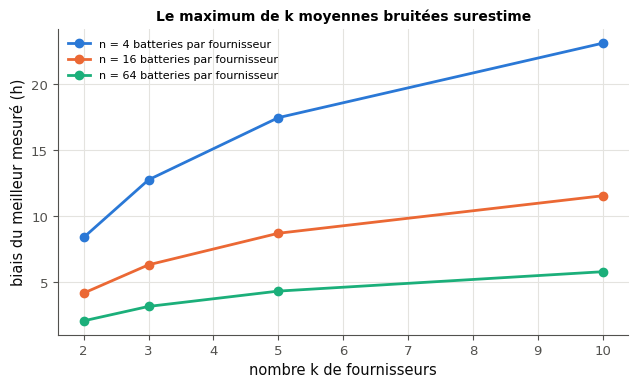

✅ Ex M26.22 : ta simulation et ta figure sont justes.


In [39]:
def max_bias_22(k, n, delta, n_rep, rng):
    """n_rep experiments at once: the true means are MU_22, except that of supplier 0, MU_22 + delta; the n × k lives by
    rng.normal of shape (n_rep, n, k); the naive estimate is the largest of the k measured means; the double estimate
    measures the chosen supplier again on n new batteries (shape (n_rep, n), drawn after the first). Returns the pair
    (naive, double) of the mean biases, measured from the best true mean MU_22 + max(delta, 0)."""
    means = np.full(k, MU_22)
    means[0] += delta
    first = rng.normal(means, SIGMA0_22, size=(n_rep, n, k)).mean(axis=1)       # (n_rep, k) measured means
    chosen = np.argmax(first, axis=1)                                            # the supplier chosen in each experiment
    second = rng.normal(means[chosen][:, None], SIGMA0_22, size=(n_rep, n)).mean(axis=1)   # measured again
    best = MU_22 + max(delta, 0.0)
    return float(first.max(axis=1).mean() - best), float(second.mean() - best)


def draw_bias_22(ax, ks, ns, table):
    """In ax: the naive bias against k, one curve per n (column j of table for ns[j]); axis labels and a legend. No
    other axes."""
    for j, n in enumerate(ns):
        ax.plot(ks, np.asarray(table)[:, j], marker="o", label=f"n = {n} batteries par fournisseur")
    ax.set_xlabel("nombre k de fournisseurs")
    ax.set_ylabel("biais du meilleur mesuré (h)")
    ax.set_title("Le maximum de k moyennes bruitées surestime", fontsize=10)
    ax.legend(fontsize=8)


rng_22 = np.random.default_rng(6222)
naive_22, double_22 = np.zeros((4, 3)), np.zeros((4, 3))
for a, k in enumerate(KS_22):
    for b, n in enumerate(NS_22):
        naive_22[a, b], double_22[a, b] = max_bias_22(k, n, 0.0, N_REP_22, rng_22)
answer_M26_22a = naive_22.tolist()
sigma16_22 = SIGMA0_22 / math.sqrt(16)
answer_M26_22b = bool(abs(naive_22[0, 1] - sigma16_22 / math.sqrt(math.pi)) < 0.2)
answer_M26_22c = float(naive_22[1, 1] / sigma16_22)
answer_M26_22d = bool(np.all(np.abs(double_22) < 0.3))
answer_M26_22e = list(max_bias_22(3, 16, 5.0, N_REP_22, rng_22))
print("a)", np.round(naive_22, 3).tolist())
print("   estimateur double :", np.round(double_22, 3).tolist())
print("b)", answer_M26_22b, f"({naive_22[0, 1]:.3f} contre {sigma16_22 / math.sqrt(math.pi):.3f})", " c)",
      round(answer_M26_22c, 4), " d)", answer_M26_22d, " e)", np.round(answer_M26_22e, 3).tolist())
print("   rapport des biais n = 4 et n = 64 :", np.round(naive_22[:, 0] / naive_22[:, 2], 2).tolist())

def max_bias_c22(k, n, delta, n_rep, rng):
    """The procedure of the statement, by the check (never your code)."""
    means = np.full(k, MU_22)
    means[0] += delta
    first = rng.normal(means, SIGMA0_22, size=(n_rep, n, k)).mean(axis=1)
    chosen = np.argmax(first, axis=1)
    second = rng.normal(means[chosen][:, None], SIGMA0_22, size=(n_rep, n)).mean(axis=1)
    best = MU_22 + max(delta, 0.0)
    return float(first.max(axis=1).mean() - best), float(second.mean() - best)


def table_hint_22(value):
    """a): a table close to the right one, not equal: the order of the draws."""
    want = [[max_bias_c22(k, n, 0.0, 2000, np.random.default_rng(6223))[0] for n in (4, 16)] for k in (2, 3)]
    got = np.asarray(value, dtype=float)
    if got.shape == (4, 3) and np.all(np.abs(got[:2, :2] - np.asarray(want)) < 2.0):
        return ("tes biais ont le bon ordre de grandeur : les valeurs exactes demandent les tirages dans l'ordre de "
                "l'énoncé (k, puis n, puis le dernier appel), avec le même rng, rng.normal de forme (n_rep, n, k) puis "
                "(n_rep, n)")
    return None


with checked("M26.22"):
    results_22 = []
    report_22 = reporter(results_22)
    want_c22 = max_bias_c22(3, 8, 4.0, 3000, np.random.default_rng(6223))
    got_c22 = pair("M26.22", "max_bias_22", max_bias_22(3, 8, 4.0, 3000, np.random.default_rng(6223)),
                   names=("naive", "double"))
    if not matches(got_c22, want_c22, rtol=1e-9, atol=1e-9):
        shifted_c22 = (want_c22[0] + 4.0, want_c22[1] + 4.0)
        report_22(False, "", "max_bias_22(3, 8, 4.0, 3000, default_rng(6223)) : attendu " + shown(want_c22) + ", reçu "
                  + shown(got_c22) + (" : les biais se mesurent par rapport à la meilleure moyenne vraie, 1 000 + max(δ, 0)"
                                      if matches(got_c22, shifted_c22, rtol=1e-9, atol=1e-9) else
                                      " : tire les mesures dans l'ordre de l'énoncé, (n_rep, n, k) puis (n_rep, n)"))
    report_22(True, "max_bias_22 : un cas que tu ne vois pas (k = 3, n = 8, δ = 4, 3 000 expériences), comme attendu", "")
    rng_c22 = np.random.default_rng(6222)                     # one rng for the whole table, as in the statement
    table_c22 = [[max_bias_c22(k, n, 0.0, N_REP_22, rng_c22)[0] for n in NS_22] for k in KS_22]
    fig_22, ax_22 = plt.subplots(figsize=(6.5, 4))
    try:
        opened_22 = drawn(draw_bias_22, ax_22, list(KS_22), list(NS_22), np.array(table_c22))
        report_22(not opened_22, "draw_bias_22 dessine dans l'axe reçu", "draw_bias_22 doit dessiner dans l'axe reçu, "
                  "sans ouvrir de figure")
        missing_22 = [f"n = {n}" for j, n in enumerate(NS_22)
                      if not through(ax_22, KS_22, np.array(table_c22)[:, j], rtol=1e-9)]
        report_22(not missing_22, "une courbe du biais naïf contre k pour chaque n",
                  "il manque la courbe du biais naïf contre k pour " + ", ".join(missing_22))
        report_22(ax_22.get_legend() is not None and ax_22.get_xlabel() != "" and ax_22.get_ylabel() != "",
                  "des noms d'axes et une légende", "draw_bias_22 doit nommer les axes et mettre une légende (un label "
                  "par courbe)")
    except StopCheck:
        fig_22.tight_layout()
        plt.show()
        raise
    except BaseException:
        plt.close(fig_22)
        raise
    fig_22.tight_layout()
    plt.show()
    verdict("M26.22", all(results_22), "ta simulation et ta figure sont justes.", "")

In [40]:
def biases_22r(k, n, delta, rng):
    """The procedure of the statement, written again: (naive, double)."""
    true = np.full(k, 1000.0)
    true[0] += delta
    first = rng.normal(true, 30.0, size=(20000, n, k)).mean(axis=1)
    second = rng.normal(true[first.argmax(axis=1)][:, None], 30.0, size=(20000, n)).mean(axis=1)
    return float(first.max(axis=1).mean() - 1000.0 - max(delta, 0.0)), float(second.mean() - 1000.0 - max(delta, 0.0))


rng_22r = np.random.default_rng(6222)
both_22r = np.array([[biases_22r(k, n, 0.0, rng_22r) for n in (4, 16, 64)] for k in (2, 3, 5, 10)])   # (4, 3, 2)
last_22r = biases_22r(3, 16, 5.0, rng_22r)
wbm.record("M26.22a", both_22r[:, :, 0].tolist(), decimals=4,
           mistakes={"a) demande les biais de l'estimateur naïf, le meilleur mesuré": both_22r[:, :, 1].tolist(),
                     "une ligne par k et une colonne par n": both_22r[:, :, 0].T.tolist()})
wbm.record("M26.22b", bool(abs(both_22r[0, 1, 0] - 7.5 / math.sqrt(math.pi)) < 0.2),
           mistakes={"σ est l'écart-type d'une moyenne de 16 batteries, 30/√16 : compare le biais à σ/√π": False})
wbm.record("M26.22c", float(both_22r[1, 1, 0] / 7.5), decimals=3,
           mistakes={"σ est l'écart-type d'une moyenne de 16 batteries, 30/√16, pas celui d'une batterie":
                         float(both_22r[1, 1, 0] / 30.0)})
wbm.record("M26.22d", bool(np.all(np.abs(both_22r[:, :, 1]) < 0.3)),
           mistakes={"quand tout se vaut, la remesure du fournisseur choisi est sans biais : compare |biais double| à 0,3 "
                     "h dans tout le tableau": False})
wbm.record("M26.22e", list(last_22r), decimals=4,
           mistakes={"le biais se mesure par rapport à la meilleure moyenne vraie, 1 000 + δ ici":
                         [last_22r[0] + 5.0, last_22r[1] + 5.0],
                     "le naïf d'abord, puis le double": list(last_22r[::-1])})

WBM_ANSWER {"decimals": 4, "element_coarse": [["60d4ae437c2bf32446e3a29769f00efcdc0bcd369fe24ee2c0ec376a76e7607a"], ["dadbf8f4461bddad3c2b44ef8bb557e6f5fe5d71a96f7bef36aedb556a89c58b"], ["5dc620ae612eed5220dc6b082839e2bbc59aef644ef6c5af4c67d53fadf7c10f"], ["8024c622a16b973a5eb7a3820faca17e2df98e8dbef37db8c810547ad6ce74a9"], ["1fcbf067c9c619bcb11ca240e589b6cab3b73ea4c89a3066f79c313d8685fd2c"], ["0697fe26e5def882ff670b4a0754ffd9ec5e046d867b5dc46250c9af0c7b6b65"], ["eaba5ba63245e17f9a4c082cfa96e015a11f7344b66b2a08c4f14bdf27fe52e3"], ["3e07e73e2f5c0df2590ee034c0cdbd37d106d3335ef0d2a3d7db9353020534f1"], ["65992dae139374e938771a29c3d37dd35d5296cc876dfc08dffa0a9b51f2b3bf"], ["7662b750efdf2947b6bbab72e5d341f834e0a32e95535cf634bd81443c294208"], ["b8d52d4a78093228f1ee03dfd9b595e148f846dd1ea4cc38dacba0b65a3ab89a"], ["67ed81b53df410b5f785e0463956729dab2ca54ada686447a361cc2fbc936c21"]], "element_coarse_any": [["2a2aa682b808011393b41f687b08dcd9f902448c3ff72718dacf02606151e541", "1484d9076399a1648ac5

**Après la figure**, dans ta copie : pourquoi le biais grandit-il avec $k$ ? Pourquoi est-il divisé par deux quand $n$ est multiplié par quatre ? Pourquoi l'estimateur double devient-il pessimiste quand un fournisseur est meilleur ?

💡 a) Biais naïfs (h), $n = 4$, 16, 64 : $k = 2$ : 8,40 ; 4,18 ; 2,07 ; $k = 3$ : 12,77 ; 6,32 ; 3,17 ; $k = 5$ : 17,47 ; 8,71 ; 4,33 ; $k = 10$ : 23,12 ; 11,55 ; 5,80. b) Vrai (4,18 contre 4,23). c) $\approx 0{,}843$, contre 0,846. d) Vrai (le plus grand écart vaut 0,18 h). e) Naïf $\approx 3{,}47$ h, double $\approx -2{,}38$ h : le naïf reste optimiste, le double devient pessimiste (il choisit parfois un fournisseur moins bon).

### Ex M26.23 — La loi d'une chaîne au fil des pas depuis trois départs, et ‖μ_n − π‖₁ en échelle logarithmique contre |λ₂|ⁿ 🎨 ★ ⏱️ 15 min
**Objectif :** voir la loi d'une chaîne oublier son départ, et lire sur une échelle logarithmique que l'écart décroît comme |λ₂|ⁿ.  
**Prérequis :** fiche §1 et §2 ; M12c ; Ex M26.2, M26.16 et M26.17 · **Parcours :** C

Écris `draw_convergence_23(ax_law, ax_dist, P, starts, n_max)`, qui dessine sur les **axes reçus** (sans ouvrir de figure), avec ta `n_step_distribution` et ta `stationary_distribution` :
- dans `ax_law`, la probabilité d'être dans l'état 0 en fonction de $n$, de 0 à `n_max`, une courbe par état de départ de `starts`, et la droite horizontale $\pi_0$ ;
- dans `ax_dist`, en échelle logarithmique, $\lVert\boldsymbol{\mu}_n - \boldsymbol{\pi}\rVert_1$ pour chaque départ ($n = 0, \ldots,$ `n_max`), et en pointillés la courbe $\lvert\lambda_2\rvert^n$ ($\lambda_2$ calculée par `np.linalg.eigvals` : la deuxième plus grande valeur propre en module) ;
- des titres, des noms d'axes et une légende dans chaque panneau.

La vérification l'appelle sur les trois opérateurs de M26.2 (`P_OPERATORS`), avec `starts = [0, 1, 2]` et `n_max = 100` (`STARTS_23`, `N_MAX_23`), et affiche la figure ; elle l'appelle aussi sur une chaîne que tu ne vois pas, et regarde chaque dessin. Tes propres calculs servent à relever :
- a) $\lvert\lambda_2\rvert$ (un nombre ; 4 décimales dans ta copie) ;
- b) la pente de $n \mapsto \ln\lVert\boldsymbol{\mu}_n - \boldsymbol{\pi}\rVert_1$ entre $n = 50$ et $n = 100$, depuis l'état 0 (un nombre ; 4 décimales dans ta copie), à comparer à $\ln\lvert\lambda_2\rvert$ ;
- c) le premier $n$ où les trois écarts sont tous inférieurs à $10^{-6}$ (un entier).

Ce qu'il faut observer : après quelques pas, les trois courbes deviennent des droites parallèles de pente $\ln\lvert\lambda_2\rvert$ ; le départ ne change que leur hauteur.

In [41]:
STARTS_23 = [0, 1, 2]                                      # the three starting states (the three operators)
N_MAX_23 = 100

a) 0.822474  b) -0.195438 (ln |λ₂| = -0.195438)  c) 73
✅ draw_convergence_23 dessine dans les axes reçus
✅ les trois opérateurs : les trois départs, π₀, les écarts en échelle logarithmique et |λ₂|ⁿ sont là
✅ une chaîne que tu ne vois pas (4 états, deux départs, 40 pas) est dessinée juste aussi


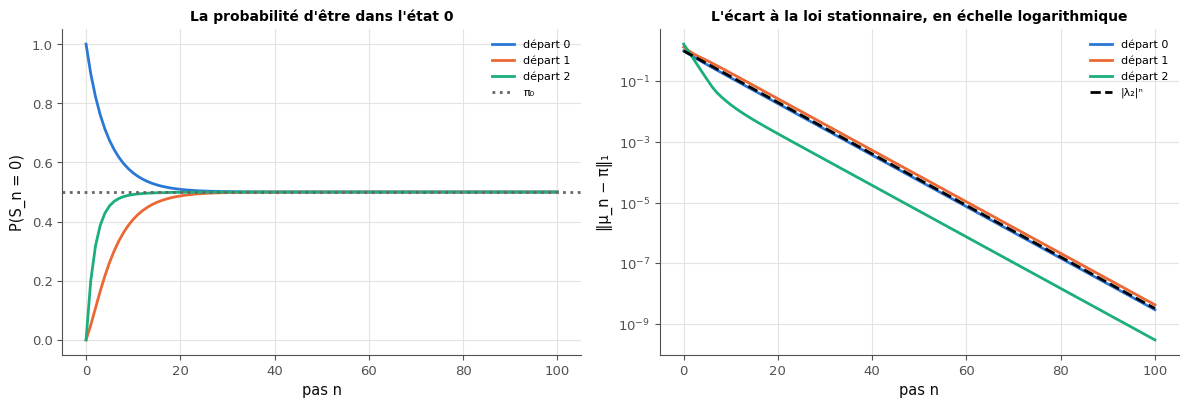

✅ Ex M26.23 : la loi au fil des pas et l'oubli du départ sont dessinés.


In [42]:
n_step_distribution = mymath.markov.n_step_distribution
stationary_distribution = mymath.markov.stationary_distribution


def draw_convergence_23(ax_law, ax_dist, P, starts, n_max):
    """With your n_step_distribution and stationary_distribution. In ax_law: P(S_n = 0) against n = 0, ..., n_max, one
    curve per starting state of starts, and the horizontal line π_0; in ax_dist, in log scale: ‖μ_n − π‖₁ for each start,
    and |λ2|ⁿ dashed (np.linalg.eigvals); titles, axis labels and a legend in each panel. No other axes."""
    P = np.asarray(P, dtype=float)
    pi, steps = stationary_distribution(P), np.arange(n_max + 1)
    for s in starts:
        laws = np.array([n_step_distribution(P, np.eye(len(P))[s], n) for n in steps])
        ax_law.plot(steps, laws[:, 0], label=f"départ {s}")
        ax_dist.plot(steps, np.abs(laws - pi).sum(axis=1), label=f"départ {s}")
    ax_law.axhline(pi[0], color="0.4", linestyle=":", label="π₀")
    lam2 = np.sort(np.abs(np.linalg.eigvals(P)))[::-1][1]
    ax_dist.plot(steps, lam2 ** steps, color="k", linestyle="--", label="|λ₂|ⁿ")
    ax_dist.set_yscale("log")
    ax_law.set_title("La probabilité d'être dans l'état 0", fontsize=10)
    ax_dist.set_title("L'écart à la loi stationnaire, en échelle logarithmique", fontsize=10)
    for ax, ylabel in ((ax_law, "P(S_n = 0)"), (ax_dist, "‖μ_n − π‖₁")):
        ax.set_xlabel("pas n")
        ax.set_ylabel(ylabel)
        ax.legend(fontsize=8)


pi_23 = stationary_distribution(P_OPERATORS)
gaps_23 = np.array([[np.abs(n_step_distribution(P_OPERATORS, np.eye(3)[s], n) - pi_23).sum() for n in range(N_MAX_23 + 1)]
                    for s in STARTS_23])
answer_M26_23a = float(np.sort(np.abs(np.linalg.eigvals(P_OPERATORS)))[::-1][1])
answer_M26_23b = float((np.log(gaps_23[0, 100]) - np.log(gaps_23[0, 50])) / 50)
answer_M26_23c = int(np.argmax(np.all(gaps_23 < 1e-6, axis=0)))
print("a)", round(answer_M26_23a, 6), " b)", round(answer_M26_23b, 6), f"(ln |λ₂| = {math.log(answer_M26_23a):.6f})",
      " c)", answer_M26_23c)

def look_23(ax_law, ax_dist, P, starts, n_max):
    """What is wrong in a drawing of draw_convergence_23 (expected values by the reference): French phrases."""
    P = np.asarray(P, dtype=float)
    pi = ref_markov.stationary_distribution(P)
    steps = np.arange(n_max + 1)
    lam2 = np.sort(np.abs(np.linalg.eigvals(P)))[::-1][1]
    missing = []
    for s in starts:
        laws = np.array([ref_markov.n_step_distribution(P, np.eye(len(P))[s], n) for n in steps])
        columns = np.array([np.linalg.matrix_power(P, n)[:, s] for n in steps])   # (wrong) P^n e_s, the column convention
        if not through(ax_law, steps, laws[:, 0]):
            missing.append(f"la probabilité d'être dans l'état 0 depuis l'état {s}, contre n = 0, …, {n_max}"
                           + (" (tu traces la convention colonne, Pⁿ e_s : une loi avance par mu @ P)"
                              if through(ax_law, steps, columns[:, 0]) else ""))
        dist = np.abs(laws - pi).sum(axis=1)
        if not through(ax_dist, steps, dist):
            wrong = np.abs(columns - pi).sum(axis=1)
            missing.append(f"‖μ_n − π‖₁ depuis l'état {s}" + (" (tes courbes ne tendent pas vers 0 : c'est la convention "
                           "colonne, Pⁿ e_s ; une loi avance par mu @ P)" if through(ax_dist, steps, wrong) else ""))
    if not horizontal_at(ax_law, pi[0]):
        missing.append("la droite horizontale π₀ dans le panneau de gauche")
    if not through(ax_dist, steps, lam2 ** steps, dashed=True):
        missing.append("la courbe |λ₂|ⁿ en pointillés dans le panneau de droite")
    if ax_dist.get_yscale() != "log":
        missing.append("l'échelle logarithmique du panneau de droite (ax.set_yscale(\"log\"))")
    for name, ax in (("de gauche", ax_law), ("de droite", ax_dist)):
        if not ax.get_title() or not ax.get_xlabel() or not ax.get_ylabel() or ax.get_legend() is None:
            missing.append(f"un titre, des noms d'axes et une légende dans le panneau {name}")
    return missing


with checked("M26.23"):
    results_23 = []
    report_23 = reporter(results_23)
    hidden_c23 = np.array([[0.5, 0.3, 0.2, 0.0], [0.1, 0.6, 0.1, 0.2], [0.25, 0.0, 0.55, 0.2], [0.3, 0.1, 0.0, 0.6]])
    fig_c23, (law_c23, dist_c23) = plt.subplots(1, 2)
    try:
        with own_code("M26.23", "draw_convergence_23", REF_MARKOV):
            opened_c23 = drawn(draw_convergence_23, law_c23, dist_c23, hidden_c23.copy(), [3, 0], 40)
        missing_c23 = look_23(law_c23, dist_c23, hidden_c23, [3, 0], 40)
    finally:
        plt.close(fig_c23)
    fig_23, (law_23, dist_23) = plt.subplots(1, 2, figsize=(12, 4.2))
    try:
        with own_code("M26.23", "draw_convergence_23", REF_MARKOV):
            opened_23 = drawn(draw_convergence_23, law_23, dist_23, P_OPERATORS.copy(), list(STARTS_23), N_MAX_23)
        report_23(not opened_23 and not opened_c23, "draw_convergence_23 dessine dans les axes reçus",
                  "draw_convergence_23 doit dessiner dans les deux axes reçus, sans ouvrir de figure")
        missing_23 = look_23(law_23, dist_23, P_OPERATORS, STARTS_23, N_MAX_23)
        report_23(not missing_23, "les trois opérateurs : les trois départs, π₀, les écarts en échelle logarithmique et "
                  "|λ₂|ⁿ sont là", "les trois opérateurs : il manque " + " ; ".join(missing_23))
        report_23(not missing_c23, "une chaîne que tu ne vois pas (4 états, deux départs, 40 pas) est dessinée juste aussi",
                  "une chaîne que tu ne vois pas (4 états, départs [3, 0], 40 pas) : il manque " + " ; ".join(missing_c23))
    except StopCheck:
        fig_23.tight_layout()
        plt.show()
        raise
    except BaseException:
        plt.close(fig_23)
        raise
    fig_23.tight_layout()
    plt.show()
    verdict("M26.23", all(results_23), "la loi au fil des pas et l'oubli du départ sont dessinés.", "")

In [43]:
P_23r = np.array([[0.9, 0.05, 0.05], [0.05, 0.85, 0.1], [0.2, 0.15, 0.65]])
lam_23r = np.sort(np.abs(np.linalg.eigvals(P_23r)))[::-1]
v_23r = linalg.null_space(P_23r.T - np.eye(3))[:, 0]
pi_23r = v_23r / v_23r.sum()
gaps_23r = np.array([[np.abs(np.linalg.matrix_power(P_23r, n)[s] - pi_23r).sum() for n in range(101)] for s in range(3)])
wbm.record("M26.23a", float(lam_23r[1]), decimals=5,
           mistakes={"λ₂ est la deuxième plus grande valeur propre en module ; la première vaut 1": float(lam_23r[0])})
slope_23r = float((np.log(gaps_23r[0, 100]) - np.log(gaps_23r[0, 50])) / 50)
wbm.record("M26.23b", slope_23r, decimals=6,
           mistakes={"la pente se lit sur le logarithme népérien, ln": slope_23r / math.log(10),
                     "une pente divise la différence des logarithmes par celle des n (50)": slope_23r * 50})
first_23r = int(np.argmax(np.all(gaps_23r < 1e-6, axis=0)))
wbm.record("M26.23c", first_23r,
           mistakes={"le premier n où les trois écarts sont tous sous 1e-6, n compté depuis 0 : un de moins ici":
                         first_23r - 1,
                     "le premier n où les trois écarts sont tous sous 1e-6 : un de trop ici": first_23r + 1})

WBM_ANSWER {"coarse_any": {"0": ["419df7528bd0ed052f2a5070f420bb1ff80280b04a891567ddaadd2b6720ab0b"], "1": ["d0b8056b0d5c18e6527f6c2480833af20abc422d2b6e293bd10d0098e5cb7d25"]}, "coarser": {"2": ["12e160e43474ed01c8f2c39201c41f3275e509222d281587e361a11f2b3bf6d9"], "3": ["53f56ef7cf11e391fde7bb6c32b8818cfc7daada33fde78106ee447f2851e7f7"]}, "decimals": 5, "hash": "a43f1366034db5be2d549a2acc3307bff95e278f158c56d72137e4b899378d6e", "hash_coarse": "e4b0fe2f7689bf1304db60a184f6c16dc76c1e65629a196343a69500516418d7", "id": "M26.23a", "kind": "float", "magnitude": -1, "mistakes": {"8845965a6355e4e71e570ba533c4a72e9226a0438207190a74ed97ce3869689f": "λ₂ est la deuxième plus grande valeur propre en module ; la première vaut 1"}, "sign": 1}
📝 Ex M26.23a : réponse enregistrée (float, 5 décimales).
WBM_ANSWER {"coarse_any": {"1": ["af18a8339701535ea0efbbde648bd9a079c62724afc5324c55a7e82ef5415b41"]}, "coarser": {"2": ["68f5b5d0f6e6ebd5d2384be1afe5efeea51343144b119aa2b297bae7b68ddcce"], "3": ["7ce41f61

**Après la figure**, dans ta copie : pourquoi les trois courbes de droite deviennent-elles parallèles ? Que changerait une deuxième valeur propre de module plus petit ? Combien de mois faut-il pour que la loi des parts de marché ne dépende presque plus d'aujourd'hui ?

💡 a) $\lvert\lambda_2\rvert = 0{,}7 + \sqrt{0{,}015} \approx 0{,}8225$. b) $\approx -0{,}1954$, égale à $\ln 0{,}8225$ à $10^{-8}$ près. c) $n = 73$.

## Partie C · Déboguer, tester

Fiche §1, §2, §5 et §6. Quatre erreurs classiques, qui passent une vérification mal choisie ; un test de propriété des lois stationnaires et des itérés de Bellman. Les données et les vérifications s'appuient sur la référence (`ref_markov`), pour ne pas dépendre de ton code.

### Ex M26.24 — Chasse à l'erreur : une matrice lue dans la mauvaise convention, une loi stationnaire non normalisée, un état final qui rapporte encore, γ = 1 sans fin 🐛 ★ ⏱️ 25 min
**Objectif :** reconnaître quatre erreurs classiques sur les chaînes de Markov et le système de Bellman, qui passent une vérification mal choisie, puis les corriger.  
**Prérequis :** fiche §1, §2 et §5 ; Ex M26.1, M26.2, M26.4 et M26.16 à M26.18 · **Parcours :** C, E

Un collègue a écrit quatre fonctions, chacune accompagnée d'une vérification qui passe (cellule fournie) :
1. `bikes_after(P, mu0, n)` doit rendre la loi d'un vélo après `n` jours ; elle répète `n` fois `mu = P @ mu`. Il l'a vérifiée sur la matrice $\mathbf{S}$ (`S_24`), depuis la station 0, sur 5 jours : le résultat a pour somme 1 et égale la ligne 0 de `np.linalg.matrix_power(S, 5)`. Il l'applique aux vélos de M26.1.
2. `market_shares(P)` doit rendre la loi stationnaire ; elle calcule `w, v = np.linalg.eig(P.T)`, prend la colonne de `v` dont la valeur propre est la plus proche de 1, et rend sa partie réelle. Il l'a vérifiée sur les trois opérateurs de M26.2 : `np.allclose(pi @ P, pi)` vaut `True`.
3. `subscription_value(P, monthly_fee, closing_fee, gamma)` doit rendre les valeurs d'un abonnement à trois états, essai (0), payant (1) et résilié (2, absorbant), où un abonné payant verse `monthly_fee` chaque mois et où une résiliation coûte une fois `closing_fee` à l'abonné ; elle construit $\mathbf{r} = (0,\ \text{monthly\_fee},\ \text{closing\_fee})$ et rend `np.linalg.solve(np.eye(3) - gamma * P, r)`. Il l'a vérifiée avec `P_SUBSCRIPTION_24`, 12 € par mois, 15 € de frais et $\gamma = 0{,}96$ : le résidu $\lVert\mathbf{V} - (\mathbf{r} + \gamma\mathbf{P}\mathbf{V})\rVert_\infty$ est inférieur à $10^{-9}$.
4. `total_takings(P, r)` doit rendre la recette totale moyenne jusqu'à la fin, depuis chaque état ; elle rend `np.linalg.solve(np.eye(m) - P, r)`. Il l'a vérifiée sur le cursus de M26.4 (`P` = les trois années, `r` = des 1) : elle redonne les durées moyennes. Il l'applique ensuite aux vélos, avec une matrice estimée sur 100 trajets par station (`P_ESTIMATED_24`, de lignes $(61, 29, 10)/100$, $(33, 41, 26)/100$ et $(38, 23, 39)/100$), et les recettes journalières $(1{,}5 ;\ 1 ;\ 0{,}5)$ € (`TAKINGS_24`).

À faire : trouve et corrige chaque erreur ; les fonctions corrigées s'appellent `bikes_after_fixed`, `market_shares_fixed`, `subscription_value_fixed` et `total_takings_fixed`, avec les mêmes arguments (`total_takings_fixed` lève une `ValueError` quand le processus ne finit pas avec certitude, testé par `np.linalg.matrix_rank`). Puis réponds :
- a) la loi des vélos de M26.1 après trois jours par `bikes_after_fixed`, et la somme des coordonnées de ce que rend `bikes_after` (une liste de 4 nombres ; 4 décimales dans ta copie) ;
- b) la loi rendue par `market_shares_fixed` pour les trois opérateurs, et la valeur absolue de la somme de ce que rend `market_shares` (une liste de 4 nombres ; 4 décimales dans ta copie) ;
- c) les valeurs que rend `subscription_value_fixed` pour le modèle du collègue, et celle que `subscription_value` donne à l'état résilié (une liste de 4 nombres ; 2 décimales dans ta copie) ;
- d) vrai ou faux : `total_takings_fixed` lève une `ValueError` sur la matrice des vélos (`P_ESTIMATED_24`).

Dans ta copie : ce que rend `total_takings` sur cette matrice (une erreur, ou des nombres : lesquels ?), et, pour chacune des quatre erreurs, pourquoi la vérification du collègue ne la voyait pas. La vérification essaie tes corrections sur des cas que tu ne vois pas : des chaînes non symétriques, d'autres lois stationnaires, d'autres abonnements, une fin sûre et deux fins qui ne le sont pas.

In [44]:
S_24 = np.array([[0.7, 0.2, 0.1], [0.2, 0.6, 0.2], [0.1, 0.2, 0.7]])      # the colleague's test matrix
P_SUBSCRIPTION_24 = np.array([[0, 0.55, 0.45], [0, 0.9, 0.1], [0, 0, 1.0]])   # trial (0), paying (1), cancelled (2)
COUNTS_BIKES_24 = np.array([[61, 29, 10], [33, 41, 26], [38, 23, 39]])        # 100 trips from each station
P_ESTIMATED_24 = COUNTS_BIKES_24 / 100
TAKINGS_24 = np.array([1.5, 1.0, 0.5])                    # the daily takings of a bike in A, B, C (€)


# The colleague's code
def bikes_after(P, mu0, n):
    """The law of a bike after n days."""
    mu = np.array(mu0, dtype=float)
    for _ in range(n):
        mu = P @ mu
    return mu


def market_shares(P):
    """The stationary law."""
    w, v = np.linalg.eig(np.asarray(P, dtype=float).T)
    return np.real(v[:, np.argmin(np.abs(w - 1))])


def subscription_value(P, monthly_fee, closing_fee, gamma):
    """The values of a subscription: trial (0), paying (1) who pays monthly_fee each month, cancelled (2, absorbing);
    a cancellation costs closing_fee once to the subscriber."""
    r = np.array([0.0, monthly_fee, closing_fee])
    return np.linalg.solve(np.eye(3) - gamma * np.asarray(P, dtype=float), r)


def total_takings(P, r):
    """The mean total takings until the end, from each state."""
    m = len(r)
    return np.linalg.solve(np.eye(m) - np.asarray(P, dtype=float), np.asarray(r, dtype=float))


# The colleague's checks: all pass
print("(1) S symétrique, 5 jours : somme 1 :", bool(np.isclose(bikes_after(S_24, [1, 0, 0], 5).sum(), 1)),
      "; ligne 0 de S⁵ :", bool(np.allclose(bikes_after(S_24, [1, 0, 0], 5), np.linalg.matrix_power(S_24, 5)[0])),
      "(attendu True, True)")
pi_check_24 = market_shares(P_OPERATORS)
print("(2) les opérateurs : πP = π :", bool(np.allclose(pi_check_24 @ P_OPERATORS, pi_check_24)), "(attendu True)")
V_check_24 = subscription_value(P_SUBSCRIPTION_24, 12.0, 15.0, 0.96)
r_check_24 = np.array([0.0, 12.0, 15.0])
print("(3) résidu ‖V − (r + γPV)‖∞ < 1e-9 :",
      bool(np.abs(V_check_24 - (r_check_24 + 0.96 * P_SUBSCRIPTION_24 @ V_check_24)).max() < 1e-9), "(attendu True)")
print("(4) le cursus : les durées moyennes :",
      bool(np.allclose(total_takings(Q_CURSUS, np.ones(3)), np.linalg.solve(np.eye(3) - Q_CURSUS, np.ones(3)))),
      "(attendu True)")

(1) S symétrique, 5 jours : somme 1 : True ; ligne 0 de S⁵ : True (attendu True, True)
(2) les opérateurs : πP = π : True (attendu True)
(3) résidu ‖V − (r + γPV)‖∞ < 1e-9 : True (attendu True)
(4) le cursus : les durées moyennes : True (attendu True)


In [45]:
def bikes_after_fixed(P, mu0, n):
    """The law of a bike after n days."""
    mu = np.array(mu0, dtype=float)
    for _ in range(n):
        mu = mu @ np.asarray(P, dtype=float)                 # a law is a row: it moves by mu @ P
    return mu


def market_shares_fixed(P):
    """The stationary law."""
    w, v = np.linalg.eig(np.asarray(P, dtype=float).T)
    pi = np.real(v[:, np.argmin(np.abs(w - 1))])
    return pi / pi.sum()                                     # a law: sum 1 (and the sign of the eigenvector is gone)


def subscription_value_fixed(P, monthly_fee, closing_fee, gamma):
    """The values of a subscription: trial (0), paying (1) who pays monthly_fee each month, cancelled (2, absorbing);
    a cancellation costs closing_fee once to the subscriber."""
    P = np.asarray(P, dtype=float)
    r = np.array([0.0, monthly_fee, 0.0]) + closing_fee * P[:, 2]   # the fee on the transition to « cancelled »...
    r[2] = 0.0                                                     # ... and nothing in the absorbing state
    return np.linalg.solve(np.eye(3) - gamma * P, r)


def total_takings_fixed(P, r):
    """The mean total takings until the end, from each state; ValueError when the process does not end for sure."""
    P, m = np.asarray(P, dtype=float), len(r)
    if np.linalg.matrix_rank(np.eye(m) - P) < m:
        raise ValueError("the process does not end for sure: I - P is singular")
    return np.linalg.solve(np.eye(m) - P, np.asarray(r, dtype=float))


answer_M26_24a = bikes_after_fixed(P_BIKES, MU0_BIKES, 3).tolist() + [float(bikes_after(P_BIKES, MU0_BIKES, 3).sum())]
answer_M26_24b = market_shares_fixed(P_OPERATORS).tolist() + [abs(float(market_shares(P_OPERATORS).sum()))]
answer_M26_24c = (subscription_value_fixed(P_SUBSCRIPTION_24, 12.0, 15.0, 0.96).tolist()
                  + [float(subscription_value(P_SUBSCRIPTION_24, 12.0, 15.0, 0.96)[2])])
try:
    total_takings_fixed(P_ESTIMATED_24, TAKINGS_24)
    answer_M26_24d = False
except ValueError as exc:
    answer_M26_24d = True
    print("total_takings_fixed refuse les vélos :", exc)
try:
    print("la version fausse rend", total_takings(P_ESTIMATED_24, TAKINGS_24),
          f"(le rang de I − P vaut {np.linalg.matrix_rank(np.eye(3) - P_ESTIMATED_24)})")
except np.linalg.LinAlgError as exc:
    print("la version fausse lève LinAlgError :", exc)
print("a)", np.round(answer_M26_24a, 6).tolist(), " b)", np.round(answer_M26_24b, 6).tolist())
print("c)", np.round(answer_M26_24c, 4).tolist(), " d)", answer_M26_24d, "; signe de la somme rendue par market_shares :",
      np.sign(market_shares(P_OPERATORS).sum()))

results_24, parts_24 = [], []


def report_24(ok, success, failure):
    results_24.append(bool(ok))
    print(("✅ " + success) if ok else ("❌ " + failure))


def call_24(part, name, function, *args):
    """function(*args); an error of the learner's code becomes one ❌ line that names the function (the check of this
    part stops there, the final verdict stays)."""
    try:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore", RuntimeWarning)
            return function(*args)
    except (NotImplementedError, MymathMissingError):
        raise
    except Exception as exc:  # noqa: BLE001 - the learner's error, reported with the name of the function
        report_24(False, "", f"({part}) {name} : ton code lève {type(exc).__name__} : {str(exc)[:200]}")
        parts_24.append(part)
        raise StopCheck from None


rng_c24 = np.random.default_rng(6204)


def chain_c24(m, sparse=0.0):
    """A random stochastic chain of m states (positive entries, a few zeros when sparse > 0)."""
    W = rng_c24.random((m, m)) * (rng_c24.random((m, m)) >= sparse) + 0.02 * np.eye(m)
    return W / W.sum(axis=1, keepdims=True)


with checked("M26.24"):                                       # (1) bikes_after_fixed
    wrong_24 = []
    for m_c24, n_c24 in ((4, 0), (4, 7), (5, 3)):
        P_c24, mu_c24 = chain_c24(m_c24, 0.3), rng_c24.dirichlet(np.ones(m_c24))
        want_c24 = mu_c24 @ np.linalg.matrix_power(P_c24, n_c24)
        got_c24 = call_24(1, "bikes_after_fixed", bikes_after_fixed, P_c24.copy(), mu_c24.copy(), n_c24)
        if matches(got_c24, want_c24):
            continue
        if matches(got_c24, np.linalg.matrix_power(P_c24, n_c24) @ mu_c24):
            wrong_24.append("tu fais encore avancer la loi par P @ mu : une loi est une ligne, mu @ P")
        else:
            wrong_24.append(f"{m_c24} états, {n_c24} jours : attendu {shown(want_c24)}, reçu {shown(got_c24)[:120]}")
    report_24(not wrong_24, "(1) bikes_after_fixed : des chaînes que tu ne vois pas, non symétriques, 0, 3 et 7 jours",
              "(1) bikes_after_fixed : " + " ; ".join(list(dict.fromkeys(wrong_24))[:2]))
    parts_24.append(1)

with checked("M26.24"):                                       # (2) market_shares_fixed
    wrong_24 = []
    for m_c24 in (4, 5, 6):
        P_c24 = chain_c24(m_c24)
        v_c24 = linalg.null_space(P_c24.T - np.eye(m_c24))[:, 0]
        want_c24 = v_c24 / v_c24.sum()
        got_c24 = call_24(2, "market_shares_fixed", market_shares_fixed, P_c24.copy())
        if matches(got_c24, want_c24):
            continue
        try:
            arr_c24 = np.asarray(got_c24, dtype=float)
            proportional_c24 = arr_c24.shape == want_c24.shape and matches(arr_c24 / arr_c24.sum(), want_c24)
        except (TypeError, ValueError, ZeroDivisionError):
            proportional_c24 = False
        if proportional_c24:
            wrong_24.append("ta loi est proportionnelle à la bonne : divise le vecteur propre par sa somme (son signe est "
                            "arbitraire, la division le corrige)")
        else:
            wrong_24.append(f"{m_c24} états : attendu {shown(want_c24)}, reçu {shown(got_c24)[:120]}")
    report_24(not wrong_24, "(2) market_shares_fixed : des chaînes que tu ne vois pas, de 4 à 6 états",
              "(2) market_shares_fixed : " + " ; ".join(list(dict.fromkeys(wrong_24))[:2]))
    parts_24.append(2)

with checked("M26.24"):                                       # (3) subscription_value_fixed
    wrong_24 = []
    for p_paid_c24, p_stay_c24, monthly_c24, closing_c24, gamma_c24 in ((0.7, 0.85, 20.0, 30.0, 0.85),
                                                                         (0.4, 0.95, 8.0, 5.0, 0.96)):
        P_c24 = np.array([[0, p_paid_c24, 1 - p_paid_c24], [0, p_stay_c24, 1 - p_stay_c24], [0, 0, 1.0]])
        r_c24 = np.array([closing_c24 * P_c24[0, 2], monthly_c24 + closing_c24 * P_c24[1, 2], 0.0])
        want_c24 = np.linalg.solve(np.eye(3) - gamma_c24 * P_c24, r_c24)
        got_c24 = call_24(3, "subscription_value_fixed", subscription_value_fixed, P_c24.copy(), monthly_c24, closing_c24,
                          gamma_c24)
        if matches(got_c24, want_c24):
            continue
        got_arr_c24 = np.asarray(got_c24, dtype=float) if matches(got_c24, np.zeros(3), rtol=np.inf, atol=np.inf) else None
        if got_arr_c24 is not None and abs(got_arr_c24[2]) > 1e-9:
            wrong_24.append("l'état résilié rapporte encore : un état absorbant reçoit une récompense nulle, sinon il la "
                            "rapporte à chaque mois, pour toujours")
        elif matches(got_c24, np.linalg.solve(np.eye(3) - gamma_c24 * P_c24, [0.0, monthly_c24, 0.0])):
            wrong_24.append("les frais de résiliation ont disparu : ils se paient une fois, sur la transition vers « résilié »")
        else:
            wrong_24.append(f"un autre abonnement (γ = {fr(gamma_c24, 2)}) : attendu {shown(want_c24)}, reçu {shown(got_c24)}")
    report_24(not wrong_24, "(3) subscription_value_fixed : deux abonnements que tu ne vois pas",
              "(3) subscription_value_fixed : " + " ; ".join(list(dict.fromkeys(wrong_24))[:2]))
    parts_24.append(3)

with checked("M26.24"):                                       # (4) total_takings_fixed
    wrong_24 = []
    ends_c24 = chain_c24(4, 0.2) * np.array([[0.9], [0.8], [0.95], [0.7]])     # every row ends: a sure end
    r_c24 = rng_c24.uniform(0.5, 2.0, 4)
    got_c24 = call_24(4, "total_takings_fixed", total_takings_fixed, ends_c24.copy(), r_c24.copy())
    if not matches(got_c24, np.linalg.solve(np.eye(4) - ends_c24, r_c24)):
        wrong_24.append(f"une chaîne qui finit avec certitude : attendu {shown(np.linalg.solve(np.eye(4) - ends_c24, r_c24))}, "
                        f"reçu {shown(got_c24)}")
    kept_c24 = np.zeros((4, 4))                               # an absorbing end kept as a state: I − P singular
    kept_c24[:3, :3], kept_c24[:3, 3], kept_c24[3, 3] = ends_c24[:3, :3], 1 - ends_c24[:3, :3].sum(axis=1), 1.0
    for label_c24, P_c24 in (("une chaîne stochastique, sans fin", chain_c24(5)),
                             ("une fin gardée comme état absorbant", kept_c24)):
        try:
            with warnings.catch_warnings():
                warnings.simplefilter("ignore", RuntimeWarning)
                total_takings_fixed(P_c24.copy(), np.ones(len(P_c24)))
            wrong_24.append(f"{label_c24} : attendu une ValueError (la fin n'est pas sûre, I − P est singulière ; teste "
                            "np.linalg.matrix_rank), mais rien n'a été levé")
        except (NotImplementedError, MymathMissingError):
            raise
        except np.linalg.LinAlgError:
            wrong_24.append(f"{label_c24} : np.linalg.solve a échoué tout seul ; teste d'abord np.linalg.matrix_rank(I − P) "
                            "et lève toi-même une ValueError")
        except ValueError:
            pass
    report_24(not wrong_24, "(4) total_takings_fixed : une fin sûre résolue, deux fins pas sûres refusées",
              "(4) total_takings_fixed : " + " ; ".join(wrong_24[:2]))
    parts_24.append(4)

if len(set(parts_24)) == 4:
    verdict("M26.24", all(results_24), "les quatre fonctions corrigées passent tous les cas.",
            "relis les lignes ❌ ci-dessus.")

total_takings_fixed refuse les vélos : the process does not end for sure: I - P is singular
la version fausse rend [6.46364549e+16 6.46364549e+16 6.46364549e+16] (le rang de I − P vaut 2)
a) [0.4604, 0.3072, 0.2324, 1.0604]  b) [0.5, 0.333333, 0.166667, 1.603567]
c) [59.1618, 99.2647, 0.0, 375.0]  d) True ; signe de la somme rendue par market_shares : -1.0
✅ (1) bikes_after_fixed : des chaînes que tu ne vois pas, non symétriques, 0, 3 et 7 jours
✅ (2) market_shares_fixed : des chaînes que tu ne vois pas, de 4 à 6 états
✅ (3) subscription_value_fixed : deux abonnements que tu ne vois pas
✅ (4) total_takings_fixed : une fin sûre résolue, deux fins pas sûres refusées
✅ Ex M26.24 : les quatre fonctions corrigées passent tous les cas.


In [46]:
P_bikes_24r, mu0_24r = np.array([[0.6, 0.3, 0.1], [0.3, 0.4, 0.3], [0.4, 0.2, 0.4]]), np.array([0.4, 0.4, 0.2])
law_24r = mu0_24r @ np.linalg.matrix_power(P_bikes_24r, 3)
column_24r = np.linalg.matrix_power(P_bikes_24r, 3) @ mu0_24r
wbm.record("M26.24a", law_24r.tolist() + [float(column_24r.sum())], decimals=6,
           mistakes={"bikes_after_fixed doit faire avancer la loi par mu @ P": column_24r.tolist() + [float(column_24r.sum())],
                     "la somme demandée est celle de ce que rend la version FAUSSE, bikes_after": law_24r.tolist() + [1.0]})
P_op_24r = np.array([[0.9, 0.05, 0.05], [0.05, 0.85, 0.1], [0.2, 0.15, 0.65]])
v_24r = linalg.null_space(P_op_24r.T - np.eye(3))[:, 0]
pi_24r = v_24r / v_24r.sum()
unit_sum_24r = float(np.sum(pi_24r) / np.linalg.norm(pi_24r))      # the sum of the eigenvector of euclidean norm 1
wbm.record("M26.24b", pi_24r.tolist() + [unit_sum_24r], decimals=6,
           mistakes={"la question demande la valeur absolue de la somme : le signe d'un vecteur propre est arbitraire":
                         pi_24r.tolist() + [-unit_sum_24r],
                     "la somme demandée est celle de ce que rend la version FAUSSE, market_shares": pi_24r.tolist() + [1.0]})
P_sub_24r = np.array([[0, 0.55, 0.45], [0, 0.9, 0.1], [0, 0, 1.0]])
value_24r = lambda r: np.linalg.solve(np.eye(3) - 0.96 * P_sub_24r, np.asarray(r, dtype=float))
fixed_24r, wrong_24r = value_24r([15 * 0.45, 12 + 15 * 0.1, 0]), value_24r([0, 12, 15])
wbm.record("M26.24c", fixed_24r.tolist() + [float(wrong_24r[2])], decimals=6,
           mistakes={"c) demande d'abord les valeurs de ta version CORRIGÉE": wrong_24r.tolist() + [float(wrong_24r[2])],
                     "les frais de résiliation se paient une fois, sur la transition vers « résilié » : ils ne disparaissent "
                     "pas": value_24r([0, 12, 0]).tolist() + [float(wrong_24r[2])]})
wbm.record("M26.24d", True,
           mistakes={"la chaîne des vélos est stochastique : sans fin, I − P est singulière (son rang est < 3), et "
                     "total_takings_fixed doit lever une ValueError": False})

WBM_ANSWER {"array_rounded": {"1": "713454d9d84ce2f08fcbd26776a79d74cc776669cbc9379f349da5bef8580974", "2": "a0db6aa38a10dda03c0deb137d64bdac876be294c6c9ce6d952e278603a563fa", "3": "674c3c39ba8f36c7cef34ca3b87de4f7e936540eb7aa4322c1ed1f34c0336e7d"}, "decimals": 6, "element_coarse": [["b183abde514d862de4be7f929cd07d063c9d6747fea481f624a68f6c78096ed1"], ["fe6c3d3b30034c50968306fb929d5e3df26e6778277dc389d8a4cf99bee4bcd3"], ["4ca382f2eadd36d5502c565583eb0280f0798b59442de3f85e9c080b6e6ccf81"], ["7c932996f0aea3600abbd1d635126d3d3a3e3340bd80cdff05b71d11d9563e78"]], "element_coarse_any": [["ebae59d00aafad3e9937d9a78993a18d9e54e822fccb3c2f7232678f99658edc", "f106e8ac405217dac2cba5593e9d67dd507fac3cbd387642fa35fc298e20f0fa", "f0af80950fe1651d36e8d5b87a4830fa8dd4c7d546567c420610dd9a0770323e", "3cdc9a5a3710c4f1b96fb5ea3214200c98c5db2094e6c1582a583e008e676c39"], ["39e37139a27e214e0d19f4dd529148ac7133dbb673f830176cabbd13ace4da5d", "83acbf1fffbe9b3c5bafc9e6a9d3f5bb7febfc46831a68c2d4a90fb65e792ba8", "

**Après la vérification**, dans ta copie : pour chaque erreur, pourquoi la vérification du collègue ne la voyait-elle pas (une matrice symétrique, une propriété qui ne voit pas la normalisation, un résidu qui ne contrôle que la résolution, une chaîne qui finit), et quelle vérification l'aurait vue ? Que rendrait `bellman_linear_solve` pour les vélos avec $\gamma = 0{,}96$ ?

💡 (1) `bikes_after` fait avancer la loi en convention colonne (`P @ mu`) ; sur $\mathbf{S}$ symétrique, les deux conventions coïncident. a) $(0{,}4604 ;\ 0{,}3072 ;\ 0{,}2324)$ ; la version fautive rend une somme de 1,0604. (2) `market_shares` rend le vecteur propre de norme euclidienne 1, au signe près : une loi multipliée par une constante vérifie encore $\boldsymbol{\pi}\mathbf{P} = \boldsymbol{\pi}$. b) $(0{,}5 ;\ 0{,}3333 ;\ 0{,}1667)$ ; $\lvert\text{somme}\rvert \approx 1{,}6036$. (3) Les frais de résiliation sont la récompense de l'état absorbant : ils seraient perçus chaque mois, pour toujours ($15/0{,}04 = 375$) ; le résidu ne contrôle que la résolution. Correction : $\mathbf{r} = (6{,}75 ;\ 13{,}5 ;\ 0)$. c) $(59{,}16 ;\ 99{,}26 ;\ 0)$ et 375. (4) $\gamma = 1$ sans fin : $\mathbf{I} - \mathbf{P}$ est singulière (rang 2), et `np.linalg.solve` rend, selon les arrondis, une `LinAlgError` ou des nombres absurdes ; le cursus de la vérification avait une fin sûre. d) Vrai.

### Ex M26.25 — Un test de propriété : πP = π, et pour `bellman_fixed_point_iterates`, V_k − V tenu par γᵏ‖V₀ − V‖∞ et V = r + γPV pour la limite, sur des chaînes tirées au hasard 🛠️ ★ ⏱️ 20 min
**Objectif :** écrire un test de propriété qui compte ses échecs sur beaucoup de chaînes tirées au hasard, avec une tolérance justifiée, et voir qu'une propriété nécessaire ne suffit pas.  
**Prérequis :** fiche §2 et §6 ; Ex M26.17 à M26.19 · **Parcours :** C

La cellule fournie donne `random_chain_25(rng)`, qui tire une chaîne de 2 à 8 états, plus ou moins creuse, stochastique ou sous-stochastique (une fois sur deux), des récompenses et un $\gamma$ parmi 0,6, 0,7, 0,85 et 0,96, et rend `(P, r, gamma, stochastic)` ; et trois versions fausses : `stationary_times_two` (rend $2\boldsymbol{\pi}$), `iterates_in_place` (des balayages en place au lieu des itérés synchrones) et `iterates_without_gamma` (le pas $\mathbf{r} + \mathbf{P}\mathbf{V}$).

Écris `markov_property_test_25(n_trials, rng, stationary=None, iterates=None, tol=1e-9)` ; quand `stationary` ou `iterates` vaut `None`, le test prend `mymath.markov.stationary_distribution` ou `mymath.markov.bellman_fixed_point_iterates` **au moment de l'appel**. Pour chacun des `n_trials` essais, dans cet ordre : `P, r, gamma, stochastic = random_chain_25(rng)`, puis `V0 = rng.normal(0, 10, size=m)` ; si la chaîne est stochastique, $\boldsymbol{\pi}$ = `stationary(P)` (un essai où elle lève une `ValueError`, une chaîne à plusieurs classes fermées, se saute pour cette partie) ; $\mathbf{V}$ = `mymath.markov.bellman_linear_solve(P, r, gamma)` ; les itérés = `iterates(P, r, gamma, V0, 600)` ; avec `scale = 1 + max|V|`. La fonction rend un dictionnaire de six compteurs d'essais et d'un rapport :
- `"law"` : $\boldsymbol{\pi}$ a une coordonnée inférieure à $-$`tol` ou une somme qui s'écarte de 1 de plus de `tol` ;
- `"invariance"` : $\lVert\boldsymbol{\pi}\mathbf{P} - \boldsymbol{\pi}\rVert_\infty >$ `tol` ;
- `"recurrence"` : une ligne $k + 1$ des itérés s'écarte de $\mathbf{r} + \gamma\mathbf{P}\mathbf{V}_k$ de plus de `tol * scale` ;
- `"a_priori"` : il existe $k$ avec $\lVert\mathbf{V}_k - \mathbf{V}\rVert_\infty > \gamma^k\lVert\mathbf{V}_0 - \mathbf{V}\rVert_\infty + $ `tol * scale` ;
- `"a_posteriori"` : il existe $k \ge 1$ avec $\lVert\mathbf{V}_k - \mathbf{V}\rVert_\infty > \frac{\gamma}{1 - \gamma}\lVert\mathbf{V}_k - \mathbf{V}_{k-1}\rVert_\infty + $ `tol * scale` ;
- `"fixed_point"` : la dernière ligne s'écarte de $\mathbf{r} + \gamma\mathbf{P}\mathbf{V}_{600}$ de plus de `tol * scale` ;
- `"worst_ratio"` : le plus grand rapport $\lVert\mathbf{V}_k - \mathbf{V}\rVert_\infty / (\gamma^k\lVert\mathbf{V}_0 - \mathbf{V}\rVert_\infty)$, sur les essais et les $k$ où le dénominateur dépasse $10^{-6}$ `* scale`.

Puis :
- a) Dans ta copie : justifie `tol = 1e-9` : de quel ordre sont les erreurs d'arrondi sur ces calculs ?
- b) Avec `rng = np.random.default_rng(6225)` et 300 essais, avec tes fonctions : vrai ou faux, les six compteurs sont nuls ; et le pire rapport (une liste : le booléen, puis le nombre ; 4 décimales dans ta copie). Pourquoi est-il si proche de 1 ?
- c) Avec le même départ (un nouveau `default_rng(6225)`, 300 essais) et `stationary=stationary_times_two` : le compteur `"law"`, et vrai ou faux, `"invariance"` reste nul (une liste : l'entier, puis le booléen) ;
- d) avec `iterates=iterates_in_place` : le compteur `"recurrence"`, et deux vrai ou faux : `"a_priori"` reste nul, `"a_posteriori"` reste nul (une liste : l'entier, puis les deux booléens) ;
- e) avec `iterates=iterates_without_gamma` : vrai ou faux, `"a_priori"` compte les 300 essais.

La vérification lance ton test sur deux départs que tu ne vois pas (40 essais chacun) : avec tes fonctions, où ses six compteurs doivent valoir ceux de la référence (0) et son pire rapport le sien ; avec les trois versions fausses, où il doit compter **exactement** les essais de la référence. Elle remplace aussi un instant `mymath.markov.stationary_distribution` par une version qui ne normalise pas, puis `mymath.markov.bellman_fixed_point_iterates` par des itérés qui oublient $\mathbf{r}$ : tes compteurs `"law"`, puis `"recurrence"`, doivent alors compter. Un entier NumPy convient pour un compteur ; un test qui échoue ne lève pas d'`AssertionError` : il compte. Ce qu'il faut retenir : une propriété nécessaire ne suffit pas ($2\boldsymbol{\pi}$ vérifie encore $\boldsymbol{\pi}\mathbf{P} = \boldsymbol{\pi}$ ; un balayage en place vérifie encore les deux bornes) ; un bon test combine des propriétés qui, ensemble, caractérisent le résultat.

In [47]:
GAMMAS_25 = (0.6, 0.7, 0.85, 0.96)                         # the discount factors of the random chains


def random_chain_25(rng):
    """A random chain of 2 to 8 states, more or less sparse, stochastic or substochastic (one time in two), rewards and
    a γ among GAMMAS_25: returns (P, r, gamma, stochastic)."""
    m = int(rng.integers(2, 9))
    mask = rng.random((m, m)) < rng.uniform(0.3, 1.0)
    mask[np.arange(m), rng.integers(0, m, size=m)] = True     # at least one transition per row
    W = rng.random((m, m)) * mask
    P = W / W.sum(axis=1, keepdims=True)
    stochastic = bool(rng.random() < 0.5)
    if not stochastic:
        P = P * rng.uniform(0.5, 1.0, size=(m, 1))           # rows that may end
    r = rng.normal(0.0, 5.0, size=m)
    gamma = float(rng.choice(GAMMAS_25))
    return P, r, gamma, stochastic


def stationary_times_two(P):
    """WRONG: twice the stationary law (the reference, multiplied by 2)."""
    return 2 * ref_markov.stationary_distribution(P)


def iterates_in_place(P, r, gamma, V0=None, n_steps=10):
    """WRONG: in-place sweeps instead of the synchronous iterates (same arguments, same shape)."""
    P, r = np.asarray(P, dtype=float), np.asarray(r, dtype=float)
    V = np.zeros(len(r)) if V0 is None else np.array(V0, dtype=float)
    out = [V.copy()]
    for _ in range(n_steps):
        for i in range(len(r)):
            V[i] = r[i] + gamma * (P[i] @ V)
        out.append(V.copy())
    return np.array(out)


def iterates_without_gamma(P, r, gamma, V0=None, n_steps=10):
    """WRONG: the step r + P V, without gamma."""
    P, r = np.asarray(P, dtype=float), np.asarray(r, dtype=float)
    V = np.zeros(len(r)) if V0 is None else np.array(V0, dtype=float)
    out = [V.copy()]
    for _ in range(n_steps):
        V = r + P @ V
        out.append(V.copy())
    return np.array(out)

In [48]:
def markov_property_test_25(n_trials, rng, stationary=None, iterates=None, tol=1e-9):
    """n_trials random chains (random_chain_25, then V0 = rng.normal(0, 10, size=m)); stationary and iterates default
    to mymath.markov.stationary_distribution and bellman_fixed_point_iterates, looked up at the call; V by
    mymath.markov.bellman_linear_solve; 600 iterates; scale = 1 + max|V|. Returns the numbers of trials "law",
    "invariance", "recurrence", "a_priori", "a_posteriori", "fixed_point" that fail, and "worst_ratio"."""
    stationary = stationary or mymath.markov.stationary_distribution     # looked up at each call: the check replaces it
    iterates = iterates or mymath.markov.bellman_fixed_point_iterates
    counts = {"law": 0, "invariance": 0, "recurrence": 0, "a_priori": 0, "a_posteriori": 0, "fixed_point": 0}
    worst = 0.0
    for _ in range(n_trials):
        P, r, gamma, stochastic = random_chain_25(rng)
        V0 = rng.normal(0.0, 10.0, size=len(r))
        if stochastic:
            try:
                pi = np.asarray(stationary(P), dtype=float)
            except ValueError:                                    # several closed classes: skipped for this part
                pi = None
            if pi is not None:
                counts["law"] += int(pi.min() < -tol or abs(pi.sum() - 1) > tol)
                counts["invariance"] += int(np.abs(pi @ P - pi).max() > tol)
        V = mymath.markov.bellman_linear_solve(P, r, gamma)
        Vk = np.asarray(iterates(P, r, gamma, V0, 600), dtype=float)
        scale = 1 + np.abs(V).max()
        counts["recurrence"] += int(np.abs(Vk[1:] - (r + gamma * Vk[:-1] @ P.T)).max() > tol * scale)
        errors = np.abs(Vk - V).max(axis=1)                       # ‖V_k − V‖∞, k = 0, ..., 600
        k = np.arange(len(errors))
        counts["a_priori"] += int(np.any(errors > gamma ** k * errors[0] + tol * scale))
        changes = np.abs(np.diff(Vk, axis=0)).max(axis=1)         # ‖V_k − V_{k−1}‖∞, k = 1, ..., 600
        counts["a_posteriori"] += int(np.any(errors[1:] > gamma / (1 - gamma) * changes + tol * scale))
        counts["fixed_point"] += int(np.abs(Vk[-1] - (r + gamma * P @ Vk[-1])).max() > tol * scale)
        kept = gamma ** k * errors[0] > 1e-6 * scale
        if kept.any():
            worst = max(worst, float((errors[kept] / (gamma ** k[kept] * errors[0])).max()))
    counts["worst_ratio"] = worst
    return counts


with warnings.catch_warnings():
    warnings.simplefilter("ignore", RuntimeWarning)               # the iterates without γ grow without bound
    with np.errstate(over="ignore", invalid="ignore"):
        mine_25 = markov_property_test_25(300, np.random.default_rng(6225))
        twice_25 = markov_property_test_25(300, np.random.default_rng(6225), stationary=stationary_times_two)
        in_place_25 = markov_property_test_25(300, np.random.default_rng(6225), iterates=iterates_in_place)
        no_gamma_25 = markov_property_test_25(300, np.random.default_rng(6225), iterates=iterates_without_gamma)
COUNTERS_25 = ("law", "invariance", "recurrence", "a_priori", "a_posteriori", "fixed_point")
answer_M26_25b = [all(mine_25[k] == 0 for k in COUNTERS_25), mine_25["worst_ratio"]]
answer_M26_25c = [twice_25["law"], twice_25["invariance"] == 0]
answer_M26_25d = [in_place_25["recurrence"], in_place_25["a_priori"] == 0, in_place_25["a_posteriori"] == 0]
answer_M26_25e = no_gamma_25["a_priori"] == 300
for name_25, counts_25 in (("tes fonctions", mine_25), ("2π", twice_25), ("en place", in_place_25), ("sans γ", no_gamma_25)):
    print(f"{name_25:14s}", {k: (round(v, 6) if k == "worst_ratio" else v) for k, v in counts_25.items()})
print("b)", answer_M26_25b, " c)", answer_M26_25c, " d)", answer_M26_25d, " e)", answer_M26_25e)


with checked("M26.25"):
    results_25 = []
    report_25 = reporter(results_25, stop=False)
    COUNTERS_25 = ("law", "invariance", "recurrence", "a_priori", "a_posteriori", "fixed_point")
    EXPECTED_C25 = {"6241": {"ref": {"law": 0, "invariance": 0, "recurrence": 0, "a_priori": 0, "a_posteriori": 0, "fixed_point": 0, "worst_ratio": 1.0000000000140012}, "times_two": {"law": 23, "invariance": 0, "recurrence": 0, "a_priori": 0, "a_posteriori": 0, "fixed_point": 0, "worst_ratio": 1.0000000000140012}, "in_place": {"law": 0, "invariance": 0, "recurrence": 35, "a_priori": 0, "a_posteriori": 0, "fixed_point": 0, "worst_ratio": 1.0000000000140012}, "without_gamma": {"law": 0, "invariance": 0, "recurrence": 40, "a_priori": 40, "a_posteriori": 40, "fixed_point": 40, "worst_ratio": 11931780.450423412}}, "6242": {"ref": {"law": 0, "invariance": 0, "recurrence": 0, "a_priori": 0, "a_posteriori": 0, "fixed_point": 0, "worst_ratio": 1.0}, "times_two": {"law": 22, "invariance": 0, "recurrence": 0, "a_priori": 0, "a_posteriori": 0, "fixed_point": 0, "worst_ratio": 1.0}, "in_place": {"law": 0, "invariance": 0, "recurrence": 40, "a_priori": 0, "a_posteriori": 0, "fixed_point": 0, "worst_ratio": 1.0}, "without_gamma": {"law": 0, "invariance": 0, "recurrence": 40, "a_priori": 40, "a_posteriori": 40, "fixed_point": 40, "worst_ratio": 11988938.740287418}}}   # the reference, per hidden start

    def run_c25(label, seed, **kwargs):
        """Your markov_property_test_25 on the hidden start seed (40 trials): its dictionary."""
        try:
            with warnings.catch_warnings():
                warnings.simplefilter("ignore", RuntimeWarning)
                with np.errstate(over="ignore", invalid="ignore"):
                    counts = markov_property_test_25(40, np.random.default_rng(seed), **kwargs)
        except (NotImplementedError, MymathMissingError):
            raise
        except AssertionError as exc:
            print(f"❌ Ex M26.25 : markov_property_test_25 ({label}) lève AssertionError ({str(exc)[:120]}) : il doit "
                  "compter les essais qui échouent et rendre le dictionnaire, sans assert.")
            raise StopCheck from None
        except Exception as exc:  # noqa: BLE001 - the learner's error
            print(f"❌ Ex M26.25 : markov_property_test_25 ({label}) lève {type(exc).__name__} : {str(exc)[:200]}")
            raise StopCheck from None
        if not isinstance(counts, dict) or set(counts) != set(COUNTERS_25) | {"worst_ratio"}:
            print("❌ Ex M26.25 : markov_property_test_25 doit rendre un dictionnaire de clés " + ", ".join(COUNTERS_25)
                  + f" et worst_ratio, reçu {shown(counts)[:160]}")
            raise StopCheck
        for key in COUNTERS_25:
            value = counts[key]
            if isinstance(value, (bool, np.bool_)) or not isinstance(value, (int, np.integer)):
                print(f"❌ Ex M26.25 : le compteur \"{key}\" doit être un nombre entier d'essais (un entier NumPy convient), "
                      f"reçu {type(value).__name__} {value!r}")
                raise StopCheck
        try:
            counts["worst_ratio"] = float(counts["worst_ratio"])
        except (TypeError, ValueError):
            print(f"❌ Ex M26.25 : worst_ratio doit être un nombre, reçu {counts['worst_ratio']!r}")
            raise StopCheck from None
        return {key: (int(v) if key != "worst_ratio" else v) for key, v in counts.items()}

    for seed_c25 in (6241, 6242):
        expected_c25 = EXPECTED_C25[str(seed_c25)]
        mine_c25 = run_c25(f"départ caché {seed_c25}", seed_c25)
        wrong_c25 = [k for k in COUNTERS_25 if mine_c25[k] != expected_c25["ref"][k]]
        report_25(not wrong_c25, f"départ caché {seed_c25}, tes fonctions : les six compteurs valent ceux de la référence (0)",
                  f"départ caché {seed_c25}, tes fonctions : " + ", ".join(f"{k} = {mine_c25[k]}" for k in wrong_c25)
                  + " au lieu de 0 : vérifie l'ordre des tirages (random_chain_25, puis V0), tes tolérances (tol, et "
                  "tol * scale pour les valeurs), puis tes fonctions de M26.17 à M26.19 (leurs tests)")
        ratio_c25 = expected_c25["ref"]["worst_ratio"]
        report_25(abs(mine_c25["worst_ratio"] - ratio_c25) <= 1e-6 * max(1.0, ratio_c25),
                  f"départ caché {seed_c25} : le pire rapport vaut celui de la référence ({fr(ratio_c25, 6)})",
                  f"départ caché {seed_c25} : pire rapport {fr(mine_c25['worst_ratio'], 6)}, la référence {fr(ratio_c25, 6)} : "
                  "le rapport ‖V_k − V‖∞ / (γᵏ‖V₀ − V‖∞), sur les essais et les k où le dénominateur dépasse 1e-6 * scale")
        for label_c25, key_c25, kwargs_c25, focus_c25, zeros_c25 in (
                ("stationary_times_two", "times_two", {"stationary": stationary_times_two}, "law", ("invariance",)),
                ("iterates_in_place", "in_place", {"iterates": iterates_in_place}, "recurrence",
                 ("a_priori", "a_posteriori")),
                ("iterates_without_gamma", "without_gamma", {"iterates": iterates_without_gamma}, "a_priori", ())):
            got_c25 = run_c25(f"{label_c25}, départ caché {seed_c25}", seed_c25, **kwargs_c25)
            want_c25 = expected_c25[key_c25]
            report_25(got_c25[focus_c25] == want_c25[focus_c25] and all(got_c25[z] == 0 for z in zeros_c25),
                      f"{label_c25}, départ caché {seed_c25} : \"{focus_c25}\" compte exactement {want_c25[focus_c25]} essais"
                      + (", et " + ", ".join(f"\"{z}\"" for z in zeros_c25)
                         + (" restent nuls" if len(zeros_c25) > 1 else " reste nul") if zeros_c25 else ""),
                      f"{label_c25}, départ caché {seed_c25} : \"{focus_c25}\" = {got_c25[focus_c25]}, la référence "
                      f"{want_c25[focus_c25]}" + "".join(f" ; \"{z}\" = {got_c25[z]}, attendu 0" for z in zeros_c25
                                                         if got_c25[z] != 0)
                      + " : un essai compte une fois s'il échoue, au-delà de la tolérance de l'énoncé")

    def patched_c25(name, replacement, label, key):
        """Your test on the first hidden start while mymath.markov.<name> (and every name of the notebook bound to it) is
        replaced by a wrong function; everything is put back afterwards."""
        original = getattr(mymath.markov, name)
        aliases = [alias for alias, value in list(globals().items()) if value is original]
        calls = [0]

        def wrong(*args, **kwargs):
            calls[0] += 1
            return replacement(*args, **kwargs)

        setattr(mymath.markov, name, wrong)
        for alias in aliases:
            globals()[alias] = wrong
        try:
            counts = run_c25(label, 6241)
        finally:
            setattr(mymath.markov, name, original)
            for alias in aliases:
                globals()[alias] = original
        if calls[0] == 0:
            report_25(False, "", f"{label} remplace un instant ton {name}, mais ton test ne l'appelle jamais : avec "
                      f"{'stationary' if 'stationary' in name else 'iterates'}=None, il doit prendre mymath.markov.{name} au "
                      "moment de l'appel, sans en garder une copie")
        else:
            report_25(counts[key] >= 1, f"{label} à la place de ton {name} : ton compteur \"{key}\" le voit ({counts[key]})",
                      f"{label} à la place de ton {name} : ton compteur \"{key}\" reste à 0")

    def unnormalized_c25(P):
        """WRONG: an eigenvector of Pᵀ for 1, of euclidean norm 1, never divided by its sum."""
        return np.abs(linalg.null_space(np.asarray(P, dtype=float).T - np.eye(len(P)))[:, 0])

    def iterates_without_r_c25(P, r, gamma, V0=None, n_steps=10):
        """WRONG: the iterates of the operator V ↦ γPV (the rewards forgotten)."""
        return ref_markov.bellman_fixed_point_iterates(P, np.zeros(len(r)), gamma, V0, n_steps)

    patched_c25("stationary_distribution", unnormalized_c25, "une loi stationnaire qui ne se normalise pas", "law")
    patched_c25("bellman_fixed_point_iterates", iterates_without_r_c25, "des itérés qui oublient r", "recurrence")
    verdict("M26.25", all(results_25), "ton test compte juste sur la référence et sur les versions fausses, et prend tes "
            "fonctions au moment de l'appel.", "relis les lignes ❌ ci-dessus.")

tes fonctions  {'law': 0, 'invariance': 0, 'recurrence': 0, 'a_priori': 0, 'a_posteriori': 0, 'fixed_point': 0, 'worst_ratio': 1.0}
2π             {'law': 138, 'invariance': 0, 'recurrence': 0, 'a_priori': 0, 'a_posteriori': 0, 'fixed_point': 0, 'worst_ratio': 1.0}
en place       {'law': 0, 'invariance': 0, 'recurrence': 292, 'a_priori': 0, 'a_posteriori': 0, 'fixed_point': 0, 'worst_ratio': 1.0}
sans γ         {'law': 0, 'invariance': 0, 'recurrence': 300, 'a_priori': 300, 'a_posteriori': 300, 'fixed_point': 300, 'worst_ratio': 12415825.626258}
b) [True, 1.0000000009381351]  c) [138, True]  d) [292, True, True]  e) True
✅ départ caché 6241, tes fonctions : les six compteurs valent ceux de la référence (0)
✅ départ caché 6241 : le pire rapport vaut celui de la référence (1,000000)
✅ stationary_times_two, départ caché 6241 : "law" compte exactement 23 essais, et "invariance" reste nul


✅ iterates_in_place, départ caché 6241 : "recurrence" compte exactement 35 essais, et "a_priori", "a_posteriori" restent nuls
✅ iterates_without_gamma, départ caché 6241 : "a_priori" compte exactement 40 essais
✅ départ caché 6242, tes fonctions : les six compteurs valent ceux de la référence (0)
✅ départ caché 6242 : le pire rapport vaut celui de la référence (1,000000)
✅ stationary_times_two, départ caché 6242 : "law" compte exactement 22 essais, et "invariance" reste nul


✅ iterates_in_place, départ caché 6242 : "recurrence" compte exactement 40 essais, et "a_priori", "a_posteriori" restent nuls
✅ iterates_without_gamma, départ caché 6242 : "a_priori" compte exactement 40 essais
✅ une loi stationnaire qui ne se normalise pas à la place de ton stationary_distribution : ton compteur "law" le voit (20)
✅ des itérés qui oublient r à la place de ton bellman_fixed_point_iterates : ton compteur "recurrence" le voit (40)
✅ Ex M26.25 : ton test compte juste sur la référence et sur les versions fausses, et prend tes fonctions au moment de l'appel.


In [49]:
def trials_25r(seed, n=300):
    """The 300 random chains of the statement, drawn again with random_chain_25 (and V0 drawn after each)."""
    rng = np.random.default_rng(seed)
    out = []
    for _ in range(n):
        chain = random_chain_25(rng)
        rng.normal(0.0, 10.0, size=len(chain[1]))
        out.append(chain)
    return out


chains_25r = trials_25r(6225)
unique_25r = sum(1 for P, r, g, s in chains_25r if s and linalg.null_space(P.T - np.eye(len(P))).shape[1] == 1)
stochastic_25r = sum(1 for chain in chains_25r if chain[3])


def in_place_differs_25r(P, r, g):
    """True when one in-place sweep from a generic start differs from one synchronous step (by more than the rounding)."""
    V0 = np.linspace(-1.0, 1.0, len(r)) * 10
    sync = r + g * P @ V0
    W = V0.copy()
    for i in range(len(r)):
        W[i] = r[i] + g * P[i] @ W
    return bool(np.abs(W - sync).max() > 1e-9 * (1 + np.abs(sync).max()))


moved_25r = sum(in_place_differs_25r(P, r, g) for P, r, g, s in chains_25r)
wbm.record("M26.25b", [True, float(mine_25["worst_ratio"])], decimals=4,
           mistakes={"avec des fonctions justes, aucun compteur ne compte : un compteur non nul vient de ton test (ses "
                     "tolérances) ou de tes fonctions": [False, float(mine_25["worst_ratio"])]})
wbm.record("M26.25c", [unique_25r, True],
           mistakes={"un essai où stationary lève une ValueError (plusieurs classes fermées) se saute : il ne compte pas":
                         [stochastic_25r, True],
                     "2π vérifie encore πP = π : l'invariance ne voit pas la normalisation": [unique_25r, False]})
wbm.record("M26.25d", [moved_25r, True, True],
           mistakes={"un balayage en place est aussi une γ-contraction (∂ M26.12) : il passe les deux bornes":
                         [moved_25r, False, False],
                     "dans certains essais, le balayage en place donne les mêmes itérés que le pas synchrone : compte "
                     "seulement les essais où l'écart dépasse tol * scale": [300, True, True]})
wbm.record("M26.25e", True,
           mistakes={"sans γ, les itérés ne s'approchent pas de V au rythme γᵏ : la borne a priori échoue dans chaque "
                     "essai": False})

WBM_ANSWER {"decimals": 4, "element_coarse": [["2b982397be28b37304653b3ae0697fa23e05958024ed2ccf7ee2f3119a17f66f"], ["03b644833c9ec54616f75fc7b1c94eaa491dbb882d9f846e15c5a48c79646ad2"]], "element_coarse_any": [["03fa51aec15f05ee3f04f3c30987295a0543f31e1c605458b91940dfe3ab88ec", "9bb9774ae036b4bcaf5c4a464c7d750069b60674aa583c90a988a8dc2ec38604", "edb1372bf7f4e3cd04496e20fa88ea5ebd04d687f172887c3af4586d2e16b70c"], ["f4318e9aad190cddca2299a06bb3193e54b95bae9cc2b73f9dbe70ecd3b543b4", "aa08b757d72b92a0e92cea8e3be8163ccdef1a331c2c5b9c5589e4abf6ae8645", "7162bece858e61a8942d1c17be906f0e11b5ce901e61efa1a5d4e145acc4dec4"]], "element_hashes": ["50dbf0e21855d29ecdbfdc2ed799f5c972cbed2028e76b1a2359c09df29323e3", "49a797263f94518dd77d4b86b062b336ae24b53843f5c4fd2d2f4887923724a1"], "hash": "db1e982f7eb115b4adcf4e385f42477d210f4e1501515be8a99f175c5373e365", "id": "M26.25b", "kind": "array", "mistakes": {"9ef7f8c645ba5e5d1be87a0a49221308a5e7590a5d984326fe4b593668686cda": "avec des fonctions justes, au

**Après la vérification**, dans ta copie : pourquoi `stationary_times_two` passe-t-il le contrôle d'invariance, et `iterates_in_place` les deux bornes ? Quelles propriétés, prises ensemble, caractérisent la loi stationnaire, puis les itérés synchrones ?

💡 a) Les quantités sont d'ordre 1 à 100 et passent par quelques centaines d'opérations : des erreurs relatives de l'ordre de $10^{-15}$ à $10^{-13}$ ; `1e-9 * scale` laisse une marge sans masquer une vraie faute (celles des versions fausses sont d'ordre 1). b) Vrai ; pire rapport $\approx 1{,}0000$ : pour une chaîne stochastique, la composante de $\mathbf{V}_0 - \mathbf{V}$ le long de $\mathbf{1}$ est multipliée exactement par $\gamma$ à chaque pas, et elle finit par dominer l'écart. c) `\"law\"` = 138 ; vrai. d) `\"recurrence\"` = 292 ; vrai, vrai : un balayage en place est aussi une γ-contraction (∂ M26.12). e) Vrai.

## Partie D · Défi

Fiche §4 et §8. La valeur d'une page d'un petit web, estimée par l'arrêt géométrique sous un budget de pas simulés, et jugée sur la valeur exacte.

### Ex M26.26 — Défi : estimer la valeur d'un état à 0,01 près en simulant l'arrêt géométrique (continuer avec la probabilité γ) et en sommant les récompenses sans actualisation, sous un budget de pas simulés 🏆 ★★★ ⏱️ 30 min
**Objectif :** estimer une valeur actualisée par une simulation sans biais, l'arrêt géométrique, et dimensionner la simulation par son écart-type et un budget.  
**Prérequis :** fiche §4 et §8 ; M02b, M02c ; Ex M26.5, M26.18 et M26.20 · **Parcours :** C

Le petit web de M26.20 ($\mathbf{P}_d$, $d = 0{,}85$ : `P_WEB_26`) rapporte une recette publicitaire par page vue : 0,40 €, 1,20 €, 0,20 €, 0,80 €, 0 € et 1,60 € pour les pages 1 à 6 (`REVENUE_26`). Après chaque page, le visiteur continue avec la probabilité $\gamma = 0{,}7$ et quitte le site avec 0,3. D'après la fiche (§4), la recette totale moyenne d'une visite qui commence en page 1, sans actualisation, est la valeur $V$ de la page 1 pour $\gamma = 0{,}7$.

Écris `estimate_value_26(P, r, gamma, s0, budget, rng)`, qui simule des visites depuis l'état `s0` : à chaque page vue, la visite encaisse `r` de cette page, puis continue avec la probabilité `gamma` (sinon elle s'arrête) et passe à la page suivante selon la ligne de `P` ; elle somme les recettes **sans actualisation**. Chaque page vue est un pas simulé ; le nombre total de pas, toutes visites comprises, ne doit jamais dépasser `budget`, et toute visite simulée est menée à son terme et comptée (choisis donc le nombre de visites avec une marge). La fonction rend `(estimate, n_visits, n_steps)` : la moyenne des recettes totales, le nombre de visites et le nombre de pas simulés.

**Critère de réussite :** avec `budget = 600_000` (`BUDGET_26`), pour chacune des dix graines 6230 à 6239 (`SEEDS_26`, `rng = np.random.default_rng(seed)`), `n_steps <= budget`, et l'estimation tombe à moins de 0,01 de la valeur exacte (par `bellman_linear_solve`) au moins 8 fois sur 10. La vérification compare ensuite la moyenne de tes dix estimations à la valeur exacte du modèle (à moins de 4 erreurs types, avec tes nombres de visites) ; elle contrôle, sur une chaîne cachée où chaque page rapporte 1 avec $\gamma = 0{,}96$, que `estimate * n_visits` égale `n_steps` (chaque pas compté, aucune actualisation ajoutée) et que l'estimation est à moins de 4 erreurs types de $\frac{1}{1 - 0{,}96} = 25$ (l'arrêt géométrique, sans troncature) ; et, sur une autre chaîne cachée avec $\gamma = 0{,}6$, que l'estimation est à moins de 4 erreurs types de la valeur exacte. Relève :
- a) la valeur exacte $V$ de la page 1, par ta `bellman_linear_solve` (un nombre ; 4 décimales dans ta copie) ;
- b) l'écart-type de la recette totale d'une visite, estimé sur une simulation pilote de 20 000 visites (la graine que tu veux), et le nombre de visites qu'il faudrait pour une erreur type de 0,004 (une liste de 2 nombres ; 2 décimales et un entier dans ta copie) : la vérification l'accepte à 3 % près de l'écart-type exact du modèle ;
- c) dans ta copie : tes dix estimations et ton nombre de succès (affichés par la vérification).

Puis estime de même l'écart-type du retour actualisé $\sum_{t < 60}\gamma^tR_t$ d'une visite qui ne s'arrête pas : lequel des deux écarts-types est le plus grand, et que coûte la troncature à 60 pas ? Ce qu'il faut retenir : l'arrêt géométrique donne une estimation sans biais de la valeur actualisée, au prix d'une variance plus grande.

In [50]:
LINKS_26 = {1: [2, 3], 2: [4], 3: [1, 4, 5], 4: [1, 3], 5: [4, 6], 6: []}   # the small web of M26.20
L_26 = np.zeros((6, 6))
for page_26, targets_26 in LINKS_26.items():
    L_26[page_26 - 1] = np.full(6, 1 / 6) if not targets_26 else np.isin(np.arange(1, 7), targets_26) / len(targets_26)
P_WEB_26 = 0.85 * L_26 + 0.15 / 6                          # P_d, d = 0.85 (built here: data never depend on your code)
REVENUE_26 = np.array([0.40, 1.20, 0.20, 0.80, 0.0, 1.60]) # € per page viewed, pages 1 to 6
GAMMA_26 = 0.7                                             # after each page, the visitor goes on with the probability 0.7
BUDGET_26 = 600_000                                        # the budget of simulated steps (pages viewed), per estimate
SEEDS_26 = range(6230, 6240)                               # the ten seeds of the criterion

In [51]:
bellman_linear_solve = mymath.markov.bellman_linear_solve


def simulate_visits_26(P, r, gamma, s0, n_visits, rng):
    """n_visits visits at once from s0 (vectorized): the totals (undiscounted) and the number of pages viewed."""
    P, r = np.asarray(P, dtype=float), np.asarray(r, dtype=float)
    cumulative = np.cumsum(P, axis=1)
    totals, state = np.zeros(n_visits), np.full(n_visits, s0)
    alive, steps = np.ones(n_visits, dtype=bool), 0
    while alive.any():
        idx = np.flatnonzero(alive)
        totals[idx] += r[state[idx]]                                  # the page viewed is collected
        steps += idx.size
        alive[idx] = rng.random(idx.size) < gamma                     # then go on with the probability γ
        u = rng.random(idx.size)                                      # and move along the row of P
        state[idx] = np.minimum((u[:, None] > cumulative[state[idx]]).sum(axis=1), len(r) - 1)
    return totals, steps


def estimate_value_26(P, r, gamma, s0, budget, rng):
    """Visits from the state s0: at each page viewed, collect r of the page, then go on with the probability gamma (else
    stop) to the next page drawn from the row of P; sum the rewards WITHOUT discounting. Each page viewed is one step;
    the total number of steps never exceeds budget, and every visit simulated is run to its end and counted. Returns
    (estimate, n_visits, n_steps): the mean of the totals, the number of visits and the number of steps."""
    n_visits = int(0.95 * budget * (1 - gamma))                       # a visit lasts 1/(1 − γ) pages on average
    totals, steps = simulate_visits_26(P, r, gamma, s0, n_visits, rng)
    if steps > budget:                                                # 5 % of margin: tens of standard deviations
        raise RuntimeError("budget exceeded: take a larger margin")
    return float(totals.mean()), n_visits, steps


answer_M26_26a = float(bellman_linear_solve(P_WEB_26, REVENUE_26, GAMMA_26)[0])
pilot_26, _ = simulate_visits_26(P_WEB_26, REVENUE_26, GAMMA_26, 0, 20000, np.random.default_rng(6226))
answer_M26_26b = [float(pilot_26.std()), math.ceil((pilot_26.std() / 0.004) ** 2)]
rng_disc_26 = np.random.default_rng(6227)                             # the discounted return truncated at 60 pages
returns_26, state_26 = np.zeros(20000), np.zeros(20000, dtype=int)
cumulative_26 = np.cumsum(P_WEB_26, axis=1)
for t in range(60):
    returns_26 += GAMMA_26 ** t * REVENUE_26[state_26]
    state_26 = np.minimum((rng_disc_26.random(20000)[:, None] > cumulative_26[state_26]).sum(axis=1), 5)
print("a)", round(answer_M26_26a, 6), " b)", [round(answer_M26_26b[0], 4), answer_M26_26b[1]],
      f"visites (≈ {answer_M26_26b[1] / (1 - GAMMA_26):.0f} pas)")
print(f"retour actualisé tronqué à 60 pages : moyenne {returns_26.mean():.4f}, écart-type {returns_26.std():.4f}")

def total_sd_c26(P, r, gamma, s0):
    """The exact standard deviation of the undiscounted total of a visit stopped geometrically (continue with γ):
    T = r(S0) + B T′, B ~ Bernoulli(γ), so E[T²] = r² + 2γ r (PV) + γ P E[T²]."""
    P, r = np.asarray(P, dtype=float), np.asarray(r, dtype=float)
    V = np.linalg.solve(np.eye(len(r)) - gamma * P, r)
    second = np.linalg.solve(np.eye(len(r)) - gamma * P, r ** 2 + 2 * gamma * r * (P @ V))
    return float(math.sqrt(second[s0] - V[s0] ** 2)), float(V[s0])


def triple_c26(result, budget):
    """(estimate, n_visits, n_steps) as a float and two integers, n_steps within the budget; else ❌ and StopCheck."""
    estimate, n_visits, n_steps = pair("M26.26", "estimate_value_26", result, names=("estimate", "n_visits", "n_steps"))
    try:
        estimate = float(estimate)
    except (TypeError, ValueError):
        verdict("M26.26", False, "", f"estimate doit être un nombre, reçu {estimate!r}")
        raise StopCheck from None
    for name, value in (("n_visits", n_visits), ("n_steps", n_steps)):
        if isinstance(value, (bool, np.bool_)) or not isinstance(value, (int, np.integer)):
            verdict("M26.26", False, "", f"{name} doit être un entier, reçu {value!r}")
            raise StopCheck
    if n_steps > budget:
        verdict("M26.26", False, "", f"budget dépassé : n_steps = {int(n_steps)} > {budget} : choisis le nombre de visites avec "
                "une marge (une visite dure en moyenne 1/(1 − γ) pages), et mène chaque visite à son terme")
        raise StopCheck
    return estimate, int(n_visits), int(n_steps)


with checked("M26.26"):
    sd_c26, exact_c26 = total_sd_c26(P_WEB_26, REVENUE_26, GAMMA_26, 0)
    runs_c26 = []
    for seed_c26 in SEEDS_26:
        with own_code("M26.26", "estimate_value_26", REF_MARKOV):
            result_c26 = estimate_value_26(P_WEB_26.copy(), REVENUE_26.copy(), GAMMA_26, 0, BUDGET_26,
                                           np.random.default_rng(seed_c26))
        runs_c26.append(triple_c26(result_c26, BUDGET_26))
    estimates_c26 = np.array([run[0] for run in runs_c26])
    hits_c26 = int(np.sum(np.abs(estimates_c26 - exact_c26) < 0.01))
    print("tes dix estimations :", " ; ".join(fr(e, 4) for e in estimates_c26), f"(valeur exacte {fr(exact_c26, 4)})")
    print("visites :", [run[1] for run in runs_c26][:3], "… ; pas simulés :", [run[2] for run in runs_c26][:3], "…")
    verdict("M26.26", hits_c26 >= 8, f"critère atteint : {hits_c26} estimations sur 10 à moins de 0,01, sans dépasser le "
            "budget.", f"critère pas encore atteint : {hits_c26} estimations sur 10 à moins de 0,01 (il en faut 8).")
    se_mean_c26 = math.sqrt(sum(sd_c26 ** 2 / run[1] for run in runs_c26)) / len(runs_c26)
    gap_c26 = float(estimates_c26.mean() - exact_c26)
    verdict("M26.26", abs(gap_c26) <= 4 * se_mean_c26,
            f"la moyenne de tes dix estimations est à {fr(abs(gap_c26), 4)} de la valeur exacte du modèle, moins de 4 erreurs "
            f"types ({fr(4 * se_mean_c26, 4)}) : pas de biais visible.",
            f"la moyenne de tes dix estimations s'écarte de {fr(gap_c26, 4)} de la valeur exacte du modèle, plus de 4 erreurs "
            f"types ({fr(4 * se_mean_c26, 4)}) : ton estimateur a un biais (relis les deux cas cachés ci-dessous).")

with checked("M26.26"):
    hidden_c26 = np.array([[0.1, 0.5, 0.2, 0.2, 0.0], [0.3, 0.1, 0.3, 0.0, 0.3], [0.0, 0.4, 0.2, 0.2, 0.2],
                           [0.25, 0.25, 0.0, 0.25, 0.25], [0.2, 0.0, 0.5, 0.1, 0.2]])
    gamma_a_c26 = 0.96                                        # a hidden chain where every page brings 1
    with own_code("M26.26", "estimate_value_26", REF_MARKOV):
        result_a_c26 = estimate_value_26(hidden_c26.copy(), np.ones(5), gamma_a_c26, 2, BUDGET_26,
                                         np.random.default_rng(6243))
    est_a_c26, visits_a_c26, steps_a_c26 = triple_c26(result_a_c26, BUDGET_26)
    sd_a_c26, mean_a_c26 = total_sd_c26(hidden_c26, np.ones(5), gamma_a_c26, 2)          # 25 and √γ/(1 − γ)
    se_a_c26 = sd_a_c26 / math.sqrt(max(visits_a_c26, 1))
    counted_c26 = abs(est_a_c26 * visits_a_c26 - steps_a_c26) <= 1e-6 * max(steps_a_c26, 1)
    if abs(est_a_c26 - 1 / (1 - gamma_a_c26 ** 2)) <= 4 * se_a_c26 + 0.3:
        why_c26 = ("tu actualises en plus de l'arrêt géométrique : l'arrêt avec la probabilité 1 − γ tient déjà lieu "
                   "d'actualisation (fiche §4) ; somme les recettes sans γᵗ")
    elif abs(est_a_c26 - 1 / gamma_a_c26) <= 0.2:
        why_c26 = "l'arrêt est mal tiré : tu continues avec la probabilité 1 − γ ; la visite continue avec la probabilité γ"
    elif abs(est_a_c26 - gamma_a_c26 / (1 - gamma_a_c26)) <= 4 * se_a_c26 and not abs(est_a_c26 - mean_a_c26) <= 4 * se_a_c26:
        why_c26 = ("l'arrêt est mal tiré : la page où la visite commence est toujours vue et encaissée ; le tirage "
                   "« continuer ou s'arrêter » vient après chaque page")
    elif not counted_c26:
        why_c26 = ("estimate × n_visits ne vaut pas n_steps alors que chaque page rapporte 1 : chaque page vue est un pas, "
                   "compté une fois, et la recette d'une visite est la somme de ses pages, sans actualisation")
    elif est_a_c26 < mean_a_c26 - 4 * se_a_c26:
        why_c26 = "tes visites sont coupées (une troncature ?) : mène chaque visite à son terme, jusqu'au tirage qui l'arrête"
    elif abs(est_a_c26 - mean_a_c26) > 4 * se_a_c26:
        why_c26 = f"l'estimation {fr(est_a_c26, 3)} s'écarte de 25 de plus de 4 erreurs types ({fr(4 * se_a_c26, 3)})"
    else:
        why_c26 = ""
    verdict("M26.26", not why_c26, f"une chaîne cachée où chaque page rapporte 1 (γ = 0,96) : {fr(est_a_c26, 3)}, à moins de 4 "
            f"erreurs types de 1/(1 − γ) = 25, et estimate × n_visits = n_steps ({steps_a_c26} pas).",
            f"une chaîne cachée où chaque page rapporte 1 (γ = 0,96, attendu 25) : {why_c26}.")
    rewards_b_c26 = np.array([2.0, -1.0, 0.5, 3.0, 1.0])
    with own_code("M26.26", "estimate_value_26", REF_MARKOV):
        result_b_c26 = estimate_value_26(hidden_c26.copy(), rewards_b_c26.copy(), 0.6, 4, BUDGET_26,
                                         np.random.default_rng(6245))
    est_b_c26, visits_b_c26, _ = triple_c26(result_b_c26, BUDGET_26)
    sd_b_c26, mean_b_c26 = total_sd_c26(hidden_c26, rewards_b_c26, 0.6, 4)
    se_b_c26 = sd_b_c26 / math.sqrt(max(visits_b_c26, 1))
    verdict("M26.26", abs(est_b_c26 - mean_b_c26) <= 4 * se_b_c26,
            f"une autre chaîne cachée (γ = 0,6, des recettes négatives) : {fr(est_b_c26, 4)}, à moins de 4 erreurs types de "
            "la valeur exacte.", f"une autre chaîne cachée (γ = 0,6, des recettes négatives) : {fr(est_b_c26, 4)}, à plus "
            f"de 4 erreurs types ({fr(4 * se_b_c26, 4)}) de la valeur exacte {fr(mean_b_c26, 4)}.")

with checked("M26.26"):
    if not filled(answer_M26_26b):
        print("⏳ Ex M26.26b : pas encore fait.")
        raise StopCheck
    try:
        pilot_sd_c26, visits_needed_c26 = (float(v) for v in answer_M26_26b)
    except (TypeError, ValueError):
        print("❌ Ex M26.26b : attendu une liste de 2 nombres : l'écart-type de la simulation pilote, puis le nombre de "
              "visites.")
        raise StopCheck from None
    if abs(pilot_sd_c26 - sd_c26) <= 0.03 * sd_c26:
        print(f"✅ Ex M26.26b : écart-type pilote {fr(pilot_sd_c26, 3)}, à moins de 3 % de l'écart-type exact du modèle.")
    elif abs(pilot_sd_c26 - sd_c26 ** 2) <= 0.06 * sd_c26 ** 2:
        print("❌ Ex M26.26b : c'est une variance : b) demande l'écart-type (np.std), sa racine.")
    elif pilot_sd_c26 < 0.5 * sd_c26:
        print("❌ Ex M26.26b : ton écart-type est bien trop petit : b) demande celui de la recette totale d'une visite, "
              "sans actualisation, arrêtée par le tirage de γ (pas celui du retour actualisé, ni celui de la moyenne).")
    else:
        print(f"❌ Ex M26.26b : écart-type pilote {fr(pilot_sd_c26, 3)} : attendu, à 3 % près, celui de la recette totale "
              "d'une visite, depuis la page 1, sur 20 000 visites simulées comme dans estimate_value_26.")
    if abs(visits_needed_c26 - (pilot_sd_c26 / 0.004) ** 2) <= 1 + 1e-9 * visits_needed_c26:
        print("✅ Ex M26.26b : le nombre de visites pour une erreur type de 0,004 est cohérent avec ton écart-type.")
    elif abs(visits_needed_c26 - pilot_sd_c26 / 0.004) <= 1:
        print("❌ Ex M26.26b : l'erreur type vaut σ/√n : n = (σ/0,004)², le carré.")
    else:
        print("❌ Ex M26.26b : le nombre de visites n vérifie σ/√n = 0,004 avec ton écart-type σ : n = (σ/0,004)² (arrondi "
              "vers le haut).")

a) 1.878705  b) [1.8436, 212430] visites (≈ 708100 pas)
retour actualisé tronqué à 60 pages : moyenne 1.8795, écart-type 0.4460


tes dix estimations : 1,8682 ; 1,8795 ; 1,8799 ; 1,8804 ; 1,8825 ; 1,8819 ; 1,8787 ; 1,8797 ; 1,8773 ; 1,8847 (valeur exacte 1,8787)
visites : [171000, 171000, 171000] … ; pas simulés : [567635, 570398, 570416] …
✅ Ex M26.26 : critère atteint : 9 estimations sur 10 à moins de 0,01, sans dépasser le budget.
✅ Ex M26.26 : la moyenne de tes dix estimations est à 0,0006 de la valeur exacte du modèle, moins de 4 erreurs types (0,0056) : pas de biais visible.
✅ Ex M26.26 : une chaîne cachée où chaque page rapporte 1 (γ = 0,96) : 25,011, à moins de 4 erreurs types de 1/(1 − γ) = 25, et estimate × n_visits = n_steps (570245 pas).
✅ Ex M26.26 : une autre chaîne cachée (γ = 0,6, des recettes négatives) : 2,4022, à moins de 4 erreurs types de la valeur exacte.
✅ Ex M26.26b : écart-type pilote 1,844, à moins de 3 % de l'écart-type exact du modèle.
✅ Ex M26.26b : le nombre de visites pour une erreur type de 0,004 est cohérent avec ton écart-type.


In [52]:
P_26r = np.zeros((6, 6))
for i, js in {1: [2, 3], 2: [4], 3: [1, 4, 5], 4: [1, 3], 5: [4, 6], 6: []}.items():
    for j in (js or range(1, 7)):
        P_26r[i - 1, j - 1] = 1 / (len(js) or 6)
r_26r = np.array([0.4, 1.2, 0.2, 0.8, 0.0, 1.6])
V_26r = linalg.solve(np.eye(6) - 0.7 * (0.85 * P_26r + 0.15 / 6), r_26r)
wbm.record("M26.26a", float(V_26r[0]), decimals=4,
           mistakes={"la page 1 est l'état 0": float(V_26r[1]),
                     "le web est celui du surfeur avec sauts, P_d = 0,85 L + 0,15/6, pas L seule":
                         float(linalg.solve(np.eye(6) - 0.7 * P_26r, r_26r)[0])})

WBM_ANSWER {"coarse_any": {"0": ["88c2b763afe297d7d8636b53693351f9e188f7faee7919e78b042d1f71f0c0e0"]}, "coarser": {"1": ["7f1092b2f739decec974f7de0532dd1001e5dcc62b5e4ac2bdbc4ec65be51471"], "2": ["590bb1cf0fe37681cd86babe7c333052540a7ecce8b2fd54ba0c6335ebf4d751"]}, "decimals": 4, "hash": "d900c2b3c5815e58a77837842b26893fba74b3248aa563c05bfd4add6e52e1f1", "hash_coarse": "458aee4b2b91609f7d775e8d5e2952e1e20833f2a0ab801218da0809d8deeca3", "id": "M26.26a", "kind": "float", "magnitude": 0, "mistakes": {"0a1bfe7dc42d308d53d60e6442b0aca4fc6f49ff33e67ff70bf82d432f9f649e": "la page 1 est l'état 0", "a4c47e8b5fe361019776ed8c8badb5808fc71d3c29a1e0c3a993cd9b9090278c": "le web est celui du surfeur avec sauts, P_d = 0,85 L + 0,15/6, pas L seule"}, "sign": 1}
📝 Ex M26.26a : réponse enregistrée (float, 4 décimales).


**La comparaison des deux écarts-types** est affichée ci-dessus (la cellule de solution) ; la troncature à 60 pages coûte au plus $0{,}7^{60}\lVert\mathbf{V}\rVert_\infty$.

**Pour réfléchir** : pourquoi la recette totale d'une visite arrêtée au hasard varie-t-elle plus que le retour actualisé d'une visite sans fin ? Avec le même budget de pas, laquelle des deux méthodes choisirais-tu pour estimer $V$ à 0,001 près, et que faudrait-il accepter en échange ?

💡 a) $V \approx 1{,}8787$ €. b) Un écart-type $\approx 1{,}84$ € ; une erreur type de 0,004 demanderait $\approx 212\,000$ visites ($\approx 707\,000$ pas), plus que le budget. c) La solution simule $0{,}95 \times 600\,000 \times 0{,}3 = 171\,000$ visites par graine ($\approx 570\,000$ pas, une erreur type $\approx 0{,}0045$) et réussit 9 fois sur 10. Le retour actualisé tronqué à 60 pas a un écart-type $\approx 0{,}45$ €, quatre fois plus petit, pour un biais de troncature d'au plus $0{,}7^{60}\lVert\mathbf{V}\rVert_\infty \approx 2 \times 10^{-9}$ € : l'arrêt géométrique paie l'absence de tout biais par une variance bien plus grande.

## ✅ Bilan

**Auto-évaluation** (note-toi de 0 à 3 dans `mon_travail/suivi/auto_evaluation.md`) :
1. Sais-tu écrire une matrice de transition, faire avancer une loi (une ligne) et moyenner une fonction (une colonne) ?
2. Sais-tu calculer une loi stationnaire par un système linéaire, dire si elle est unique et si la loi de la chaîne y converge, et à quelle vitesse ?
3. Sais-tu écrire et résoudre le système de Bellman d'une politique fixée, avec une fin possible, et dire quand $\gamma = 1$ est permis ?
4. Sais-tu itérer l'opérateur de Bellman, borner l'erreur a priori et a posteriori, et choisir le nombre d'itérations ?
5. Sais-tu estimer une valeur par simulation sans biais, et reconnaître le biais du maximum ?

**La suite** : M27, sur les jeux à deux joueurs et les distances entre lois, puis le chapitre 26 de workbookIA, qui applique ces outils à l'apprentissage par renforcement.